# HUVEC proxy-type and batch-unit ablations

Run the same linear, additive and shared-plus-deviation (two-network) models under three conditions:

1. **Positive controls only; experiment batches.** Hold out five experiments, matching the earlier negative-control run.
2. **Negative controls; plate batches.** Each experiment–plate pair is a separate batch.
3. **Positive controls only; plate batches.** Use the same held-out plates as condition 2.

All runs use HUVEC only, five held-out batches, seed 0 for batch selection, neural initialization seed 1, 16 features per network, width 32, depth 2, learning rate 0.00075, weight decay 0.0001, ridge 0.0001, five-fold inner cross-fitting and 400 updates. The final step is fixed in advance; validation curves never choose a checkpoint.

For positive-only proxies, negative-control crops are excluded and positive-control crops are relabeled as proxies, leaving treatment crops as responses. For negative-control proxies, the earlier protocol is preserved: positive controls remain response groups during fitting. Evaluation always scores treatment siRNAs only. All available crops of the selected proxy type are used, so proxy type also changes proxy sample size.

Plate batches have unique IDs `experiment|plate_N`. Outer and inner folds operate on those plate IDs; other plates from an outer-held-out plate's experiment remain in training. This measures transfer to a new plate, a different task from transfer to a new experiment. The two plate conditions have matched test plates and treatment targets.

All code changes remain inside this notebook. The previous executed notebook and results are preserved separately.

In [1]:
%matplotlib inline
import gc
import sys
import time
from datetime import datetime, timezone
from pathlib import Path
from urllib.parse import quote

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib.ticker import MaxNLocator
from omegaconf import OmegaConf

from genetic_perturbation_playground.data.data_loader import DATA_DIR
from genetic_perturbation_playground.data.rxrx1 import load_rxrx1, rxrx1_path
from genetic_perturbation_playground.model.batch_transfer import (
    BatchTransferModel, NeuralBridgeTransfer, _bridge_data, _dense,
    batch_labels, is_control, perturbation_labels, training_batch_counts,
)
from genetic_perturbation_playground.model.proxy_unconfounded_neural import (
    NeuralPerXEmbeddingBridge, _ridge_solve, _tensor,
)
from genetic_perturbation_playground.tuning import validation_batches, with_standardisation
from genetic_perturbation_playground.utils.metrics import mse
from genetic_perturbation_playground.utils.plotting import STYLE

ROOT = DATA_DIR.parent
sys.path.insert(0, str(ROOT / "scripts"))
from train_batch_transfer_rxrx1 import (
    score_batch, select_cell_type, summary,
)

torch.set_num_threads(2)
cfg = OmegaConf.merge(
    OmegaConf.load(ROOT / "configs/train_batch_transfer_rxrx1.yaml"),
    {
        "name": "rxrx1_linear_additive_shared2nn",
        "cell_type": "HUVEC", "n_validation_batches": 5, "seed": 0, "neural_seed": 1,
        "positive_controls_as_proxies": False, "weight_by_cells": True,
        "wandb_mode": "disabled", "bridges": ["additive", "shared_2nn"],
        "bridge_reg": 0.0001,
        "neural": {
            "per_perturbation": True, "deviation_reg": None,
            "n_features_w": 16, "width_w": 32, "depth": 2,
            "lr": 0.00075, "weight_decay": 0.0001,
            "n_steps": 400, "cross_fit_folds": 5,
            "device": "cuda" if torch.cuda.is_available() else "cpu",
        },
    },
)

# The notebook controls proxy selection explicitly rather than using the script's
# legacy positive-plus-negative proxy flag.
del cfg.positive_controls_as_proxies
base_cfg = cfg
ABLATIONS = [
    {"id": "positive_experiment", "proxy_mode": "positive_only", "batch_unit": "experiment"},
    {"id": "negative_plate", "proxy_mode": "negative_only", "batch_unit": "plate"},
    {"id": "positive_plate", "proxy_mode": "positive_only", "batch_unit": "plate"},
]
BASELINE_RUN = ROOT / "outputs/rxrx1_linear_additive_shared2nn_20261118T093714736484Z"
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
suite_dir = ROOT / "outputs" / f"rxrx1_huvec_proxy_plate_ablations_{stamp}"
suite_dir.mkdir(exist_ok=False)
OmegaConf.save(base_cfg, suite_dir / "base_config.yaml")
pd.DataFrame(ABLATIONS).to_csv(suite_dir / "ablation_plan.csv", index=False)
print(f"Ablation suite: {suite_dir} | Device: {base_cfg.neural.device}", flush=True)


Ablation suite: /nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_proxy_plate_ablations_20261118T100925512931Z | Device: cuda


## Data and proxy assignment

Load HUVEC once and prepare a fresh dataset for each ablation. Check that every resulting batch has the selected proxies and that no other well type is labeled as a proxy. Store the original experiment, plate and perturbation labels for auditing. The native treatment-only RxRx1 scorer is unchanged.

In [2]:
def prepare_ablation(raw, config):
    well_type = raw.obs["well_type"].astype(str).to_numpy()
    if config.proxy_mode == "positive_only":
        keep = np.isin(well_type, ["positive_control", "treatment"])
        proxy_type = "positive_control"
    elif config.proxy_mode == "negative_only":
        keep = np.ones(raw.n_obs, dtype=bool)
        proxy_type = "negative_control"
    else:
        raise ValueError(f"Unknown proxy mode: {config.proxy_mode}")
    data = raw[keep].copy()
    data.obs["experiment_batch"] = data.obs["batch"].astype(str).to_numpy()
    original_labels = perturbation_labels(data)
    data.obs["original_perturbation"] = original_labels
    proxies = data.obs["well_type"].astype(str).to_numpy() == proxy_type
    data.obs["perturbation"] = np.where(proxies, "control", original_labels)
    if config.batch_unit == "plate":
        data.obs["batch"] = (
            data.obs["experiment_batch"].astype(str) + "|plate_" + data.obs["plate"].astype(str)
        ).to_numpy()
    elif config.batch_unit != "experiment":
        raise ValueError(f"Unknown batch unit: {config.batch_unit}")
    assert (data.obs["cell_type"].astype(str) == "HUVEC").all()
    np.testing.assert_array_equal(is_control(data), proxies)
    batches = batch_labels(data)
    assert np.isin(np.unique(batches), np.unique(batches[proxies])).all()
    if config.proxy_mode == "positive_only":
        assert not data.obs["well_type"].astype(str).eq("negative_control").any()
        assert data.obs.loc[~proxies, "well_type"].astype(str).eq("treatment").all()
    return data

raw_adata = select_cell_type(load_rxrx1(**base_cfg.embeddings), base_cfg.cell_type).copy()
print(f"HUVEC: {raw_adata.n_obs:,} crops × {raw_adata.n_vars} coordinates; "
      f"{raw_adata.obs['batch'].nunique()} experiments")
print("Crops by well type:", raw_adata.obs["well_type"].value_counts().to_dict())
print("Embedding file:", rxrx1_path(**base_cfg.embeddings))

Loaded /nfs/ghome/live/adhir/genetic_playground/data/rxrx1_phenom_4x4.h5ad
  2,008,160 crops  ×  384 features  |  1,139 perturbations


HUVEC: 944,800 crops × 384 coordinates; 24 experiments
Crops by well type: {'treatment': 849088, 'positive_control': 91712, 'negative_control': 4000}
Embedding file: /nfs/ghome/live/adhir/genetic_playground/data/rxrx1_phenom_4x4.h5ad


## Notebook-local models

The additive and two-network implementations retain their optimized ridge losses. A single adapter and factory select the variant. Both use the existing AnnData standardization and AdamW training loop. The two-network model retains the local target-Gram trick and batches all folds' shared target projections together.

The notebook-local data helper computes the same sufficient statistics as the source helper, but validates proxy availability using integer batch IDs once. This avoids repeated crop-by-crop string membership checks when positive-control proxies are numerous.

In [3]:
from types import SimpleNamespace
from torch.utils.checkpoint import checkpoint


class AdditiveNeuralBridge(NeuralPerXEmbeddingBridge):
    """E[Y | x, e] = a_x + z_e @ b, with z_e = mean_j psi_(W_ej).

    Joint ridge on a and b uses the original reg * N penalty. Eliminate the
    intercepts by a Schur complement, so the only solve is q by q. Both the
    coefficients and the held-out loss remain in the NN's autograd graph.
    Inherit the existing control MLP, counts, AdamW loop, random cross-fitting,
    checkpoint callbacks, precision, and environment-mean embedding.
    """

    def _to_tensors(self, xs, ys, ws, counts):
        grouped = super()._to_tensors(xs, ys, ws, counts)
        return SimpleNamespace(
            c=grouped.c, cy=grouped.cy, cyy=grouped.cyy, w_envs=grouped.w_envs,
            cy_env=grouped.cy.sum(dim=0), cy_all=grouped.cy.sum(dim=1),
        )

    @staticmethod
    def _target_sums(data, masks):
        """Sum target environments without copying the full (G, E, J) tensor.

        bmm treats perturbation G as its batch dimension. The expanded masks
        are a view; the result has only (G, K, J) entries for K folds. An einsum
        that flattens G and J can instead copy the entire 6+ GiB target tensor.
        """
        weights = masks.to(device=data.cy.device, dtype=data.cy.dtype)
        return torch.bmm(
            weights.unsqueeze(0).expand(data.cy.shape[0], -1, -1), data.cy
        ).permute(1, 0, 2)

    def _coefficients(self, data, z, fit, y_sum=None):
        c = data.c * fit  # missing (x, e) pairs retain zero weight
        penalty = self.reg * c.sum()
        denominator = c.sum(dim=1) + penalty
        # A category absent from an inner fit has the minimum-norm intercept 0.
        denominator = torch.where(denominator > 0, denominator, 1.0)
        z_sum = c @ z
        if y_sum is None:
            y_sum = self._target_sums(data, fit[None])[0]
        z_scaled = z_sum / denominator[:, None]
        gram = z.T @ (c.sum(dim=0)[:, None] * z) - z_scaled.T @ z_sum
        cross = (z * fit[:, None]).T @ data.cy_env - z_scaled.T @ y_sum
        b = _ridge_solve(gram, cross, c.sum(), self.reg)
        a = (y_sum - z_sum @ b) / denominator[:, None]
        return a, b

    def _prediction_sse(self, data, z, a, b, scored, y_sum=None):
        # Contract sufficient statistics instead of materializing (x, e, gene)
        # predictions. This is exactly count-weighted prediction SSE / n_genes.
        c = data.c * scored
        if y_sum is None:
            y_sum = self._target_sums(data, scored[None])[0]
        effect = z @ b
        cross = (a * y_sum).sum()
        cross = cross + (effect * data.cy_env * scored[:, None]).sum()
        quadratic = (a.square() * c.sum(dim=1)[:, None]).sum()
        quadratic = quadratic + 2 * (a * (c @ effect)).sum()
        quadratic = quadratic + (effect.square() * c.sum(dim=0)[:, None]).sum()
        return data.cyy[scored].sum() + (quadratic - 2 * cross) / data.cy.shape[-1]

    def _training_loss(self, data):
        if self.cross_fit_folds:
            return self._cross_fit_loss(data)
        z = self._embed(data.w_envs)
        all_envs = torch.ones(len(z), dtype=torch.bool, device=z.device)
        a, b = self._coefficients(data, z, all_envs, data.cy_all)
        return self._prediction_sse(data, z, a, b, all_envs, data.cy_all) / data.c.sum()

    def _cross_fit_loss(self, data):
        z = self._embed(data.w_envs)
        fold = self._env_folds(len(z))
        masks = torch.arange(int(fold.max()) + 1, device=z.device)[:, None] == fold
        # Compute fixed fold target sums once, outside checkpoint recomputation.
        held_sums = self._target_sums(data, masks)
        sse = sum(
            checkpoint(self._prepared_fold_sse, data, z, held, y_held, use_reentrant=False)
            for held, y_held in zip(masks, held_sums, strict=True)
        )
        return sse / data.c.sum()

    def _prepared_fold_sse(self, data, z, held, y_held):
        a, b = self._coefficients(data, z, ~held, data.cy_all - y_held)
        return self._prediction_sse(data, z, a, b, held, y_held)

    def _fold_sse(self, data, z, held):
        a, b = self._coefficients(data, z, ~held)
        return self._prediction_sse(data, z, a, b, held)

    @torch.no_grad()
    def _solve_A(self, data):
        z = self._embed(data.w_envs)
        all_envs = torch.ones(len(z), dtype=torch.bool, device=z.device)
        self.a_, self.b_ = self._coefficients(data, z, all_envs, data.cy_all)

    def predict(self, x, w_target):
        with torch.no_grad():
            z = self.psi_(_tensor(w_target, self.device)).mean(dim=0)
            category = _tensor(x, self.device).argmax(dim=1)
            return (self.a_[category] + z @ self.b_).cpu().numpy()


from dataclasses import dataclass
from genetic_perturbation_playground.model.proxy_unconfounded_neural import _mlp, _target_sse


@dataclass
class TwoNetworkSharedDeviationNeuralBridge(NeuralPerXEmbeddingBridge):
    """E[Y | x, e] = a_x + z_b(e) @ b + z_c(e) @ c_x.

    Independent control MLPs produce z_b and z_c, each using the existing
    n_features_w, width_w and depth. Both are learned through the joint ridge
    solve using the unchanged AdamW loop, which sees them inside psi_.

    Penalize a and b by reg * N, and c_x by deviation_reg * N. None uses reg.
    A larger deviation_reg pulls the model toward the shared additive response.
    Eliminate the local (a_x, c_x) blocks, then solve a q-by-q shared system.
    Use Q_x = Z_x Z_x.T / J for the local loss, as in the per-x bridge.
    Shared corrections require only q-by-J target projections, with no G-by-q-by-J
    coefficients in the training graph. Reconstruct full coefficients in gene
    blocks for checkpoint predictions. Inherit the original NN and AdamW.
    """

    deviation_reg: float | None = None

    def __post_init__(self):
        super().__post_init__()
        if self.deviation_reg is None:
            self.deviation_reg = self.reg
        if self.reg <= 0 or self.deviation_reg <= 0:
            raise ValueError("Shared and deviation ridge penalties must be positive.")

    def _build_networks(self, data):
        self.phi_ = torch.nn.Identity()
        d_w = data.w_envs[0].shape[1]
        shared_net = _mlp(d_w, self.width_w, self.depth, self.n_features_w)
        # Use a separate initialization stream while preserving the original
        # CPU RNG state used to draw the cross-fitting folds.
        with torch.random.fork_rng(devices=[]):
            generator = torch.Generator(device="cpu").manual_seed(self.seed + 1)
            torch.set_rng_state(generator.get_state())
            deviation_net = _mlp(d_w, self.width_w, self.depth, self.n_features_w)
        # The inherited optimizer collects psi_.parameters(), so both networks
        # are optimized once each, with the same learning rate and weight decay.
        self.psi_ = torch.nn.ModuleDict({"b": shared_net, "c": deviation_net}).to(self.device)

    @property
    def psi_b_(self):
        return self.psi_["b"]

    @property
    def psi_c_(self):
        return self.psi_["c"]

    def _embed(self, w_envs):
        # Pack [z_b, z_c] while retaining one row per environment.
        return torch.stack([
            torch.cat((self.psi_b_(w).mean(dim=0), self.psi_c_(w).mean(dim=0)))
            for w in w_envs
        ])

    def _split_embeddings(self, z):
        return z.split(self.n_features_w, dim=1)

    @staticmethod
    def _gram(counts, h):
        return (counts[:, :, None] * h).transpose(1, 2) @ h

    def _ridge_system(self, data, z, fit):
        # h_e = [1, z_c(e)]; shared design z_b(e); d_x = [a_x; c_x].
        z_b, z_c = self._split_embeddings(z)
        h = torch.cat((torch.ones_like(z_c[:, :1]), z_c), dim=1)
        counts = data.c * fit
        total = counts.sum()
        penalties = z.new_full((h.shape[1],), self.deviation_reg)
        penalties[0] = self.reg
        local_gram = self._gram(counts, h) + total * torch.diag(penalties)
        cross = (counts[:, :, None] * h).transpose(1, 2) @ z_b
        # Both maps are small: (G, q+1, E) and (G, q+1, q).
        h_fit = h * fit[:, None]
        local_map = torch.linalg.solve(
            local_gram, h_fit.T.expand(len(counts), -1, -1)
        )
        coupling = torch.linalg.solve(local_gram, cross)
        shared_gram = z_b.T @ (counts.sum(dim=0)[:, None] * z_b)
        shared_gram = shared_gram - (cross.transpose(1, 2) @ coupling).sum(dim=0)
        shared_gram = shared_gram + self.reg * total * torch.eye(
            z_b.shape[1], dtype=z.dtype, device=z.device
        )
        return h, local_map, cross, coupling, shared_gram, z_b * fit[:, None]

    @staticmethod
    def _block_coefficients(cy, local_map, cross, coupling, shared_gram, z_fit):
        # cy is only (G, E, gene_block_size); no full target permutation/copy.
        local_zero = local_map @ cy
        rhs = z_fit.T @ cy.sum(dim=0)
        rhs = rhs - (cross.transpose(1, 2) @ local_zero).sum(dim=0)
        b = torch.linalg.solve(shared_gram, rhs)
        local = local_zero - coupling @ b
        return local, b

    @staticmethod
    def _target_projection(maps, cy):
        """Sum_x maps_x Z_x -> (q, J), without a (G, q, J) intermediate.

        Flattening contiguous (G, E, J) targets is a view. Only the small
        (G, q, E) maps are reordered; the full target tensor is never copied.
        """
        weights = maps.permute(1, 0, 2).reshape(maps.shape[1], -1)
        return weights @ cy.view(-1, cy.shape[-1])

    def _prepare_loss(self, data, z, fit, scored):
        h, R, U, T, shared_gram, z_fit = self._ridge_system(data, z, fit)
        fit_map = z_fit.T.unsqueeze(0) - U.transpose(1, 2) @ R
        z_b, _ = self._split_embeddings(z)
        v = z_b.unsqueeze(0) - h @ T
        counts = data.c * scored
        cross_map = (v.transpose(1, 2) @ (counts[:, :, None] * h)) @ R
        cross_map = cross_map - (v * scored[None, :, None]).transpose(1, 2)
        gram = (v.transpose(1, 2) @ (counts[:, :, None] * v)).sum(dim=0)
        local_sse = _target_sse(data, h, R, scored)
        return local_sse, shared_gram, gram, fit_map, cross_map

    def _combined_sse(self, data, parts):
        # Project all folds' fit and score maps in one large multiplication.
        # This avoids ten separate passes over the target matrix with five folds.
        q = parts[0][1].shape[0]
        maps = torch.cat([m for part in parts for m in part[3:]], dim=1)
        projected = self._target_projection(maps, data.cy).reshape(len(parts), 2, q, -1)
        shared_gram = torch.stack([part[1] for part in parts])
        gram = torch.stack([part[2] for part in parts])
        b = torch.linalg.solve(shared_gram, projected[:, 0])
        shared_terms = 2 * (b * projected[:, 1]).sum() + (b * (gram @ b)).sum()
        return sum(part[0] for part in parts) + shared_terms / data.cy.shape[-1]

    def _fit_and_score_sse(self, data, z, fit, scored):
        return self._combined_sse(data, [self._prepare_loss(data, z, fit, scored)])

    def _training_loss(self, data):
        z = self._embed(data.w_envs)
        if self.cross_fit_folds:
            fold = self._env_folds(len(z))
            parts = [
                self._prepare_loss(data, z, fold != k, fold == k)
                for k in range(int(fold.max()) + 1)
            ]
        else:
            all_envs = torch.ones(len(z), dtype=torch.bool, device=z.device)
            parts = [self._prepare_loss(data, z, all_envs, all_envs)]
        return self._combined_sse(data, parts) / data.c.sum()

    @torch.no_grad()
    def _solve_A(self, data):
        z = self._embed(data.w_envs)
        all_envs = torch.ones(len(z), dtype=torch.bool, device=z.device)
        _, local_map, cross, coupling, shared_gram, z_fit = self._ridge_system(
            data, z, all_envs
        )
        n_groups, _, n_genes = data.cy.shape
        # Reuse checkpoint buffers instead of holding two full c_x arrays.
        q_b, q_c = shared_gram.shape[0], coupling.shape[1] - 1
        if not hasattr(self, "c_") or self.c_.shape != (n_groups, q_c, n_genes):
            self.a_ = z.new_empty((n_groups, n_genes))
            self.b_ = z.new_empty((q_b, n_genes))
            self.c_ = z.new_empty((n_groups, q_c, n_genes))
        for start in range(0, n_genes, self.gene_block_size):
            block = slice(start, start + self.gene_block_size)
            local, b = self._block_coefficients(
                data.cy[:, :, block], local_map, cross, coupling, shared_gram, z_fit
            )
            self.a_[:, block] = local[:, 0]
            self.c_[:, :, block] = local[:, 1:]
            self.b_[:, block] = b

    def predict(self, x, w_target):
        with torch.no_grad():
            w = _tensor(w_target, self.device)
            z_b = self.psi_b_(w).mean(dim=0)
            z_c = self.psi_c_(w).mean(dim=0)
            # Contract all c_x before selecting query categories, avoiding a
            # large advanced-indexing copy of the coefficient tensor.
            pred = self.a_ + z_b @ self.b_ + z_c @ self.c_
            category = _tensor(x, self.device).argmax(dim=1)
            return pred[category].cpu().numpy()


MODEL_CLASSES = {
    "additive": AdditiveNeuralBridge,
    "shared_2nn": TwoNetworkSharedDeviationNeuralBridge,
}
MODEL_NAMES = {
    "additive": "additive",
    "shared_2nn": "shared + deviation (2 NNs)",
}
LINEAR = "linear"
MODEL_ORDER = [LINEAR, *MODEL_NAMES.values()]


from genetic_perturbation_playground.model.batch_transfer import (
    BridgeData, _group_means, _per_batch_controls,
)


def notebook_bridge_data(adata, weight_by_cells=True):
    """Same sufficient statistics as _bridge_data, with a batch-sized proxy check.

    The source helper applies np.isin to repeated object-string labels from every
    response and proxy crop. Check integer batch IDs once instead; this avoids
    billions of repeated comparisons with positive-control-only proxies.
    """
    ctrl = is_control(adata)
    batch = batch_labels(adata)
    batches, b_idx = np.unique(batch, return_inverse=True)
    n_b = len(batches)
    has_proxy = np.zeros(n_b, dtype=bool)
    has_proxy[b_idx[ctrl]] = True
    if not has_proxy[b_idx[~ctrl]].all():
        raise ValueError("Every batch with perturbed cells needs control cells to define W_e.")
    perts, p_idx = np.unique(perturbation_labels(adata)[~ctrl], return_inverse=True)
    pairs, pair_idx = np.unique(p_idx * n_b + b_idx[~ctrl], return_inverse=True)
    n = np.bincount(pair_idx)
    return BridgeData(
        perturbations=perts,
        ctrl=_per_batch_controls(adata, ctrl, b_idx, n_b),
        pert=pairs // n_b, batch=pairs % n_b,
        y=_group_means(pair_idx, len(pairs), adata.X[~ctrl]),
        weight=n if weight_by_cells else np.ones_like(n),
    )


class NotebookBridgeTransfer(NeuralBridgeTransfer):
    def __init__(self, variant, weight_by_cells=True, **kwargs):
        super().__init__(weight_by_cells=weight_by_cells, **kwargs)
        self.variant = variant

    def fit(self, adata, checkpoints=(), on_checkpoint=None, on_training_loss=None):
        data = notebook_bridge_data(adata, self.weight_by_cells)
        self.perturbations_ = data.perturbations
        envs = [data.batch == b for b in range(len(data.ctrl))]
        self.bridge_ = MODEL_CLASSES[self.variant](**self.bridge_kwargs)
        self.bridge_.fit(
            [self._onehot(data.pert[e]) for e in envs],
            [data.y[e] for e in envs], data.ctrl,
            [data.weight[e] for e in envs],
            checkpoints, on_checkpoint, on_training_loss,
        )
        return self


def make_notebook_bridge(variant, config):
    options = OmegaConf.to_container(config.neural, resolve=True)
    if variant == "additive":
        options.pop("deviation_reg", None)
    bridge = NotebookBridgeTransfer(
        variant, config.weight_by_cells, reg=config.bridge_reg,
        seed=config.neural_seed, **options,
    )
    return with_standardisation(bridge, config)

## Fit and verify each model

The same fitting function serves all three ablations. Cached checkpoint predictions are checked against the standard adapter at steps 0 and 400, and final per-siRNA errors are checked against the existing treatment-only scorer. Save scores after every model and fitted neural states after every neural fit.

In [4]:
def checkpoint_inputs(test, seen_in_train):
    treatment = test[test.obs["well_type"].eq("treatment").to_numpy()]
    groups = treatment.obs.groupby("perturbation", observed=True).indices
    names = np.intersect1d(list(groups), seen_in_train)
    X = _dense(treatment.X)
    truth = np.stack([X[groups[p]].mean(axis=0) for p in names])
    labels, first = np.unique(perturbation_labels(test), return_index=True)
    representatives = first[np.isin(labels, names)]
    compact = test[np.r_[np.flatnonzero(is_control(test)), representatives]].copy()
    compact.X[~is_control(compact)] = 0
    return names, truth, compact


def save_bridge(bridge, variant, label, fold):
    fitted = bridge.model.bridge_
    payload = {
        "variant": variant, "config": OmegaConf.to_container(cfg, resolve=False),
        "held_out_batch": str(label), "fold": fold,
        "perturbations": bridge.perturbations_.tolist(),
        "a": fitted.a_.cpu(), "b": fitted.b_.cpu(),
        "w_mean": torch.as_tensor(bridge.w_mean_),
        "w_std": torch.as_tensor(bridge.w_std_),
        "y_mean": torch.as_tensor(bridge.y_mean_),
    }
    if variant == "shared_2nn":
        payload.update({
            "c": fitted.c_.cpu(),
            "psi_b_state_dict": {k: v.cpu() for k, v in fitted.psi_b_.state_dict().items()},
            "psi_c_state_dict": {k: v.cpu() for k, v in fitted.psi_c_.state_dict().items()},
        })
    else:
        payload["psi_state_dict"] = {k: v.cpu() for k, v in fitted.psi_.state_dict().items()}
    model_dir = output_dir / "models"
    model_dir.mkdir(exist_ok=True)
    torch.save(payload, model_dir / f"{variant}_batch_{quote(str(label), safe='')}.pt")


def fit_experiment(train, test, label, fold):
    counts = training_batch_counts(train)
    crops = test.obs.loc[test.obs["well_type"].eq("treatment"), "perturbation"].value_counts()

    def annotated_scores(name, model):
        table = score_batch({name: model}, test).assign(
            batch=label, fold=fold, ablation=cfg.ablation_id,
            proxy_mode=cfg.proxy_mode, batch_unit=cfg.batch_unit,
            held_out_experiment=str(test.obs["experiment_batch"].iloc[0]),
        )
        table["n_training_batches"] = table.perturbation.map(counts)
        table["n_treatment_crops"] = table.perturbation.map(crops)
        return table

    start = time.perf_counter()
    linear = BatchTransferModel(standardise_w=cfg.standardise_w).fit(train)
    names, truth, inputs = checkpoint_inputs(test, linear.perturbations_)
    linear_errors = mse(linear.predict(names, inputs), truth)
    linear_scores = annotated_scores(LINEAR, linear)
    np.testing.assert_allclose(
        linear_errors, linear_scores.set_index("perturbation").loc[names, "value"],
        rtol=1e-6, atol=1e-10,
    )
    yield None, linear_scores, {"batch": label, "fold": fold, "model": LINEAR,
                               "seconds": time.perf_counter() - start}
    del linear

    for variant in cfg.bridges:
        start = time.perf_counter()
        name = MODEL_NAMES[variant]
        bridge = make_notebook_bridge(variant, cfg)
        validation, training = {}, {}
        cached_query = None
        steps = range(cfg.neural.n_steps + 1)

        def record(step):
            nonlocal cached_query
            if cached_query is None:
                x = bridge.model._onehot(np.searchsorted(bridge.perturbations_, names))
                w = (_dense(inputs.X[is_control(inputs)]).astype(float) - bridge.w_mean_) / bridge.w_std_
                cached_query = x, w
            pred = bridge.model.bridge_.predict(*cached_query) + bridge.y_mean_
            if step in (0, cfg.neural.n_steps):
                np.testing.assert_allclose(pred, bridge.predict(names, inputs), rtol=1e-6, atol=1e-8)
            validation[step] = mse(pred, truth).mean()
            if step % 100 == 0 or step == cfg.neural.n_steps:
                print(f"{label} | {name} | step {step}/{cfg.neural.n_steps} | "
                      f"validation MSE {validation[step]:.9f}", flush=True)

        bridge.fit(train, steps, record, on_training_loss=training.__setitem__)
        scores = annotated_scores(name, bridge)
        final_errors = scores.set_index("perturbation").loc[names, "value"].to_numpy()
        np.testing.assert_allclose(
            mse(bridge.predict(names, inputs), truth), final_errors, rtol=1e-6, atol=1e-10,
        )
        np.testing.assert_allclose(validation[cfg.neural.n_steps], final_errors.mean(), rtol=1e-6)
        curves = pd.DataFrame({
            "batch": label, "fold": fold, "model": name, "step": list(steps),
            "training_mse": [training[s] for s in steps],
            "neural_mse": [validation[s] for s in steps], "linear_mse": linear_errors.mean(),
        })
        curves["mse_difference"] = curves.neural_mse - curves.linear_mse
        save_bridge(bridge, variant, label, fold)
        timing = {"batch": label, "fold": fold, "model": name,
                  "seconds": time.perf_counter() - start}
        del record, bridge
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        yield curves, scores, timing

In [5]:
def run_ablation(settings):
    global cfg, output_dir
    cfg = OmegaConf.merge(base_cfg, {
        "name": "rxrx1_" + settings["id"], "ablation_id": settings["id"],
        "proxy_mode": settings["proxy_mode"], "batch_unit": settings["batch_unit"],
    })
    output_dir = suite_dir / settings["id"]
    output_dir.mkdir(exist_ok=False)
    OmegaConf.save(cfg, output_dir / "config.yaml")
    adata = prepare_ablation(raw_adata, cfg)
    batch = batch_labels(adata)
    held_out = validation_batches(batch, cfg.n_validation_batches, np.random.default_rng(cfg.seed))
    audit = adata.obs.groupby(["batch", "experiment_batch", "plate", "well_type"], observed=True).size().rename("crops")
    audit.to_csv(output_dir / "data_audit.csv")
    pd.DataFrame({"fold": range(len(held_out)), "batch": held_out}).to_csv(output_dir / "selected_folds.csv", index=False)
    print(f"ABLATION {settings['id']}: {len(np.unique(batch))} batches; "
          f"{is_control(adata).sum():,} proxy crops; "
          f"{(~is_control(adata)).sum():,} response crops", flush=True)
    print("Held out:", ", ".join(held_out), flush=True)
    curve_tables, score_tables, timing_rows = [], [], []
    for fold, label in enumerate(held_out):
        print(f"Validation {fold + 1}/{len(held_out)}: holding out {label}", flush=True)
        train, test = adata[batch != label], adata[batch == label]
        for curves, scores, timing in fit_experiment(train, test, label, fold):
            if curves is not None:
                curve_tables.append(curves)
            score_tables.append(scores)
            timing_rows.append(timing)
            all_scores = pd.concat(score_tables, ignore_index=True)
            all_scores.to_csv(output_dir / "scores.csv", index=False)
            if curve_tables:
                learning_curves = pd.concat(curve_tables, ignore_index=True)
                learning_curves.to_csv(output_dir / "learning_curves.csv", index=False)
            pd.DataFrame(timing_rows).to_csv(output_dir / "timings.csv", index=False)
            summary(all_scores).to_csv(output_dir / "summary.csv")
            print(f"Finished {label} | {timing['model']} | {scores.perturbation.nunique()} siRNAs | "
                  f"MSE {scores.value.mean():.9f} | {timing['seconds']:.1f}s", flush=True)

    overall = summary(all_scores).reindex(MODEL_ORDER)
    by_experiment = all_scores.groupby(["fold", "batch", "model"]).value.mean().unstack("model").reindex(columns=MODEL_ORDER)
    by_experiment.to_csv(output_dir / "by_experiment.csv")
    assert len(all_scores.groupby(["batch", "model"])) == len(held_out) * len(MODEL_ORDER)
    assert np.isfinite(all_scores.value).all()
    display(by_experiment.style.highlight_min(axis=1).format("{:.9f}"))
    display(overall.style.highlight_min(axis=0).format("{:.9f}"))
    print("All requested fits finished. Results:", output_dir, flush=True)

    result = {
        "settings": settings, "output_dir": output_dir,
        "scores": all_scores, "curves": learning_curves,
        "by_batch": by_experiment, "overall": overall,
    }
    del adata, train, test
    gc.collect()
    return result

results = {}
for settings in ABLATIONS:
    result = run_ablation(settings)
    results[settings["id"]] = result
    completed = pd.concat([
        r["overall"].assign(ablation=name).reset_index()
        for name, r in results.items()
    ], ignore_index=True)
    completed.to_csv(suite_dir / "completed_summaries.csv", index=False)
print("All three HUVEC ablations finished:", suite_dir, flush=True)


ABLATION positive_experiment: 24 batches; 91,712 proxy crops; 849,088 response crops


Held out: HUVEC-19, HUVEC-05, HUVEC-22, HUVEC-11, HUVEC-12


Validation 1/5: holding out HUVEC-19


Finished HUVEC-19 | linear | 1108 siRNAs | MSE 0.001618328 | 3.7s


HUVEC-19 | additive | step 0/400 | validation MSE 0.002376273


HUVEC-19 | additive | step 100/400 | validation MSE 0.002188052


... (216 outputs left out)

,model,linear,additive,shared + deviation (2 NNs)
fold,batch,,,
0,HUVEC-10|plate_1,0.001043009,0.001061101,0.001004173
1,HUVEC-22|plate_4,0.001247679,0.001338644,0.001267372
2,HUVEC-02|plate_2,0.001393898,0.001428567,0.001433881
3,HUVEC-04|plate_2,0.001189483,0.001256100,0.001048999
4,HUVEC-14|plate_1,0.001601455,0.001701388,0.001650799


metric,mse
model,
linear,0.001295105
additive,0.001357160
shared + deviation (2 NNs),0.001281044


All requested fits finished. Results: /nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_proxy_plate_ablations_20261118T100925512931Z/positive_plate


All three HUVEC ablations finished: /nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_proxy_plate_ablations_20261118T100925512931Z


## Learning curves for each ablation

Save per-fold curves and display one equal-fold average figure per ablation. Linear, additive and shared-plus-deviation always use matching targets within a fold. Comparisons between experiment and plate conditions involve different held-out units and training information.

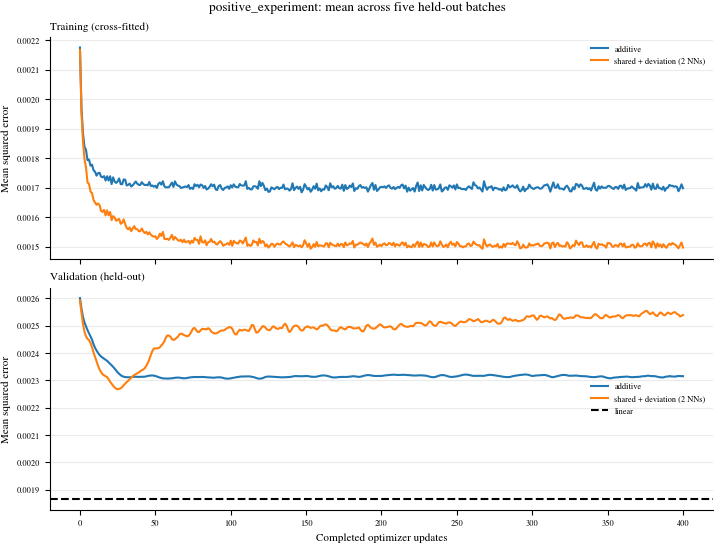

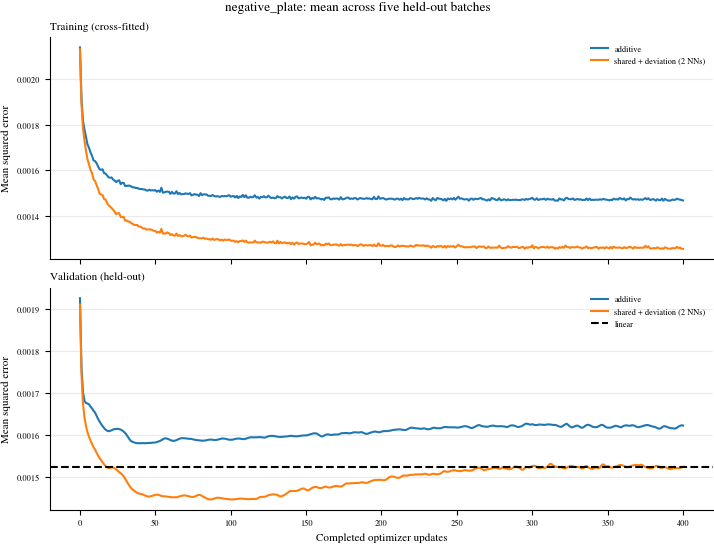

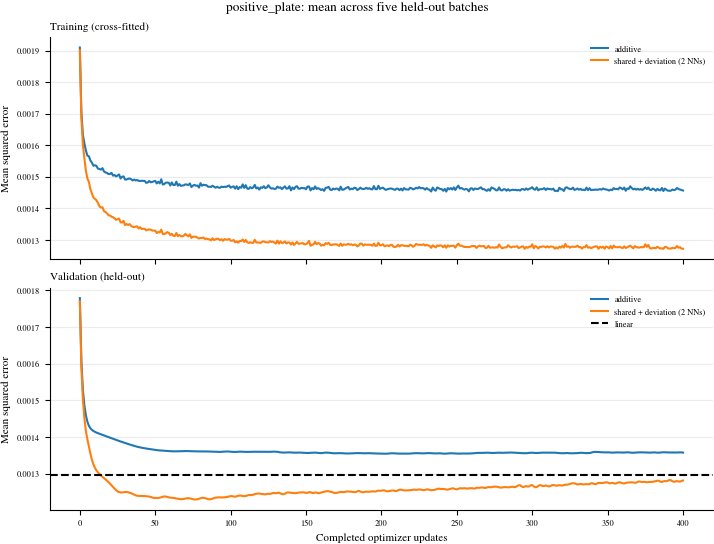

In [6]:
def plot_learning_curves(table, title, path, show=True):
    fig, axes = plt.subplots(2, 1, figsize=(7.2, 5.5), sharex=True, layout="constrained")
    fig.suptitle(title)
    for name, group in table.groupby("model", sort=False):
        group = group.sort_values("step")
        axes[0].plot(group.step, group.training_mse, label=name)
        axes[1].plot(group.step, group.neural_mse, label=name)
    axes[1].axhline(table.linear_mse.mean(), color="black", linestyle="--", label="linear")
    for ax, title in zip(axes, ["Training (cross-fitted)", "Validation (held-out)"]):
        ax.set_title(title, loc="left")
        ax.set_ylabel("Mean squared error")
        ax.ticklabel_format(axis="y", style="plain", useOffset=False)
        ax.grid(axis="y", alpha=0.25)
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(frameon=False)
    axes[1].xaxis.set_major_locator(MaxNLocator(integer=True))
    axes[1].set_xlabel("Completed optimizer updates")
    fig.savefig(path, dpi=180, bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)


for ablation, result in results.items():
    output_dir = result["output_dir"]
    learning_curves = result["curves"]
    curve_dir = output_dir / "plots" / "learning_curves"
    curve_dir.mkdir(parents=True, exist_ok=True)
    with plt.rc_context(STYLE):
        for label, table in learning_curves.groupby("batch", sort=False):
            plot_learning_curves(table, f"{ablation}: held-out {label}",
                                 curve_dir / f"batch_{quote(str(label), safe='')}.png", show=False)
        mean_curve = learning_curves.groupby(["model", "step"], as_index=False)[
            ["training_mse", "neural_mse", "linear_mse"]
        ].mean()
        plot_learning_curves(mean_curve, f"{ablation}: mean across five held-out batches",
                             output_dir / "training_and_validation.png")


## Coverage-conditioned errors

Count training batches containing each scored treatment siRNA. In plate runs the count is of unique experiment–plate pairs. Compare models on the same targets within each ablation. The plate-unit setting changes the total number of available environments and the outer prediction task.

In [7]:
for ablation, result in results.items():
    output_dir = result["output_dir"]
    all_scores = result["scores"]
    differences = all_scores.pivot(
        index=["fold", "batch", "perturbation", "n_training_batches", "n_treatment_crops"],
        columns="model", values="value",
    ).reset_index()
    for name in MODEL_NAMES.values():
        differences[f"{name} minus linear"] = differences[name] - differences[LINEAR]
    differences.to_csv(output_dir / "mse_differences.csv", index=False)
    coverage = all_scores.groupby(["batch", "n_training_batches", "model"]).value.agg(
        siRNAs="size", mse="mean",
    )
    coverage.to_csv(output_dir / "coverage_summary.csv")
    display(coverage)
    print(ablation, "observed training-batch counts:", sorted(differences.n_training_batches.unique()))

    plot_dir = output_dir / "plots" / "by_training_batches"
    plot_dir.mkdir(parents=True, exist_ok=True)
    with plt.rc_context(STYLE):
        for label, table in differences.groupby("batch", sort=False):
            fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True, layout="constrained")
            for ax, name in zip(axes, MODEL_NAMES.values()):
                col = f"{name} minus linear"
                ax.scatter(table.n_training_batches, table[col], s=10, alpha=.3)
                means = table.groupby("n_training_batches")[col].mean()
                ax.plot(means.index, means.values, color="C1", marker="o", label="Mean")
                ax.axhline(0, color="black", linestyle="--", linewidth=1)
                ax.set(title=name, xlabel="Training batches containing the siRNA")
                ax.set_xticks(sorted(table.n_training_batches.unique()))
                ax.grid(axis="y", alpha=.25)
                ax.spines[["top", "right"]].set_visible(False)
            axes[0].set_ylabel("Model MSE minus linear MSE")
            fig.suptitle(str(label))
            fig.savefig(plot_dir / f"batch_{quote(str(label), safe='')}.png", dpi=180, bbox_inches="tight")
            plt.close(fig)

siRNAs       mse
batch    n_training_batches model                                       
HUVEC-05 20                 additive                         2  0.003913
                            linear                           2  0.002045
                            shared + deviation (2 NNs)       2  0.004434
         21                 additive                         8  0.003934
                            linear                           8  0.002096
                            shared + deviation (2 NNs)       8  0.003852
         22                 additive                        36  0.004450
                            linear                          36  0.002845
                            shared + deviation (2 NNs)      36  0.004502
         23                 additive                      1062  0.004670
                            linear                        1062  0.003226
                            shared + deviation (2 NNs)    1062  0.004636
HUVEC-11 20                 additive                         2  0.001244
                            linear                           2  0.001116
                            shared + deviation (2 NNs)       2  0.002055
         21                 additive                         8  0.001041
                            linear                           8  0.001017
                            shared + deviation (2 NNs)       8  0.001075
         22                 additive                        36  0.001713
                            linear                          36  0.001670
                            shared + deviation (2 NNs)      36  0.001897
         23                 additive                      1062  0.001484
                            linear                        1062  0.001428
                            shared + deviation (2 NNs)    1062  0.001612
HUVEC-12 20                 additive                         2  0.001076
                            linear                           2  0.001002
                            shared + deviation (2 NNs)       2  0.000920
         21                 additive                         8  0.001011
                            linear                           8  0.000928
                            shared + deviation (2 NNs)       8  0.001053
         22                 additive                        36  0.001684
                            linear                          36  0.001662
                            shared + deviation (2 NNs)      36  0.001749
         23                 additive                      1062  0.001392
                            linear                        1062  0.001347
                            shared + deviation (2 NNs)    1062  0.001423
HUVEC-19 20                 additive                         2  0.002226
                            linear                           2  0.001697
                            shared + deviation (2 NNs)       2  0.005248
         21                 additive                         8  0.002029
                            linear                           8  0.001963
                            shared + deviation (2 NNs)       8  0.002884
         22                 additive                        36  0.001999
                            linear                          36  0.001484
                            shared + deviation (2 NNs)      36  0.002751
         23                 additive                      1062  0.002149
                            linear                        1062  0.001620
                            shared + deviation (2 NNs)    1062  0.003245
HUVEC-22 20                 additive                         2  0.000750
                            linear                           2  0.000652
                            shared + deviation (2 NNs)       2  0.000653
         21                 additive                         8  0.001337
                            linear                           8  0.001347
                            shared + devi

positive_experiment observed training-batch counts: [np.int64(20), np.int64(21), np.int64(22), np.int64(23)]


siRNAs  \
batch            n_training_batches model                                
HUVEC-02|plate_2 20                 additive                         1   
                                    linear                           1   
                                    shared + deviation (2 NNs)       1   
                 21                 additive                         3   
                                    linear                           3   
                                    shared + deviation (2 NNs)       3   
                 22                 additive                         8   
                                    linear                           8   
                                    shared + deviation (2 NNs)       8   
                 23                 additive                       265   
                                    linear                         265   
                                    shared + deviation (2 NNs)     265   
HUVEC-04|plate_2 20                 additive                         1   
                                    linear                           1   
                                    shared + deviation (2 NNs)       1   
                 21                 additive                         3   
                                    linear                           3   
                                    shared + deviation (2 NNs)       3   
                 22                 additive                         8   
                                    linear                           8   
                                    shared + deviation (2 NNs)       8   
                 23                 additive                       265   
                                    linear                         265   
                                    shared + deviation (2 NNs)     265   
HUVEC-10|plate_1 20                 additive                         1   
                                    linear                           1   
                                    shared + deviation (2 NNs)       1   
                 21                 additive                         3   
                                    linear                           3   
                                    shared + deviation (2 NNs)       3   
                 22                 additive                         8   
                                    linear                           8   
                                    shared + deviation (2 NNs)       8   
                 23                 additive                       265   
                                    linear                         265   
                                    shared + deviation (2 NNs)     265   
HUVEC-14|plate_1 21                 additive                         3   
                                    linear                           3   
                                    shared + deviation (2 NNs)       3   
                 22                 additive                         5   
                                    linear                           5   
                                    shared + deviation (2 NNs)       5   
                 23                 additive                       265   
                                    linear                         265   
                                    shared + deviation (2 NNs)     265   
HUVEC-22|plate_4 20                 additive                         1   
                                    linear                           1   
                                    shared + deviation (2 NNs)       1   
                 21                 additive                         1   
                                    linear                           1   
                                    shared + deviation (2 NNs)       1   
                 22                 additive                         9   
                                    linear                          

negative_plate observed training-batch counts: [np.int64(20), np.int64(21), np.int64(22), np.int64(23)]


siRNAs  \
batch            n_training_batches model                                
HUVEC-02|plate_2 20                 additive                         1   
                                    linear                           1   
                                    shared + deviation (2 NNs)       1   
                 21                 additive                         3   
                                    linear                           3   
                                    shared + deviation (2 NNs)       3   
                 22                 additive                         8   
                                    linear                           8   
                                    shared + deviation (2 NNs)       8   
                 23                 additive                       265   
                                    linear                         265   
                                    shared + deviation (2 NNs)     265   
HUVEC-04|plate_2 20                 additive                         1   
                                    linear                           1   
                                    shared + deviation (2 NNs)       1   
                 21                 additive                         3   
                                    linear                           3   
                                    shared + deviation (2 NNs)       3   
                 22                 additive                         8   
                                    linear                           8   
                                    shared + deviation (2 NNs)       8   
                 23                 additive                       265   
                                    linear                         265   
                                    shared + deviation (2 NNs)     265   
HUVEC-10|plate_1 20                 additive                         1   
                                    linear                           1   
                                    shared + deviation (2 NNs)       1   
                 21                 additive                         3   
                                    linear                           3   
                                    shared + deviation (2 NNs)       3   
                 22                 additive                         8   
                                    linear                           8   
                                    shared + deviation (2 NNs)       8   
                 23                 additive                       265   
                                    linear                         265   
                                    shared + deviation (2 NNs)     265   
HUVEC-14|plate_1 21                 additive                         3   
                                    linear                           3   
                                    shared + deviation (2 NNs)       3   
                 22                 additive                         5   
                                    linear                           5   
                                    shared + deviation (2 NNs)       5   
                 23                 additive                       265   
                                    linear                         265   
                                    shared + deviation (2 NNs)     265   
HUVEC-22|plate_4 20                 additive                         1   
                                    linear                           1   
                                    shared + deviation (2 NNs)       1   
                 21                 additive                         1   
                                    linear                           1   
                                    shared + deviation (2 NNs)       1   
                 22                 additive                         9   
                                    linear                          

positive_plate observed training-batch counts: [np.int64(20), np.int64(21), np.int64(22), np.int64(23)]


## Final results, baseline reference and diagnostic minima

Use the fixed final step for every comparison. Within each ablation, average siRNAs within a held-out batch and give each of the five held-out batches equal weight. The earlier negative-control / experiment run is included as a reference; plate-run averages are from different held-out units. Best observed curve points are descriptive only.

In [8]:
summary_rows = []
for ablation, result in results.items():
    output_dir = result["output_dir"]
    learning_curves = result["curves"]
    last = learning_curves.groupby(["batch", "model"], sort=False).tail(1).set_index(["batch", "model"])
    best = learning_curves.loc[learning_curves.groupby(["batch", "model"]).neural_mse.idxmin()].set_index(["batch", "model"])
    diagnostics = last[["linear_mse", "neural_mse", "training_mse"]].join(
        best[["step", "neural_mse"]].rename(columns={"step": "best_observed_step", "neural_mse": "min_observed_mse"})
    )
    diagnostics.to_csv(output_dir / "curve_diagnostics.csv")
    print(ablation)
    display(result["by_batch"].style.highlight_min(axis=1).format("{:.9f}"))
    summary_rows.append(result["overall"]["mse"].rename(ablation))

if (BASELINE_RUN / "scores.csv").exists():
    baseline_scores = pd.read_csv(BASELINE_RUN / "scores.csv")
    baseline_mean = summary(baseline_scores).reindex(MODEL_ORDER)["mse"]
    summary_rows.insert(0, baseline_mean.rename("negative_experiment (previous run)"))

suite_summary = pd.DataFrame(summary_rows).reindex(columns=MODEL_ORDER)
suite_summary.to_csv(suite_dir / "suite_summary.csv", index_label="ablation")
display(suite_summary.style.highlight_min(axis=1).format("{:.9f}"))
print("Saved all ablation scores, models, curves, coverage analyses and comparisons to", suite_dir)

positive_experiment


,model,linear,additive,shared + deviation (2 NNs)
fold,batch,,,
0,HUVEC-19,0.001618328,0.002143053,0.003230051
1,HUVEC-05,0.003202921,0.004656287,0.004625395
2,HUVEC-22,0.001716864,0.001892893,0.001794028
3,HUVEC-11,0.001431921,0.001487858,0.001617971
4,HUVEC-12,0.001353184,0.001398226,0.001430023


negative_plate


,model,linear,additive,shared + deviation (2 NNs)
fold,batch,,,
0,HUVEC-10|plate_1,0.001429641,0.001488959,0.001397389
1,HUVEC-22|plate_4,0.001408183,0.001599294,0.001450533
2,HUVEC-02|plate_2,0.001648581,0.001917512,0.001740449
3,HUVEC-04|plate_2,0.001293994,0.001224455,0.001288897
4,HUVEC-14|plate_1,0.001844264,0.001886898,0.001749215


positive_plate


,model,linear,additive,shared + deviation (2 NNs)
fold,batch,,,
0,HUVEC-10|plate_1,0.001043009,0.001061101,0.001004173
1,HUVEC-22|plate_4,0.001247679,0.001338644,0.001267372
2,HUVEC-02|plate_2,0.001393898,0.001428567,0.001433881
3,HUVEC-04|plate_2,0.001189483,0.001256100,0.001048999
4,HUVEC-14|plate_1,0.001601455,0.001701388,0.001650799


model,linear,additive,shared + deviation (2 NNs)
negative_experiment (previous run),0.002112694,0.003321412,0.003775208
positive_experiment,0.001864644,0.002315663,0.002539494
negative_plate,0.001524932,0.001623423,0.001525297
positive_plate,0.001295105,0.001357160,0.001281044


Saved all ablation scores, models, curves, coverage analyses and comparisons to /nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_proxy_plate_ablations_20261118T100925512931Z


## Learning and generalization audit

Read the completed curves and saved neural states. Check finite losses and coefficients, verify every final curve point against the reported score, and compare learned network weights with their deterministic initialization. Both branches are checked separately for shared 2NN.

Training change compares the mean of the first 20 recorded losses with the last 20, reducing noise from freshly sampled inner folds. Validation minima and their steps are diagnostic only; all reported model comparisons retain the fixed step-400 endpoint. The plots show every outer fold, including cases where declining training loss accompanies worsening validation error.

folds  folds_training_down  \
ablation            model                                                    
positive_experiment additive                        5                    5   
                    shared + deviation (2 NNs)      5                    5   
negative_plate      additive                        5                    5   
                    shared + deviation (2 NNs)      5                    5   
positive_plate      additive                        5                    5   
                    shared + deviation (2 NNs)      5                    5   

                                                mean_training_drop_pct  \
ablation            model                                                
positive_experiment additive                                     5.481   
                    shared + deviation (2 NNs)                  12.216   
negative_plate      additive                                    13.030   
                    shared + deviation (2 NNs)                  21.835   
positive_plate      additive                                     7.153   
                    shared + deviation (2 NNs)                  13.929   

                                                validation_worse_than_initial  \
ablation            model                                                       
positive_experiment additive                                                0   
                    shared + deviation (2 NNs)                              2   
negative_plate      additive                                                0   
                    shared + deviation (2 NNs)                              0   
positive_plate      additive                                                0   
                    shared + deviation (2 NNs)                              0   

                                                median_best_step  \
ablation            model                                          
positive_experiment additive                               119.0   
                    shared + deviation (2 NNs)              26.0   
negative_plate      additive                                28.0   
                    shared + deviation (2 NNs)              57.0   
positive_plate      additive                               311.0   
                    shared + deviation (2 NNs)              60.0   

                                                mean_final_above_best_pct  \
ablation            model                                                   
positive_experiment additive                                        0.899   
                    shared + deviation (2 NNs)                     13.717   
negative_plate      additive                                        5.325   
                    shared + deviation (2 NNs)                      7.874   
positive_plate      additive                                        1.306   
                    shared + deviation (2 NNs)                      5.428   

                                                worst_final_above_best_pct  
ablation            model                                                   
positive_experiment additive                                         1.663  
                    shared + deviation (2 NNs)                      49.118  
negative_plate      additive                                        11.296  
                    shared + deviation (2 NNs)                      22.185  
positive_plate      additive                                         4.834  
                    shared + deviation (2 NNs)                      14.986

CURVE_AUDIT_SUMMARY
                                                folds  folds_training_down  mean_training_drop_pct  validation_worse_than_initial  median_best_step  mean_final_above_best_pct  worst_final_above_best_pct
ablation            model                                                                                                                                                                                 
positive_experiment additive                        5                    5                   5.481                              0           119.000                      0.899                       1.663
                    shared + deviation (2 NNs)      5                    5                  12.216                              2            26.000                     13.717                      49.118
negative_plate      additive                        5                    5                  13.030                              0            28.000                     

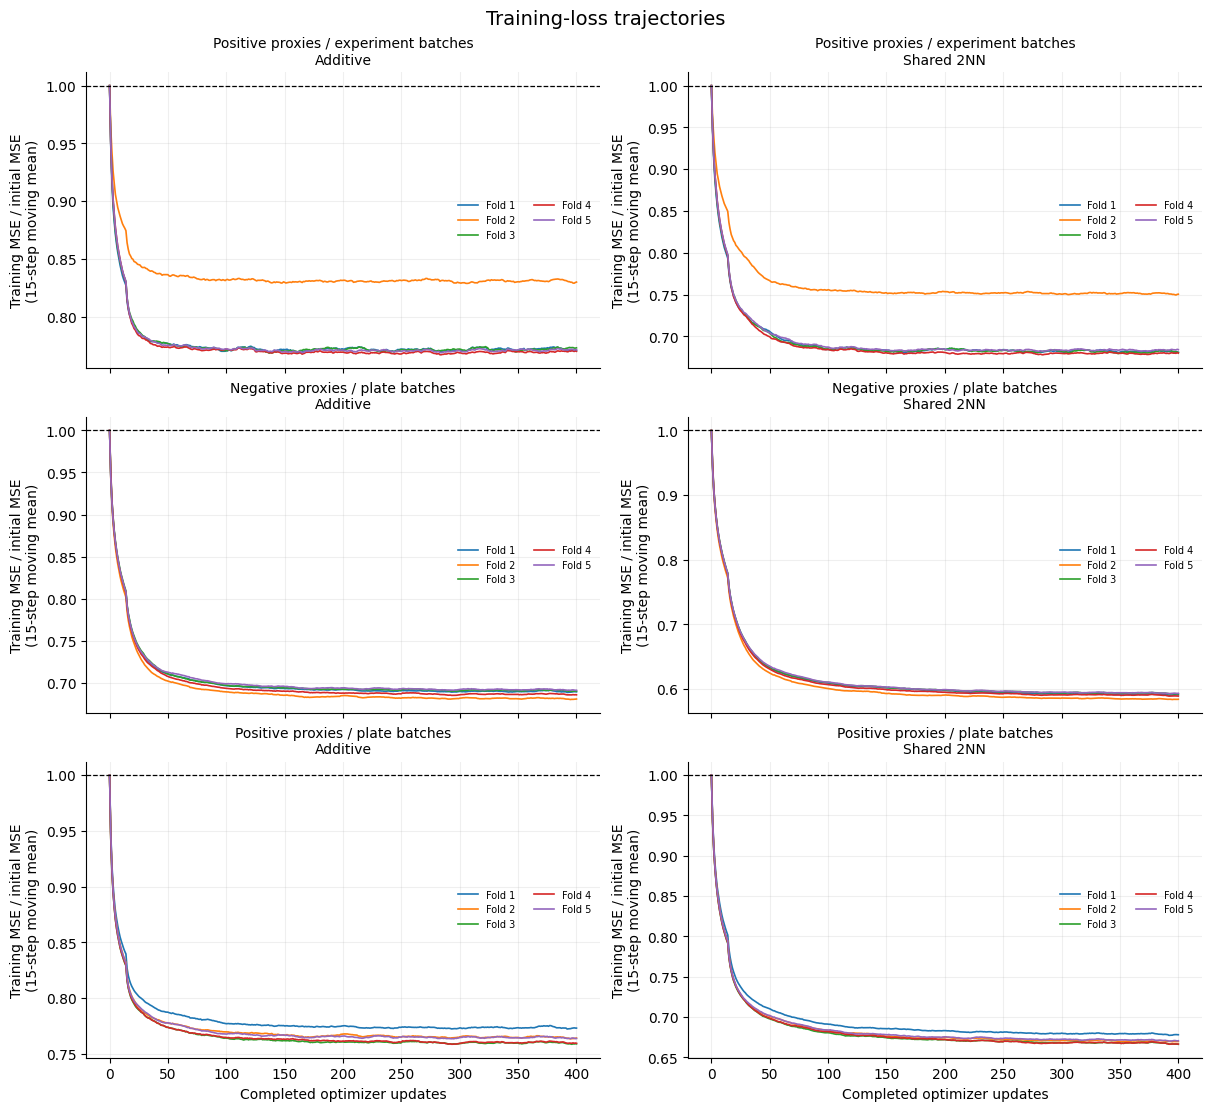

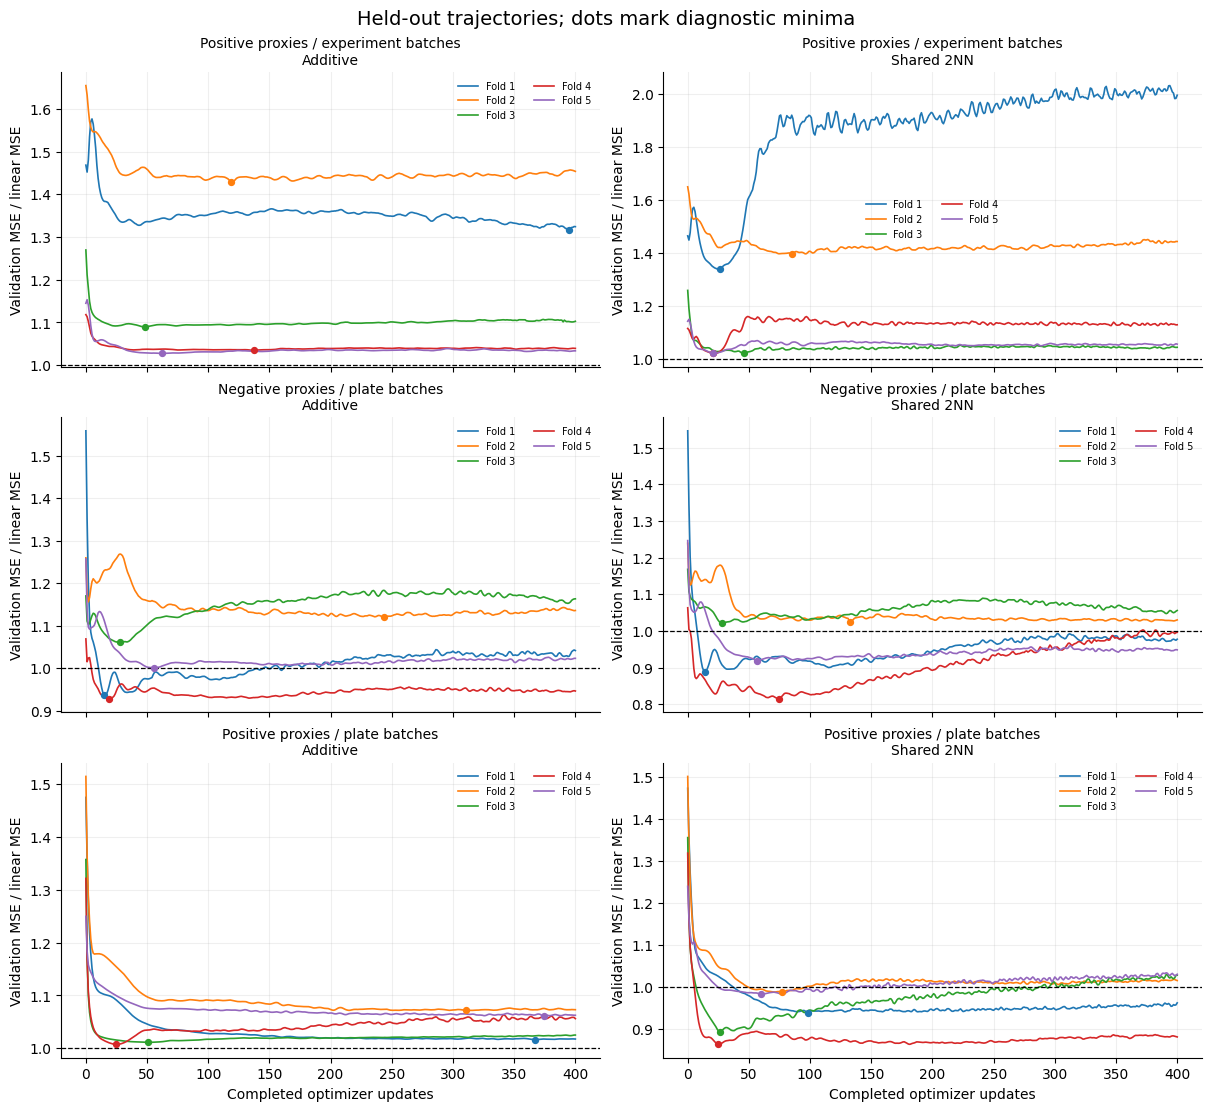

Saved curve audit tables, parameter checks and both overview figures to /nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_proxy_plate_ablations_20261118T100925512931Z


In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from genetic_perturbation_playground.model.proxy_unconfounded_neural import _mlp

torch.set_num_threads(2)
AUDIT_SUITE = Path("/nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_proxy_plate_ablations_20261118T100925512931Z")
AUDIT_ABLATIONS = ["positive_experiment", "negative_plate", "positive_plate"]
AUDIT_MODELS = ["additive", "shared + deviation (2 NNs)"]
curve_audit_rows, parameter_audit_rows, audit_curves = [], [], {}

for ablation in AUDIT_ABLATIONS:
    run = AUDIT_SUITE / ablation
    curves = pd.read_csv(run / "learning_curves.csv")
    scores = pd.read_csv(run / "scores.csv")
    audit_curves[ablation] = curves
    for (batch, model), group in curves.groupby(["batch", "model"], sort=False):
        group = group.sort_values("step")
        assert group.step.tolist() == list(range(401))
        finite = bool(np.isfinite(group[["training_mse", "neural_mse"]]).all().all())
        assert finite
        first, last = group.iloc[0], group.iloc[-1]
        best = group.loc[group.neural_mse.idxmin()]
        final_score = scores.loc[(scores.batch == batch) & (scores.model == model), "value"].mean()
        np.testing.assert_allclose(last.neural_mse, final_score, rtol=1e-9, atol=1e-10)
        early, late = group.training_mse.iloc[:20].mean(), group.training_mse.iloc[-20:].mean()
        curve_audit_rows.append({
            "ablation": ablation, "fold": int(first.fold) + 1, "batch": batch, "model": model,
            "finite_losses": finite,
            "training_initial": first.training_mse, "training_final": last.training_mse,
            "training_first20_mean": early, "training_last20_mean": late,
            "training_drop_pct": 100 * (1 - late / early), "training_down": late < early,
            "validation_initial": first.neural_mse, "validation_final": last.neural_mse,
            "validation_change_pct": 100 * (last.neural_mse / first.neural_mse - 1),
            "validation_worse_than_initial": last.neural_mse > first.neural_mse,
            "best_observed_step": int(best.step), "min_observed_mse": best.neural_mse,
            "final_above_best_pct": 100 * (last.neural_mse / best.neural_mse - 1),
            "final_relative_to_linear": last.neural_mse / last.linear_mse,
        })
    checkpoints = sorted((run / "models").glob("*.pt"))
    assert len(checkpoints) == 10
    for checkpoint in checkpoints:
        saved = torch.load(checkpoint, map_location="cpu", mmap=True, weights_only=False)
        config = saved["config"]
        options = config["neural"]
        assert options["n_steps"] == 400 and config["ablation_id"] == ablation
        for name in ["a", "b"] + (["c"] if "c" in saved else []):
            assert torch.isfinite(saved[name]).all().item(), (checkpoint.name, name)
        branches = [("shared", "psi_state_dict", 0)] if saved["variant"] == "additive" else [
            ("shared", "psi_b_state_dict", 0), ("deviation", "psi_c_state_dict", 1),
        ]
        for branch, key, seed_offset in branches:
            torch.manual_seed(config["neural_seed"] + seed_offset)
            initial = _mlp(saved["b"].shape[-1], options["width_w"], options["depth"], options["n_features_w"]).state_dict()
            final = saved[key]
            assert set(initial) == set(final)
            finite = all(torch.isfinite(v).all().item() for v in final.values())
            initial_ss = sum(v.double().square().sum().item() for v in initial.values())
            delta_ss = sum((final[k].double() - initial[k].double()).square().sum().item() for k in initial)
            parameter_audit_rows.append({
                "ablation": ablation, "batch": saved["held_out_batch"], "variant": saved["variant"],
                "branch": branch, "finite_weights": finite, "weights_changed": delta_ss > 0,
                "relative_parameter_change": np.sqrt(delta_ss / initial_ss),
                "parameter_count": sum(v.numel() for v in initial.values()),
            })
            assert finite and delta_ss > 0

curve_audit = pd.DataFrame(curve_audit_rows)
parameter_audit = pd.DataFrame(parameter_audit_rows)
assert len(curve_audit) == 30 and len(parameter_audit) == 45
curve_audit.to_csv(AUDIT_SUITE / "learning_curve_audit.csv", index=False)
parameter_audit.to_csv(AUDIT_SUITE / "network_parameter_audit.csv", index=False)
audit_summary = curve_audit.groupby(["ablation", "model"], sort=False).agg(
    folds=("batch", "nunique"), folds_training_down=("training_down", "sum"),
    mean_training_drop_pct=("training_drop_pct", "mean"),
    validation_worse_than_initial=("validation_worse_than_initial", "sum"),
    median_best_step=("best_observed_step", "median"),
    mean_final_above_best_pct=("final_above_best_pct", "mean"),
    worst_final_above_best_pct=("final_above_best_pct", "max"),
)
audit_summary.to_csv(AUDIT_SUITE / "learning_curve_audit_summary.csv")
display(audit_summary.round(3))
print("CURVE_AUDIT_SUMMARY")
print(audit_summary.to_string(float_format=lambda x: f"{x:.3f}"))
print("All 30 neural fits have finite losses and coefficients; final curves match reported scores.")
print("All learned weights changed; both branches updated in every shared-2NN fit.")
print("Relative parameter-change range:", parameter_audit.relative_parameter_change.min(),
      parameter_audit.relative_parameter_change.max())

row_titles = {
    "positive_experiment": "Positive proxies / experiment batches",
    "negative_plate": "Negative proxies / plate batches",
    "positive_plate": "Positive proxies / plate batches",
}
column_titles = {"additive": "Additive", "shared + deviation (2 NNs)": "Shared 2NN"}
for kind in ["training", "validation"]:
    fig, axes = plt.subplots(3, 2, figsize=(12, 11), sharex=True, layout="constrained")
    for row, ablation in enumerate(AUDIT_ABLATIONS):
        for col, model in enumerate(AUDIT_MODELS):
            ax = axes[row, col]
            selected = audit_curves[ablation].query("model == @model")
            for (fold, batch), group in selected.groupby(["fold", "batch"], sort=True):
                group = group.sort_values("step")
                color = f"C{int(fold)}"
                if kind == "training":
                    values = group.training_mse.rolling(15, min_periods=1).mean() / group.training_mse.iloc[0]
                else:
                    values = group.neural_mse / group.linear_mse
                ax.plot(group.step, values, color=color, linewidth=1.2, label=f"Fold {int(fold) + 1}")
                if kind == "validation":
                    best = group.loc[group.neural_mse.idxmin()]
                    ax.scatter([best.step], [best.neural_mse / best.linear_mse], s=18, color=color, zorder=3)
            ax.axhline(1, color="black", linestyle="--", linewidth=.9)
            ax.set_title(f"{row_titles[ablation]}\n{column_titles[model]}", fontsize=10)
            ax.set_ylabel("Training MSE / initial MSE\n(15-step moving mean)" if kind == "training" else "Validation MSE / linear MSE")
            ax.grid(alpha=.2)
            ax.spines[["top", "right"]].set_visible(False)
            ax.legend(frameon=False, fontsize=7, ncol=2)
            if row == 2:
                ax.set_xlabel("Completed optimizer updates")
    fig.suptitle("Training-loss trajectories" if kind == "training" else "Held-out trajectories; dots mark diagnostic minima", fontsize=14)
    fig.savefig(AUDIT_SUITE / f"{kind}_curve_audit.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)
print("Saved curve audit tables, parameter checks and both overview figures to", AUDIT_SUITE)

Learning-curve audit interpretation (completed HUVEC ablations)

All 45 model fits completed. All 30 neural fits have finite training/validation losses at every step (0–400), finite saved coefficients, and final validation losses matching the saved per-treatment scores. All 45 learned network branches changed from initialization, including both branches of every shared 2NN fit. Visual inspection shows rapid early training-loss reduction followed by a plateau, without numerical divergence. The first-20 versus last-20 mean training loss decreases in every fit.

Held-out performance does not consistently improve throughout training:

- Positive proxies / experiment batches: additive curves are mostly stable after the early improvement (mean final MSE 0.90% above the best observed checkpoint). Shared 2NN overfits on some folds: HUVEC-19 is best at step 26 and finishes 49.12% worse than that minimum (36.21% worse than initialization); HUVEC-11 finishes 10.56% above its minimum. The shared 2NN median best step is 26.
- Negative proxies / plate batches: both architectures show some late deterioration. Mean final-versus-minimum gaps are 5.32% for additive and 7.87% for shared 2NN; shared 2NN on HUVEC-04/plate 2 finishes 22.19% above its minimum.
- Positive proxies / plate batches: additive curves are mostly stable (mean final-versus-minimum gap 1.31%). Shared 2NN has a 5.43% mean gap, with HUVEC-02/plate 2 reaching its minimum at step 26 and finishing 14.99% above it. At step 400, shared 2NN nevertheless has the lowest five-fold mean MSE: 0.001281044460, versus linear 0.001295104766 (1.09% lower).

These diagnostics support functioning optimization but show that 400 updates can overfit held-out batches, particularly for shared 2NN. All reported model comparisons retain step 400. The outer-fold minima are diagnostic only; a future early-stopping comparison should choose checkpoints using training-side validation, not these held-out folds.

Positive-proxy runs reduce five-fold mean MSE relative to negative proxies for all three models: 11.74% / 30.28% / 32.73% for experiment batches and 15.07% / 16.40% / 16.01% for plate batches (linear / additive / shared 2NN). The proxy change also changes proxy sample count and removes positive controls from the response groups. Plate folds retain the other three plates from the held-out plate's experiment, so experiment- and plate-level MSEs represent different transfer tasks and should not be interpreted as a matched comparison of batch definitions.


Nested hyperparameter tuning of the HUVEC neural bridges

This section retains the same three ablations, treatment-only MSE, five outer held-out batches, proxy selection, count weighting, standardization, neural seed, differentiable ridge loss and five-fold stochastic cross-fitting. It tunes only hyperparameters; no linear skip or new bridge formula is introduced. Earlier fixed-setting results above remain the reference.

For each outer fold, reserve three additional experiments (experiment runs) or four plates, one of each plate number from distinct experiments (plate runs), exclusively from the outer-training data. Every candidate uses the same inner training/validation split. Standardization and all fitted coefficients use inner training only. Select by mean treatment MSE with equal weight per inner validation batch. Outer response values are not used until hyperparameters and the stopping step have been saved.

Ridge screening, 100 updates: additive uses 1e-7, 1e-6, 1e-5, 1e-4, 1e-3. Shared 2NN independently crosses shared/intercept ridge {1e-6,1e-5,1e-4} with deviation ridge {1e-6,1e-4,1e-2}, plus shared/intercept endpoints 1e-7 and 1e-3 at deviation ridge 1e-4. The previous ridge pair is included. Penalties remain lambda times total response count; there is no unpenalized intercept change. The range brackets approximately 0.01% to 53% conditional intercept shrinkage for balanced HUVEC siRNAs.

Capacity screening: at the best inner-validated ridge setting for each model, compare the original 16 features/32 hidden units against 8/16 and 32/64, with depth 2. This is a staged search, not an exhaustive Cartesian grid. Keep learning rate 0.00075 and AdamW weight decay 0.0001 because previous optimization was stable. Promote the two best screened candidates per model to 400 updates, preserving optimizer and RNG state. Select the candidate and checkpoint using inner validation only; checkpoints are 0, 10, 20, 40, 60, 100, 150, 200, 300, 400. Step 0 is a permitted random-feature reference and is explicitly reported if selected.

Refit from scratch on all outer-training data. Record the trajectory to 400 for diagnostics, but restore the checkpoint whose update count was fixed by inner validation before scoring the final model. Both the selected-step and step-400 diagnostic predictions are retained. No checkpoint is selected from outer curves. The previously inspected outer folds are reused for a paired comparison, so this is exploratory rather than a new untouched confirmation set.

All changes and artifacts stay on u434a. Run this section after the model/data helper definitions above; the automated execution reuses those definitions without rerunning the fixed-setting experiments.


In [5]:
import copy
import hashlib
import json
from dataclasses import dataclass, field
from types import SimpleNamespace
from genetic_perturbation_playground.model.batch_transfer import _mean_and_std

HP_REFERENCE = ROOT / "outputs/rxrx1_huvec_proxy_plate_ablations_20261118T100925512931Z"
HP_ABLATIONS = [
    {"id": "positive_experiment", "proxy_mode": "positive_only", "batch_unit": "experiment"},
    {"id": "negative_plate", "proxy_mode": "negative_only", "batch_unit": "plate"},
    {"id": "positive_plate", "proxy_mode": "positive_only", "batch_unit": "plate"},
]
HP_CHECKPOINTS = (0, 10, 20, 40, 60, 100, 150, 200, 300, 400)
HP_SCREEN_STEPS = 100
HP_MAX_STEPS = 400
HP_INNER_SEED = 20261118
hp_base_cfg = OmegaConf.load(HP_REFERENCE / "base_config.yaml")
hp_base_cfg.neural.device = "cuda" if torch.cuda.is_available() else "cpu"
hp_stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
hp_resume = globals().get("HP_RESUME_DIR")
hp_dir = Path(hp_resume) if hp_resume else ROOT / "outputs" / f"rxrx1_huvec_nested_hp_{hp_stamp}"
hp_dir.mkdir(exist_ok=bool(hp_resume))
OmegaConf.save(hp_base_cfg, hp_dir / "base_config.yaml")
hp_manifest = {
    "reference": str(HP_REFERENCE), "outer_folds": 5,
    "inner_seed": HP_INNER_SEED, "inner_experiments": 3, "inner_plates": 4,
    "screen_steps": HP_SCREEN_STEPS, "max_steps": HP_MAX_STEPS,
    "checkpoints": list(HP_CHECKPOINTS), "promote": 2,
    "selection_metric": "equal-inner-batch mean treatment MSE",
    "outer_scores_used_for_selection": False,
    "source_hashes": {str(p): hashlib.sha256(p.read_bytes()).hexdigest() for p in [
        ROOT / "src/genetic_perturbation_playground/model/batch_transfer.py",
        ROOT / "src/genetic_perturbation_playground/model/proxy_unconfounded_neural.py",
        ROOT / "scripts/train_batch_transfer_rxrx1.py",
    ]},
}
(hp_dir / "manifest.json").write_text(json.dumps(hp_manifest, indent=2))
print("HP_RUN_DIR", hp_dir, flush=True)
if "raw_adata" not in globals():
    raw_adata = select_cell_type(load_rxrx1(**hp_base_cfg.embeddings), "HUVEC").copy()
assert raw_adata.obs.cell_type.astype(str).eq("HUVEC").all()
print("HUVEC loaded:", raw_adata.shape, flush=True)


HP_RUN_DIR /nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_nested_hp_20261118T111217794502Z


Loaded /nfs/ghome/live/adhir/genetic_playground/data/rxrx1_phenom_4x4.h5ad
  2,008,160 crops  ×  384 features  |  1,139 perturbations


HUVEC loaded: (944800, 384)


In [6]:
def hp_config(settings, spec):
    return OmegaConf.merge(hp_base_cfg, {
        "name": "rxrx1_nested_hp", "ablation_id": settings["id"],
        "proxy_mode": settings["proxy_mode"], "batch_unit": settings["batch_unit"],
        "bridge_reg": float(spec["ridge"]),
        "neural": {"deviation_reg": spec.get("deviation_ridge"),
                   "n_features_w": int(spec["features"]), "width_w": int(spec["width"]),
                   "n_steps": HP_MAX_STEPS},
    })


def hp_spec(ridge, deviation=None, features=16, width=32):
    return {"ridge": float(ridge), "deviation_ridge": deviation,
            "features": features, "width": width}


def hp_ridge_grid(variant):
    if variant == "additive":
        return [hp_spec(r) for r in [1e-7, 1e-6, 1e-5, 1e-4, 1e-3]]
    specs = [hp_spec(r, d) for r in [1e-6, 1e-5, 1e-4] for d in [1e-6, 1e-4, 1e-2]]
    return [hp_spec(1e-7, 1e-4), *specs, hp_spec(1e-3, 1e-4)]


def hp_inner_batches(outer_train, settings, fold):
    obs = outer_train.obs
    rng = np.random.default_rng(HP_INNER_SEED + fold)
    if settings["batch_unit"] == "experiment":
        return sorted(rng.choice(np.unique(batch_labels(outer_train)), 3, replace=False).tolist())
    choices, used_experiments = [], set()
    for plate in sorted(obs.plate.unique()):
        rows = obs.loc[obs.plate.eq(plate), ["batch", "experiment_batch"]].drop_duplicates()
        rows = rows.loc[~rows.experiment_batch.isin(used_experiments)].sort_values("batch")
        chosen = rows.iloc[int(rng.integers(len(rows)))]
        choices.append(str(chosen.batch)); used_experiments.add(str(chosen.experiment_batch))
    assert len(choices) == 4 and len(used_experiments) == 4
    return choices


def hp_prepare(train, config):
    # Exactly reuse the adapter's standardization and notebook sufficient statistics once.
    adapter = make_notebook_bridge("additive", config)
    control = is_control(train)
    adapter.w_mean_, adapter.w_std_ = _mean_and_std(_dense(train.X[control]))
    adapter.y_mean_ = np.asarray(train.X[~control].mean(axis=0)).ravel()
    standardised = adapter._standardise(train)
    stats = notebook_bridge_data(standardised, config.weight_by_cells)
    masks = [stats.batch == b for b in range(len(stats.ctrl))]
    eye = np.eye(len(stats.perturbations))
    converter = NeuralPerXEmbeddingBridge(device=config.neural.device)
    grouped = converter._to_tensors(
        [eye[stats.pert[m]] for m in masks], [stats.y[m] for m in masks],
        stats.ctrl, [stats.weight[m] for m in masks],
    )
    additive = SimpleNamespace(c=grouped.c, cy=grouped.cy, cyy=grouped.cyy,
        w_envs=grouped.w_envs, cy_env=grouped.cy.sum(dim=0), cy_all=grouped.cy.sum(dim=1))
    return SimpleNamespace(
        data={"additive": additive, "shared_2nn": grouped},
        perturbations=stats.perturbations, w_mean=adapter.w_mean_, w_std=adapter.w_std_,
        y_mean=adapter.y_mean_, config=config,
    )


def hp_queries(data, labels, prepared):
    queries = []
    batches = batch_labels(data)
    eye = np.eye(len(prepared.perturbations))
    for label in labels:
        test = data[batches == label]
        names, truth, compact = checkpoint_inputs(test, prepared.perturbations)
        assert len(names) > 0
        x = eye[np.searchsorted(prepared.perturbations, names)]
        w = (_dense(compact.X[is_control(compact)]).astype(float) - prepared.w_mean) / prepared.w_std
        queries.append({"batch": label, "names": names, "truth": truth, "x": x, "w": w})
    return queries


@dataclass
class HPCandidate:
    variant: str
    spec: dict
    config: object
    model: object
    optimizer: object
    rng: torch.Tensor
    initial: dict
    candidate_id: str
    step: int = 0
    records: list = field(default_factory=list)
    train_records: list = field(default_factory=list)
    best_mse: float = float("inf")
    best_step: int = 0
    failed: str | None = None
    captured: dict = field(default_factory=dict)


def hp_candidate(variant, spec, settings, data, candidate_id):
    config = hp_config(settings, spec)
    options = OmegaConf.to_container(config.neural, resolve=True)
    options.pop("per_perturbation", None)
    if variant == "additive": options.pop("deviation_reg", None)
    options.update(reg=config.bridge_reg, seed=config.neural_seed)
    model = MODEL_CLASSES[variant](**options)
    torch.manual_seed(model.seed)
    model._build_networks(data)
    initial = {k: v.detach().cpu().clone() for k, v in model.psi_.state_dict().items()}
    optimizer = torch.optim.AdamW([*model.phi_.parameters(), *model.psi_.parameters()],
                                 lr=model.lr, weight_decay=model.weight_decay)
    return HPCandidate(variant, copy.deepcopy(spec), config, model, optimizer,
                       torch.get_rng_state().clone(), initial, candidate_id)


def hp_advance(candidate, data, queries, y_mean, target_step, capture_steps=()):
    # Identical AdamW and ridge objective to the existing loop. Preserve state on promotion.
    torch.set_rng_state(candidate.rng)
    model, optimizer = candidate.model, candidate.optimizer
    recorded = {r["step"] for r in candidate.records}
    def record():
        model._solve_A(data)
        with torch.no_grad(), torch.random.fork_rng(devices=[]):
            objective = float(model._training_loss(data).item())
        assert np.isfinite(objective)
        errors = []
        for query in queries:
            prediction = model.predict(query["x"], query["w"]) + y_mean
            value = float(mse(prediction, query["truth"]).mean())
            assert np.isfinite(value)
            errors.append(value)
            candidate.records.append({"candidate": candidate.candidate_id, "variant": candidate.variant,
                **candidate.spec, "step": candidate.step, "batch": query["batch"],
                "training_mse": objective, "validation_mse": value})
        value = float(np.mean(errors))
        if value < candidate.best_mse:
            candidate.best_mse, candidate.best_step = value, candidate.step
        if candidate.step in capture_steps:
            candidate.captured[candidate.step] = {
                k: v.detach().cpu().clone() for k, v in model.psi_.state_dict().items()}
    if candidate.step not in recorded: record()
    for step in range(candidate.step, target_step):
        optimizer.zero_grad()
        loss = model._training_loss(data)
        if not torch.isfinite(loss): raise FloatingPointError("Non-finite optimization loss")
        loss.backward()
        optimizer.step()
        candidate.train_records.append({"step": step, "training_mse": float(loss.item())})
        candidate.step = step + 1
        if candidate.step in HP_CHECKPOINTS or candidate.step in capture_steps or candidate.step == target_step:
            record()
    candidate.rng = torch.get_rng_state().clone()
    assert all(torch.isfinite(v).all().item() for v in model.psi_.state_dict().values())
    coefficient_keys = (["A_"] if candidate.variant == "per_x" else
                        ["a_", "b_"] + (["c_"] if candidate.variant == "shared_2nn" else []))
    for key in coefficient_keys:
        assert torch.isfinite(getattr(model, key)).all().item()


def hp_trial(candidate, prepared, queries, target_step, directory):
    start = time.perf_counter()
    try:
        hp_advance(candidate, prepared.data[candidate.variant], queries, prepared.y_mean, target_step)
    except (FloatingPointError, torch.linalg.LinAlgError) as exc:
        candidate.failed = repr(exc)
        candidate.best_mse = float("inf")
    pd.DataFrame(candidate.records).to_csv(directory / f"{candidate.candidate_id}_curves.csv", index=False)
    pd.DataFrame(candidate.train_records).to_csv(directory / f"{candidate.candidate_id}_training.csv", index=False)
    status = {"candidate": candidate.candidate_id, "variant": candidate.variant, **candidate.spec,
              "completed_step": candidate.step, "best_step": candidate.best_step,
              "inner_mse": candidate.best_mse, "failed": candidate.failed,
              "last_stage_seconds": time.perf_counter() - start}
    (directory / f"{candidate.candidate_id}_status.json").write_text(json.dumps(status, indent=2))
    print("HP_TRIAL", json.dumps(status), flush=True)
    return candidate


def hp_rank(candidates):
    return sorted([c for c in candidates if c.failed is None],
                  key=lambda c: (c.best_mse, c.best_step, c.spec["features"], c.candidate_id))


def hp_search(variant, settings, prepared, queries, directory):
    directory.mkdir(parents=True, exist_ok=True)
    cached = directory / f"{variant}_selection.json"
    if cached.exists():
        print("HP_REUSE_SELECTION", settings["id"], str(cached), flush=True)
        return json.loads(cached.read_text())
    candidates = []
    for i, spec in enumerate(hp_ridge_grid(variant)):
        candidate = hp_candidate(variant, spec, settings, prepared.data[variant], f"{variant}_ridge_{i:02d}")
        candidates.append(hp_trial(candidate, prepared, queries, HP_SCREEN_STEPS, directory))
    ridge_winner = hp_rank(candidates)[0]
    for features, width in [(8, 16), (32, 64)]:
        spec = {**ridge_winner.spec, "features": features, "width": width}
        candidate = hp_candidate(variant, spec, settings, prepared.data[variant], f"{variant}_capacity_{features}")
        candidates.append(hp_trial(candidate, prepared, queries, HP_SCREEN_STEPS, directory))
    promoted = hp_rank(candidates)[:2]
    assert len(promoted) == 2
    promoted_ids = {c.candidate_id for c in promoted}
    screening = pd.DataFrame([{**c.spec, "candidate": c.candidate_id, "inner_mse": c.best_mse,
                              "best_step": c.best_step, "promoted": c.candidate_id in promoted_ids,
                              "failed": c.failed} for c in candidates])
    screening.to_csv(directory / f"{variant}_screening.csv", index=False)
    candidates = promoted
    del candidate, ridge_winner
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    for candidate in promoted:
        hp_trial(candidate, prepared, queries, HP_MAX_STEPS, directory)
    selected = hp_rank(promoted)[0]
    selection = {"variant": variant, **selected.spec, "candidate": selected.candidate_id,
                 "selected_step": selected.best_step, "inner_mse": selected.best_mse,
                 "n_candidates": len(screening), "promoted": sorted(promoted_ids)}
    (directory / f"{variant}_selection.json").write_text(json.dumps(selection, indent=2))
    print("HP_SELECTED", json.dumps(selection), flush=True)
    return selection


def hp_save_model(candidate, prepared, selected_step, destination, selection, outer_label, fold):
    model = candidate.model
    payload = {"variant": candidate.variant, "config": OmegaConf.to_container(candidate.config, resolve=False),
        "selection": selection, "selected_step": selected_step, "diagnostic_max_steps": candidate.step,
        "held_out_batch": outer_label, "fold": fold, "perturbations": prepared.perturbations.tolist(),
        "a": model.a_.detach().cpu(), "b": model.b_.detach().cpu(),
        "w_mean": torch.as_tensor(prepared.w_mean), "w_std": torch.as_tensor(prepared.w_std),
        "y_mean": torch.as_tensor(prepared.y_mean)}
    payload["config"]["neural"]["n_steps"] = selected_step
    if candidate.variant == "shared_2nn":
        payload.update(c=model.c_.detach().cpu(),
            psi_b_state_dict={k:v.detach().cpu() for k,v in model.psi_b_.state_dict().items()},
            psi_c_state_dict={k:v.detach().cpu() for k,v in model.psi_c_.state_dict().items()})
    else:
        payload["psi_state_dict"] = {k:v.detach().cpu() for k,v in model.psi_.state_dict().items()}
    torch.save(payload, destination)


In [7]:
# Check that the resumable tuning loop reproduces the existing training algorithm.
check_rng = np.random.default_rng(77)
check_g, check_e, check_j = 4, 7, 3
check_x = [np.eye(check_g) for _ in range(check_e)]
check_y = [check_rng.normal(size=(check_g, check_j)) for _ in range(check_e)]
check_w = [check_rng.normal(size=(9, check_j)) for _ in range(check_e)]
check_counts = [check_rng.integers(2, 10, size=check_g) for _ in range(check_e)]
check_settings = HP_ABLATIONS[0]
check_spec = hp_spec(1e-4, 1e-3, features=4, width=8)
check_rows = []
for variant in MODEL_CLASSES:
    config = hp_config(check_settings, check_spec)
    options = OmegaConf.to_container(config.neural, resolve=True)
    options.pop("per_perturbation", None)
    if variant == "additive": options.pop("deviation_reg", None)
    options.update(reg=config.bridge_reg, seed=config.neural_seed, device="cpu", n_steps=8)
    reference = MODEL_CLASSES[variant](**options)
    reference.fit(check_x, check_y, check_w, check_counts)
    data = reference._to_tensors(check_x, check_y, check_w, check_counts)
    candidate = hp_candidate(variant, check_spec, check_settings, data, "parity")
    # Build with identical CPU options regardless of the production GPU setting.
    candidate.model = MODEL_CLASSES[variant](**options)
    torch.manual_seed(candidate.model.seed)
    candidate.model._build_networks(data)
    candidate.optimizer = torch.optim.AdamW(candidate.model.psi_.parameters(),
        lr=candidate.model.lr, weight_decay=candidate.model.weight_decay)
    candidate.rng = torch.get_rng_state().clone()
    query = [{"batch": "synthetic", "x": check_x[0], "w": check_w[0], "truth": check_y[0]}]
    hp_advance(candidate, data, query, 0., 3)
    hp_advance(candidate, data, query, 0., 8)
    for key, value in reference.psi_.state_dict().items():
        torch.testing.assert_close(candidate.model.psi_.state_dict()[key], value, rtol=1e-6, atol=1e-7)
    np.testing.assert_allclose(candidate.model.predict(check_x[0], check_w[0]),
                               reference.predict(check_x[0], check_w[0]), rtol=1e-6, atol=1e-8)
    check_rows.append({"variant": variant, "resumed_matches_original": True})
    del candidate, reference, data
pd.DataFrame(check_rows).to_csv(hp_dir / "implementation_checks.csv", index=False)
assert len(hp_ridge_grid("additive")) == 5 and len(hp_ridge_grid("shared_2nn")) == 11
for variant in MODEL_CLASSES:
    specs = hp_ridge_grid(variant)
    assert len({json.dumps(s, sort_keys=True) for s in specs}) == len(specs)
    assert all(s["ridge"] > 0 and (variant == "additive" or s["deviation_ridge"] > 0) for s in specs)
    assert any(s["ridge"] == 1e-4 and (variant == "additive" or s["deviation_ridge"] == 1e-4) for s in specs)
print("Resumable optimizer parity and hyperparameter-grid checks passed.", flush=True)

# Preserve Hydra metadata without resolving its CLI-only timestamp resolver.
assert OmegaConf.to_container(hp_config(HP_ABLATIONS[0], hp_spec(1e-4)), resolve=False)["bridge_reg"] == 1e-4


Resumable optimizer parity and hyperparameter-grid checks passed.


In [8]:
hp_score_rows = [pd.read_csv(hp_dir / "scores.csv")] if (hp_dir / "scores.csv").exists() else []
hp_selection_rows = pd.read_csv(hp_dir / "selected_hyperparameters.csv").to_dict("records") if (hp_dir / "selected_hyperparameters.csv").exists() else []
hp_curve_rows = [pd.read_csv(hp_dir / "outer_learning_curves.csv")] if (hp_dir / "outer_learning_curves.csv").exists() else []
hp_weight_rows = pd.read_csv(hp_dir / "network_parameter_audit.csv").to_dict("records") if (hp_dir / "network_parameter_audit.csv").exists() else []
hp_split_rows = json.loads((hp_dir / "splits.json").read_text()) if (hp_dir / "splits.json").exists() else []
for settings in HP_ABLATIONS:
    ablation_dir = hp_dir / settings["id"]
    ablation_dir.mkdir(exist_ok=True)
    config = hp_config(settings, hp_spec(1e-4, 1e-4))
    adata = prepare_ablation(raw_adata, config)
    batches = batch_labels(adata)
    outer_folds = pd.read_csv(HP_REFERENCE / settings["id"] / "selected_folds.csv")
    original_scores = pd.read_csv(HP_REFERENCE / settings["id"] / "scores.csv")
    for fold, outer_label in outer_folds[["fold", "batch"]].itertuples(index=False, name=None):
        fold_dir = ablation_dir / f"fold_{fold + 1}"
        fold_dir.mkdir(exist_ok=True)
        if (fold_dir / "completed.json").exists():
            print("HP_REUSE_COMPLETED_FOLD", settings["id"], fold + 1, flush=True)
            continue
        outer_train = adata[batches != outer_label]
        inner_labels = hp_inner_batches(outer_train, settings, fold)
        train_batches = batch_labels(outer_train)
        inner_train = outer_train[~np.isin(train_batches, inner_labels)]
        assert outer_label not in inner_labels
        assert outer_label not in set(batch_labels(inner_train))
        assert set(inner_labels).isdisjoint(set(batch_labels(inner_train)))
        split = {"ablation": settings["id"], "fold": fold, "outer_batch": outer_label,
                 "inner_validation_batches": inner_labels,
                 "inner_training_batches": sorted(np.unique(batch_labels(inner_train)).tolist()),
                 "outer_training_batches": sorted(np.unique(train_batches).tolist())}
        (fold_dir / "split.json").write_text(json.dumps(split, indent=2))
        hp_split_rows = [s for s in hp_split_rows if not (s["ablation"] == settings["id"] and s["fold"] == fold)]
        hp_split_rows.append(split)
        (hp_dir / "splits.json").write_text(json.dumps(hp_split_rows, indent=2))
        print("HP_FOLD_START", settings["id"], fold + 1, outer_label, "inner validation", inner_labels, flush=True)
        prepared = hp_prepare(inner_train, config)
        queries = hp_queries(outer_train, inner_labels, prepared)
        selections = {}
        for variant in MODEL_CLASSES:
            selections[variant] = hp_search(variant, settings, prepared, queries, fold_dir / "trials")
            row = {"ablation": settings["id"], "fold": fold, "batch": outer_label, **selections[variant]}
            hp_selection_rows.append(row)
            pd.DataFrame(hp_selection_rows).drop_duplicates(["ablation", "fold", "variant"], keep="last").to_csv(hp_dir / "selected_hyperparameters.csv", index=False)
            gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()
        # Selection is locked on disk before any outer response is scored.
        (fold_dir / "locked_selection.json").write_text(json.dumps(selections, indent=2))
        del prepared, queries, inner_train
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        test = adata[batches == outer_label]
        linear = BatchTransferModel(standardise_w=config.standardise_w).fit(outer_train)
        linear_scores = score_batch({"linear": linear}, test).assign(
            batch=outer_label, fold=fold, ablation=settings["id"], selected_step=np.nan)
        ref = original_scores.query("batch == @outer_label and model == 'linear'")
        merged = linear_scores.merge(ref, on=["perturbation", "metric"], suffixes=("_new", "_old"), validate="one_to_one")
        assert len(merged) == len(linear_scores) == len(ref)
        np.testing.assert_allclose(merged.value_new, merged.value_old, rtol=1e-9, atol=1e-11)
        training_counts = training_batch_counts(outer_train)
        crop_counts = test.obs.loc[test.obs.well_type.eq("treatment"), "perturbation"].value_counts()
        linear_scores["n_training_batches"] = linear_scores.perturbation.map(training_counts)
        linear_scores["n_treatment_crops"] = linear_scores.perturbation.map(crop_counts)
        hp_score_rows.append(linear_scores)
        del linear
        prepared = hp_prepare(outer_train, config)
        queries = hp_queries(test, [outer_label], prepared)
        assert len(queries) == 1
        for variant, selection in selections.items():
            spec = {k:selection[k] for k in ["ridge", "deviation_ridge", "features", "width"]}
            candidate = hp_candidate(variant, spec, settings, prepared.data[variant], "outer_refit")
            stop = int(selection["selected_step"])
            hp_advance(candidate, prepared.data[variant], queries, prepared.y_mean, HP_MAX_STEPS, capture_steps=[stop])
            curves = pd.DataFrame(candidate.records).assign(
                ablation=settings["id"], fold=fold, model=MODEL_NAMES[variant], selected_step=stop,
                linear_mse=float(linear_scores.value.mean()))
            curves.to_csv(fold_dir / f"{variant}_outer_curves.csv", index=False)
            pd.DataFrame(candidate.train_records).to_csv(fold_dir / f"{variant}_training.csv", index=False)
            hp_curve_rows.append(curves)
            candidate.model.psi_.load_state_dict(candidate.captured[stop])
            candidate.model._solve_A(prepared.data[variant])
            adapter = make_notebook_bridge(variant, candidate.config)
            adapter.w_mean_, adapter.w_std_, adapter.y_mean_ = prepared.w_mean, prepared.w_std, prepared.y_mean
            adapter.model.perturbations_ = prepared.perturbations
            adapter.model.bridge_ = candidate.model
            scored = score_batch({MODEL_NAMES[variant]: adapter}, test).assign(
                batch=outer_label, fold=fold, ablation=settings["id"], selected_step=stop)
            scored["n_training_batches"] = scored.perturbation.map(training_counts)
            scored["n_treatment_crops"] = scored.perturbation.map(crop_counts)
            assert set(scored.perturbation) == set(linear_scores.perturbation)
            np.testing.assert_allclose(scored.value.mean(), curves.loc[curves.step.eq(stop), "validation_mse"].item(),
                                       rtol=1e-6, atol=1e-10)
            hp_score_rows.append(scored)
            hp_save_model(candidate, prepared, stop, fold_dir / f"{variant}_selected.pt", selection, outer_label, fold)
            for branch in (["shared"] if variant == "additive" else ["b", "c"]):
                final_state = candidate.model.psi_.state_dict()
                keys = [k for k in final_state if variant == "additive" or k.startswith(branch + ".")]
                delta = sum((final_state[k].detach().cpu().double() - candidate.initial[k].double()).square().sum().item() for k in keys)
                norm = sum(candidate.initial[k].double().square().sum().item() for k in keys)
                assert all(torch.isfinite(final_state[k]).all().item() for k in keys)
                assert (delta > 0) if stop > 0 else (delta == 0)
                hp_weight_rows.append({"ablation": settings["id"], "fold": fold, "batch": outer_label,
                    "variant": variant, "branch": branch, "selected_step": stop,
                    "finite_weights": True, "relative_parameter_change": float(np.sqrt(delta / norm))})
            print("HP_OUTER_RESULT", settings["id"], fold + 1, outer_label, variant,
                  "step", stop, "MSE", float(scored.value.mean()), "linear", float(linear_scores.value.mean()), flush=True)
            pd.concat(hp_score_rows, ignore_index=True).drop_duplicates(["ablation", "batch", "model", "perturbation", "metric"], keep="last").to_csv(hp_dir / "scores.csv", index=False)
            pd.concat(hp_curve_rows, ignore_index=True).drop_duplicates(["ablation", "batch", "model", "step"], keep="last").to_csv(hp_dir / "outer_learning_curves.csv", index=False)
            pd.DataFrame(hp_weight_rows).drop_duplicates(["ablation", "batch", "variant", "branch"], keep="last").to_csv(hp_dir / "network_parameter_audit.csv", index=False)
            del adapter, candidate
            gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()
        del prepared, queries, outer_train, test
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        (fold_dir / "completed.json").write_text(json.dumps({"completed_utc": datetime.now(timezone.utc).isoformat()}))
        print("HP_FOLD_FINISHED", settings["id"], fold + 1, flush=True)
    del adata
    gc.collect()
print("HP_ALL_FITS_COMPLETE", hp_dir, flush=True)


HP_FOLD_START positive_experiment 1 HUVEC-19 inner validation ['HUVEC-02', 'HUVEC-08', 'HUVEC-15']


HP_REUSE_SELECTION positive_experiment /nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_nested_hp_20261118T111217794502Z/positive_experiment/fold_1/trials/additive_selection.json


HP_REUSE_SELECTION positive_experiment /nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_nested_hp_20261118T111217794502Z/positive_experiment/fold_1/trials/shared_2nn_selection.json


HP_OUTER_RESULT positive_experiment 1 HUVEC-19 additive step 400 MSE 0.00245646103234713 linear 0.0016183281570100643


HP_OUTER_RESULT positive_experiment 1 HUVEC-19 shared_2nn step 40 MSE 0.0021383068808134512 linear 0.0016183281570100643


HP_FOLD_FINISHED positive_experiment 1


... (417 outputs left out)

HP_OUTER_RESULT positive_plate 5 HUVEC-14|plate_1 additive step 150 MSE 0.0017110276561744062 linear 0.0016014545161797977


HP_OUTER_RESULT positive_plate 5 HUVEC-14|plate_1 shared_2nn step 150 MSE 0.0015713481137973942 linear 0.0016014545161797977


HP_FOLD_FINISHED positive_plate 5


HP_ALL_FITS_COMPLETE /nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_nested_hp_20261118T111217794502Z


model,linear,additive,shared + deviation (2 NNs)
ablation,,,
negative_plate,0.001524932,0.001698423,0.001502331
positive_experiment,0.001864644,0.002513662,0.002351592
positive_plate,0.001295105,0.001326569,0.001228261


TUNED_AVERAGES model                  linear  additive  shared + deviation (2 NNs)
ablation                                                           
negative_plate       0.001525  0.001698                    0.001502
positive_experiment  0.001865  0.002514                    0.002352
positive_plate       0.001295  0.001327                    0.001228


previous                                          tuned  \
model                  linear  additive shared + deviation (2 NNs)    linear   
positive_experiment  0.001865  0.002316                   0.002539  0.001865   
negative_plate       0.001525  0.001623                   0.001525  0.001525   
positive_plate       0.001295  0.001357                   0.001281  0.001295   

                                                         change_pct            \
model                additive shared + deviation (2 NNs)     linear  additive   
positive_experiment  0.002514                   0.002352        0.0  8.550425   
negative_plate       0.001698                   0.001502        0.0  4.619839   
positive_plate       0.001327                   0.001228        0.0 -2.254083   

                                                
model               shared + deviation (2 NNs)  
positive_experiment                  -7.399197  
negative_plate                       -1.505624  
positive_plate                       -4.120353

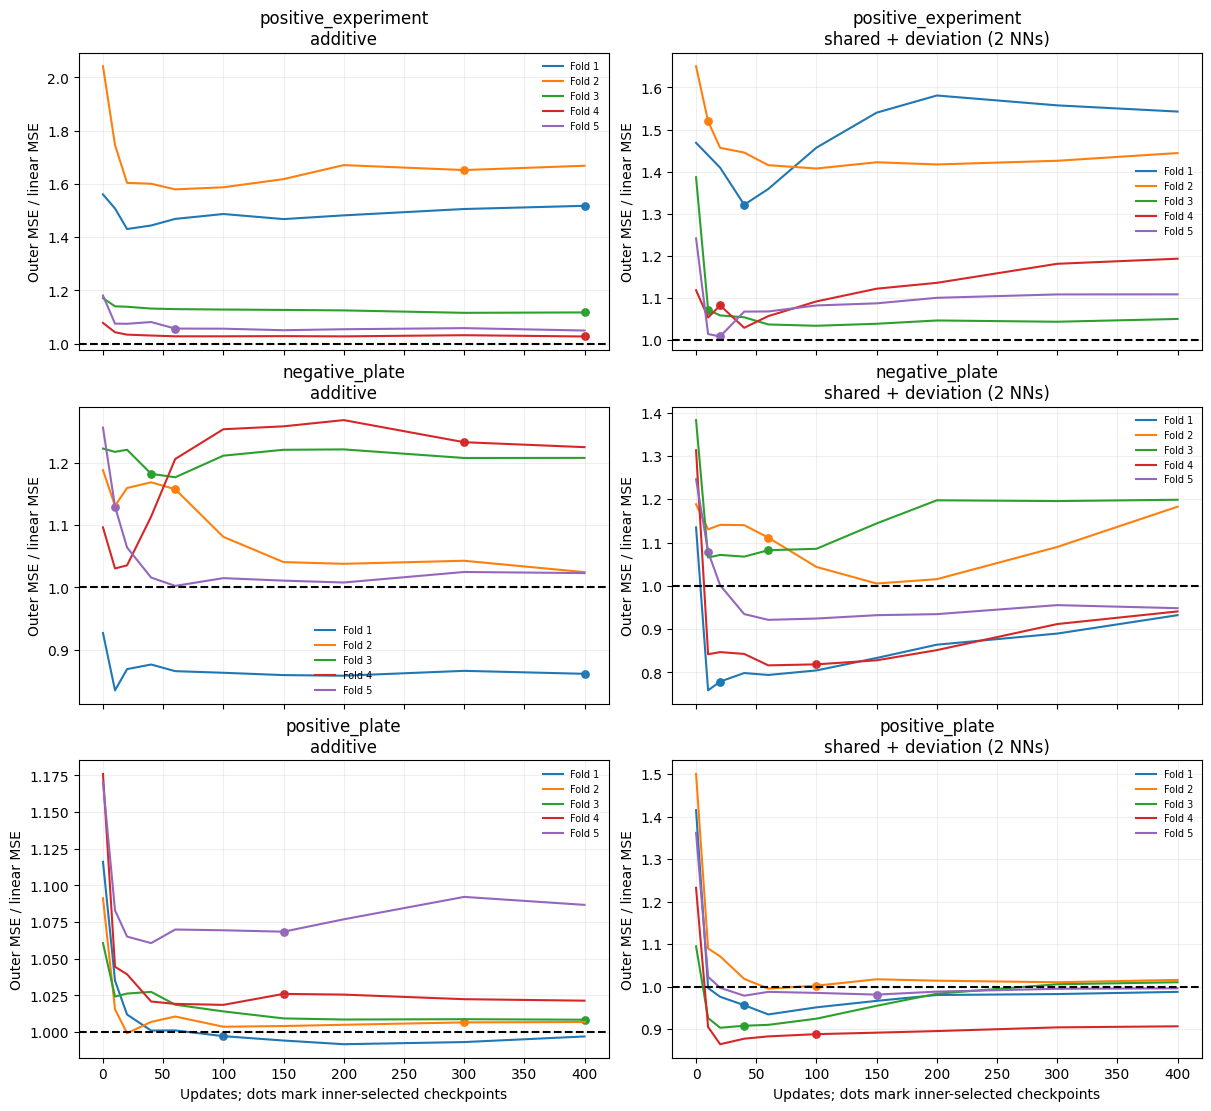

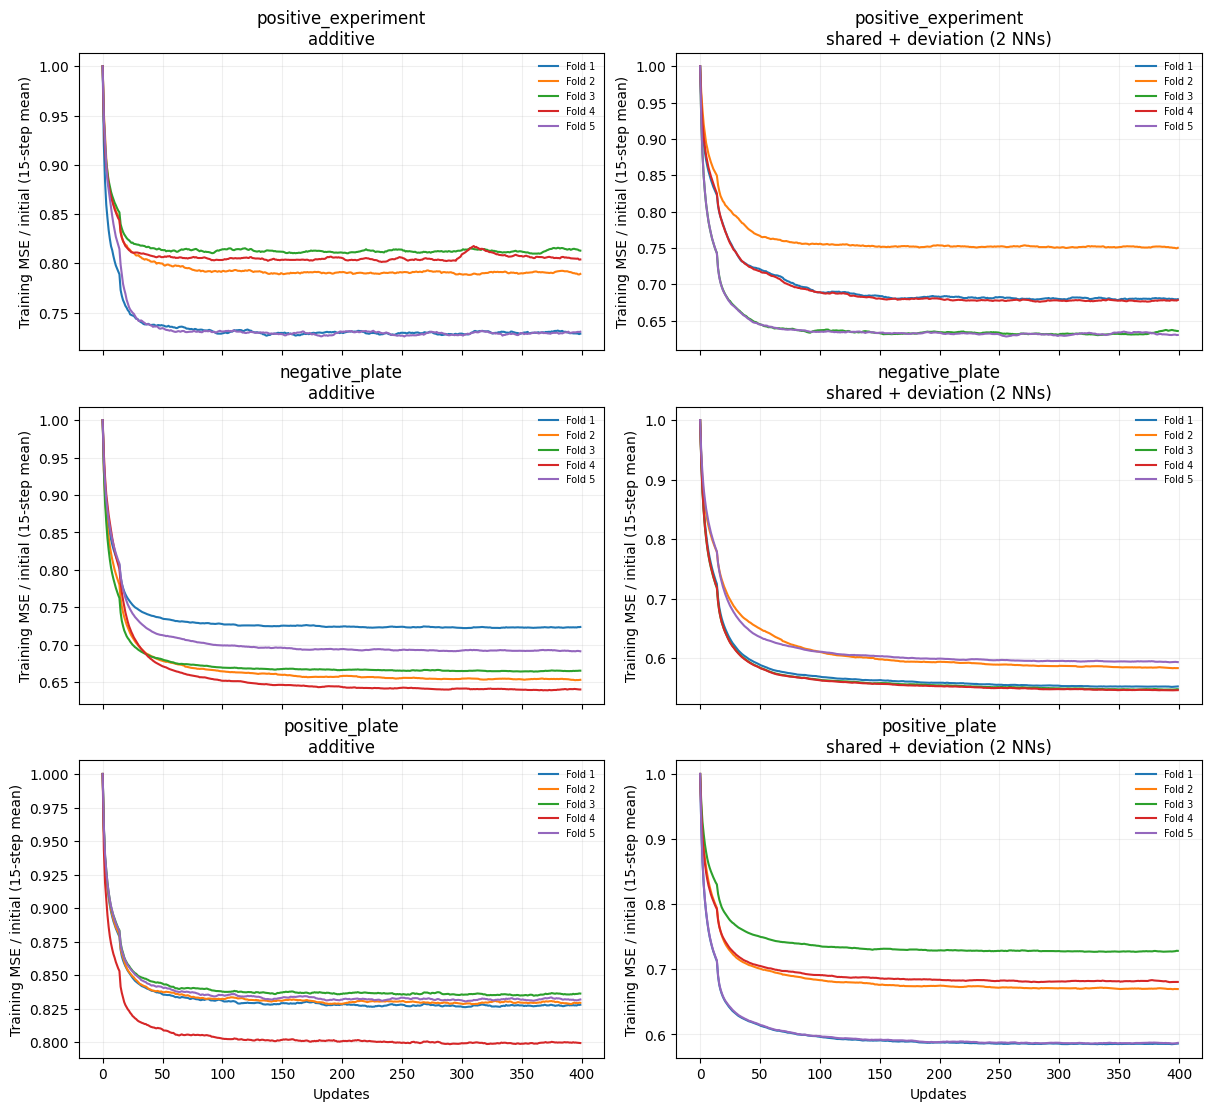

Selected hyperparameters:            ablation  fold            batch    variant        ridge  deviation_ridge  features  width              candidate  selected_step  inner_mse  n_candidates                                            promoted
positive_experiment     0         HUVEC-19   additive 1.000000e-05              NaN        16     32      additive_ridge_02            400   0.001490             7       ['additive_capacity_32', 'additive_ridge_02']
positive_experiment     0         HUVEC-19 shared_2nn 1.000000e-04         0.010000        16     32    shared_2nn_ridge_09             40   0.001517            13      ['shared_2nn_ridge_06', 'shared_2nn_ridge_09']
positive_experiment     1         HUVEC-05   additive 1.000000e-05              NaN        16     32      additive_ridge_02            300   0.001857             7          ['additive_ridge_02', 'additive_ridge_03']
positive_experiment     1         HUVEC-05 shared_2nn 1.000000e-04         0.000100        16     32    shared

Completed nested tuning and curve diagnostics: /nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_nested_hp_20261118T111217794502Z


In [9]:
hp_scores = pd.read_csv(hp_dir / "scores.csv")
hp_curves = pd.read_csv(hp_dir / "outer_learning_curves.csv")
hp_selected = pd.read_csv(hp_dir / "selected_hyperparameters.csv")
assert len(hp_selected) == 30
assert hp_scores.groupby(["ablation", "model"]).batch.nunique().eq(5).all()
assert np.isfinite(hp_scores.value).all()
assert not hp_scores.duplicated(["ablation", "batch", "model", "perturbation", "metric"]).any()
hp_by_fold = hp_scores.groupby(["ablation", "fold", "batch", "model"]).value.mean().unstack("model").reindex(columns=MODEL_ORDER)
hp_average = hp_by_fold.groupby("ablation").mean()
hp_by_fold.to_csv(hp_dir / "per_fold_mse.csv")
hp_average.to_csv(hp_dir / "average_mse.csv")
display(hp_by_fold.style.highlight_min(axis=1).format("{:.9f}"))
display(hp_average.style.highlight_min(axis=1).format("{:.9f}"))
print("TUNED_AVERAGES", hp_average.to_string(), flush=True)
old_rows = []
for settings in HP_ABLATIONS:
    old = pd.read_csv(HP_REFERENCE / settings["id"] / "scores.csv")
    old_rows.append(old.groupby(["batch", "model"]).value.mean().groupby("model").mean().rename(settings["id"]))
hp_old = pd.DataFrame(old_rows).reindex(columns=MODEL_ORDER)
hp_comparison = pd.concat({"previous": hp_old, "tuned": hp_average, "change_pct": (hp_average / hp_old - 1) * 100}, axis=1)
hp_comparison.to_csv(hp_dir / "previous_vs_tuned.csv")
display(hp_comparison)

hp_diagnostics = []
fig, axes = plt.subplots(3, 2, figsize=(12, 11), sharex=True, layout="constrained")
for row, settings in enumerate(HP_ABLATIONS):
    for col, variant in enumerate(MODEL_CLASSES):
        model_name = MODEL_NAMES[variant]
        ax = axes[row, col]
        for (fold, batch), curve in hp_curves.loc[hp_curves.ablation.eq(settings["id"])].groupby(["fold", "batch"]):
            curve = curve.loc[curve.model.eq(model_name)].sort_values("step")
            assert len(curve) == len(HP_CHECKPOINTS)
            stop = int(curve.selected_step.iloc[0])
            chosen = curve.loc[curve.step.eq(stop)].iloc[0]
            best = curve.loc[curve.validation_mse.idxmin()]
            initial, last = curve.iloc[0], curve.iloc[-1]
            assert np.isfinite(curve[["training_mse", "validation_mse"]]).all().all()
            ax.plot(curve.step, curve.validation_mse / curve.linear_mse, color=f"C{fold}", label=f"Fold {fold + 1}")
            ax.scatter([stop], [chosen.validation_mse / chosen.linear_mse], color=f"C{fold}", s=28)
            hp_diagnostics.append({"ablation": settings["id"], "fold": fold, "batch": batch,
                "model": model_name, "selected_step": stop, "initial_training_mse": initial.training_mse,
                "selected_training_mse": chosen.training_mse, "step400_training_mse": last.training_mse,
                "selected_mse": chosen.validation_mse, "step400_mse": last.validation_mse,
                "selected_vs_linear_pct": 100 * (chosen.validation_mse / chosen.linear_mse - 1),
                "step400_vs_selected_pct": 100 * (last.validation_mse / chosen.validation_mse - 1),
                "outer_diagnostic_best_step": int(best.step),
                "selected_above_outer_minimum_pct": 100 * (chosen.validation_mse / best.validation_mse - 1)})
        ax.axhline(1, color="black", linestyle="--")
        ax.set_title(f"{settings['id']}\n{model_name}")
        ax.set_ylabel("Outer MSE / linear MSE")
        ax.grid(alpha=.2); ax.legend(frameon=False, fontsize=7)
        if row == 2: ax.set_xlabel("Updates; dots mark inner-selected checkpoints")
fig.savefig(hp_dir / "outer_validation_audit.png", dpi=180, bbox_inches="tight")
plt.show(); plt.close(fig)
hp_diagnostics = pd.DataFrame(hp_diagnostics)
hp_diagnostics.to_csv(hp_dir / "learning_curve_audit.csv", index=False)

fig, axes = plt.subplots(3, 2, figsize=(12, 11), sharex=True, layout="constrained")
for row, settings in enumerate(HP_ABLATIONS):
    for col, variant in enumerate(MODEL_CLASSES):
        ax = axes[row, col]
        for fold in range(5):
            table = pd.read_csv(hp_dir / settings["id"] / f"fold_{fold+1}" / f"{variant}_training.csv")
            ax.plot(table.step, table.training_mse.rolling(15, min_periods=1).mean() / table.training_mse.iloc[0],
                    color=f"C{fold}", label=f"Fold {fold+1}")
        ax.set_title(f"{settings['id']}\n{MODEL_NAMES[variant]}")
        ax.set_ylabel("Training MSE / initial (15-step mean)")
        ax.grid(alpha=.2);ax.legend(frameon=False, fontsize=7)
        if row == 2: ax.set_xlabel("Updates")
fig.savefig(hp_dir / "outer_training_audit.png", dpi=180, bbox_inches="tight")
plt.show();plt.close(fig)

coverage = hp_scores.groupby(["ablation", "batch", "n_training_batches", "model"]).value.agg(siRNAs="size", mse="mean")
coverage.to_csv(hp_dir / "coverage_summary.csv")
print("Selected hyperparameters:", hp_selected.to_string(index=False), flush=True)
print("Completed nested tuning and curve diagnostics:", hp_dir, flush=True)


All 30 selections match the best observed inner validation score; all saved model shapes and split partitions verified.
All 300 screened candidates have finite losses; model and script sources are unchanged.


,ablation,fold,batch,variant,ridge,deviation_ridge,features,width,selected_step,inner_mse,selection_matches_inner_minimum,shared_ridge_at_search_boundary,deviation_ridge_at_search_boundary,selected_step_at_maximum,training_drop_first20_last20_pct
0,positive_experiment,0,HUVEC-19,additive,1.000000e-05,NaN,16,32,400,0.001490,True,False,False,True,6.456517
1,positive_experiment,0,HUVEC-19,shared_2nn,1.000000e-04,0.010000,16,32,40,0.001517,True,False,True,False,15.856987
2,positive_experiment,1,HUVEC-05,additive,1.000000e-05,NaN,16,32,300,0.001857,True,False,False,False,5.604121
3,positive_experiment,1,HUVEC-05,shared_2nn,1.000000e-04,0.000100,16,32,10,0.001825,True,False,False,False,10.383227
4,positive_experiment,2,HUVEC-22,additive,1.000000e-04,NaN,32,64,400,0.001651,True,False,False,True,3.570543
5,positive_experiment,2,HUVEC-22,shared_2nn,1.000000e-03,0.000100,32,64,10,0.001676,True,True,False,False,12.426613
6,positive_experiment,3,HUVEC-11,additive,1.000000e-04,NaN,32,64,400,0.001651,True,False,False,True,3.677745
7,positive_experiment,3,HUVEC-11,shared_2nn,1.000000e-04,0.010000,16,32,20,0.001615,True,False,True,False,16.122061
8,positive_experiment,4,HUVEC-12,additive,1.000000e-04,NaN,8,16,60,0.002405,True,False,False,False,8.480051
9,positive_experiment,4,HUVEC-12,shared_2nn,1.000000e-03,0.000100,32,64,20,0.002371,True,True,False,False,13.203072


HP_BOUNDARY_AUDIT
                                shared_ridge_at_search_boundary  deviation_ridge_at_search_boundary  selected_step_at_maximum
ablation            variant                                                                                                  
negative_plate      additive                                  1                                   0                         1
                    shared_2nn                                3                                   1                         0
positive_experiment additive                                  0                                   0                         3
                    shared_2nn                                2                                   2                         0
positive_plate      additive                                  1                                   0                         1
                    shared_2nn                                2                                   1 

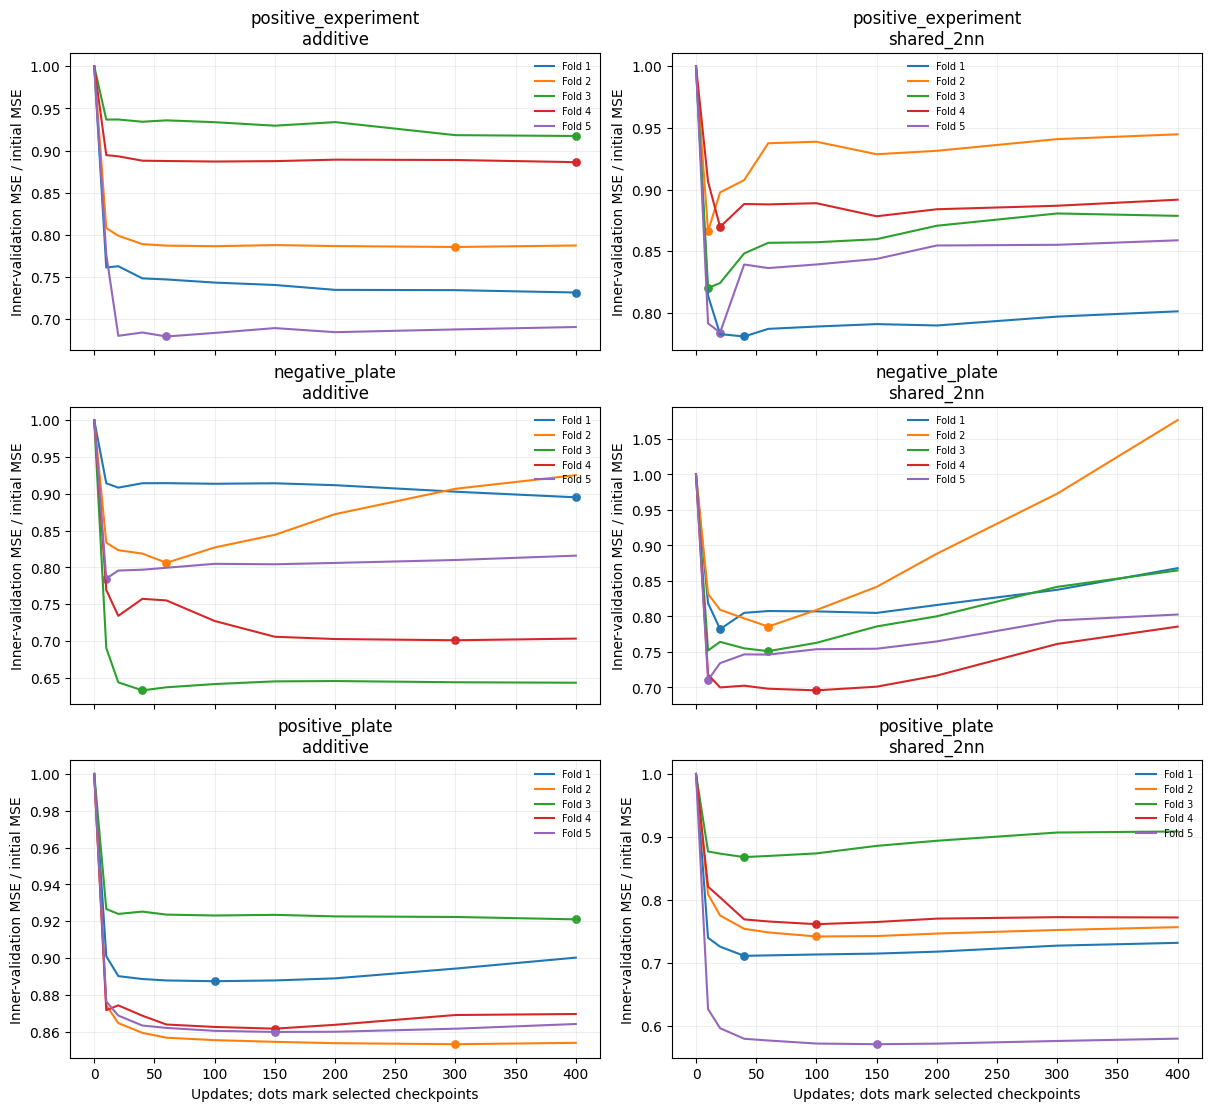

In [2]:
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

HP_REVIEW_DIR = Path(globals().get("hp_dir", "/nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_nested_hp_20261118T111217794502Z"))
review_selections = pd.read_csv(HP_REVIEW_DIR / "selected_hyperparameters.csv")
review_splits = json.loads((HP_REVIEW_DIR / "splits.json").read_text())
review_rows, review_trial_rows = [], []
review_inner_curves = {}
for split in review_splits:
    ablation, fold, batch = split["ablation"], split["fold"], split["outer_batch"]
    assert batch not in split["outer_training_batches"]
    assert set(split["inner_validation_batches"]).isdisjoint(split["inner_training_batches"])
    assert set(split["inner_validation_batches"]) | set(split["inner_training_batches"]) == set(split["outer_training_batches"])
    run = HP_REVIEW_DIR / ablation / f"fold_{fold+1}"
    locked = json.loads((run / "locked_selection.json").read_text())
    assert (run / "completed.json").exists()
    for variant in ["additive", "shared_2nn"]:
        chosen = locked[variant]
        observed = []
        for path in sorted((run / "trials").glob(f"{variant}_*_status.json")):
            status = json.loads(path.read_text())
            table = pd.read_csv(path.with_name(path.name.replace("_status.json", "_curves.csv")))
            assert set(table.batch) == set(split["inner_validation_batches"])
            assert not table.duplicated(["step", "batch"]).any()
            assert table.groupby("step").batch.nunique().eq(len(split["inner_validation_batches"])).all()
            assert np.isfinite(table[["training_mse", "validation_mse"]]).all().all()
            mean_curve = table.groupby("step").validation_mse.mean()
            if status["failed"] is None:
                np.testing.assert_allclose(status["inner_mse"], mean_curve.min(), rtol=1e-12)
                observed.append(float(mean_curve.min()))
            review_trial_rows.append({"ablation": ablation, "fold": fold, **status})
            if status["candidate"] == chosen["candidate"]:
                selected_curve = table.groupby("step")[["training_mse", "validation_mse"]].mean().reset_index()
                review_inner_curves[(ablation, fold, variant)] = selected_curve
                np.testing.assert_allclose(chosen["inner_mse"], mean_curve.loc[chosen["selected_step"]], rtol=1e-12)
                assert status["completed_step"] == 400
        np.testing.assert_allclose(chosen["inner_mse"], min(observed), rtol=1e-12)
        saved = torch.load(run / f"{variant}_selected.pt", map_location="cpu", weights_only=False, mmap=True)
        assert saved["selection"] == chosen
        assert saved["selected_step"] == chosen["selected_step"]
        assert saved["b"].shape == (chosen["features"], 384)
        assert saved["a"].shape == (len(saved["perturbations"]), 384)
        if variant == "shared_2nn":
            assert saved["c"].shape == (len(saved["perturbations"]), chosen["features"], 384)
        assert saved["config"]["neural"]["width_w"] == chosen["width"]
        assert saved["config"]["bridge_reg"] == chosen["ridge"]
        for key in ["a", "b"] + (["c"] if variant == "shared_2nn" else []):
            assert torch.isfinite(saved[key]).all().item()
        training = pd.read_csv(run / f"{variant}_training.csv")
        assert training.step.tolist() == list(range(400))
        assert np.isfinite(training.training_mse).all()
        early, late = training.training_mse.iloc[:20].mean(), training.training_mse.iloc[-20:].mean()
        review_rows.append({"ablation": ablation, "fold": fold, "batch": batch, "variant": variant,
            **{k:chosen[k] for k in ["ridge", "deviation_ridge", "features", "width", "selected_step", "inner_mse"]},
            "selection_matches_inner_minimum": True,
            "shared_ridge_at_search_boundary": chosen["ridge"] in [1e-7, 1e-3],
            "deviation_ridge_at_search_boundary": variant == "shared_2nn" and chosen["deviation_ridge"] in [1e-6, 1e-2],
            "selected_step_at_maximum": chosen["selected_step"] == 400,
            "training_drop_first20_last20_pct": 100 * (1 - late / early)})
        del saved
assert len(review_rows) == 30 and len(review_trial_rows) == 300
review_rows = pd.DataFrame(review_rows)
review_trials = pd.DataFrame(review_trial_rows)
review_rows.to_csv(HP_REVIEW_DIR / "hyperparameter_selection_audit.csv", index=False)
review_trials.to_csv(HP_REVIEW_DIR / "all_trial_statuses.csv", index=False)
assert review_trials.failed.isna().all()
for fold in range(5):
    a = next(s for s in review_splits if s["ablation"] == "negative_plate" and s["fold"] == fold)
    b = next(s for s in review_splits if s["ablation"] == "positive_plate" and s["fold"] == fold)
    assert a["inner_validation_batches"] == b["inner_validation_batches"]
    assert a["outer_batch"] == b["outer_batch"]
manifest = json.loads((HP_REVIEW_DIR / "manifest.json").read_text())
assert all(hashlib.sha256(Path(p).read_bytes()).hexdigest() == expected for p,expected in manifest["source_hashes"].items())
print("All 30 selections match the best observed inner validation score; all saved model shapes and split partitions verified.")
print("All 300 screened candidates have finite losses; model and script sources are unchanged.")
display(review_rows)
print("HP_BOUNDARY_AUDIT")
print(review_rows.groupby(["ablation", "variant"])[["shared_ridge_at_search_boundary", "deviation_ridge_at_search_boundary", "selected_step_at_maximum"]].sum().to_string())
fig, axes = plt.subplots(3, 2, figsize=(12, 11), sharex=True, layout="constrained")
for row, ablation in enumerate(["positive_experiment", "negative_plate", "positive_plate"]):
    for col, variant in enumerate(["additive", "shared_2nn"]):
        ax = axes[row, col]
        for fold in range(5):
            curve = review_inner_curves[(ablation, fold, variant)]
            selected = review_rows.loc[review_rows.ablation.eq(ablation) & review_rows.fold.eq(fold) & review_rows.variant.eq(variant)].iloc[0]
            values = curve.validation_mse / curve.validation_mse.iloc[0]
            ax.plot(curve.step, values, color=f"C{fold}", label=f"Fold {fold+1}")
            ax.scatter([selected.selected_step], [float(curve.loc[curve.step.eq(selected.selected_step), "validation_mse"].iloc[0] / curve.validation_mse.iloc[0])], color=f"C{fold}", s=28)
        ax.set_title(f"{ablation}\n{variant}")
        ax.set_ylabel("Inner-validation MSE / initial MSE")
        ax.grid(alpha=.2);ax.legend(frameon=False, fontsize=7)
        if row == 2:ax.set_xlabel("Updates; dots mark selected checkpoints")
fig.savefig(HP_REVIEW_DIR / "inner_selection_curves.png", dpi=180, bbox_inches="tight")
plt.show();plt.close(fig)


Completed hyperparameter search: results and learning-curve interpretation

All three HUVEC ablations finished. The search screened 300 candidates across 15 outer folds, promoted two candidates per neural model and outer fold to 400 updates, and selected ridge penalties, network capacity and stopping steps using only inner validation. All 30 selections were independently checked against every recorded candidate score. All 30 selected neural models are saved; model and script source hashes are unchanged.

MSE below is multiplied by 1,000; lower is better. Bold marks the best model per row. Means give equal weight to the five outer folds. These are the inner-selected checkpoints, fixed before outer scoring.

Positive proxies / plate batches

| Held-out batch | Linear | Additive | Shared 2NN |
|---|---:|---:|---:|
| HUVEC-10 / P1 | 1.0430 | 1.0400 | **0.9975** |
| HUVEC-22 / P4 | **1.2477** | 1.2558 | 1.2505 |
| HUVEC-02 / P2 | 1.3939 | 1.4056 | **1.2656** |
| HUVEC-04 / P2 | 1.1895 | 1.2204 | **1.0564** |
| HUVEC-14 / P1 | 1.6015 | 1.7110 | **1.5713** |
| Mean | 1.2951 | 1.3266 | **1.2283** |

Negative proxies / plate batches

| Held-out batch | Linear | Additive | Shared 2NN |
|---|---:|---:|---:|
| HUVEC-10 / P1 | 1.4296 | 1.2311 | **1.1136** |
| HUVEC-22 / P4 | **1.4082** | 1.6307 | 1.5651 |
| HUVEC-02 / P2 | **1.6486** | 1.9500 | 1.7844 |
| HUVEC-04 / P2 | 1.2940 | 1.5963 | **1.0594** |
| HUVEC-14 / P1 | **1.8443** | 2.0840 | 1.9892 |
| Mean | 1.5249 | 1.6984 | **1.5023** |

Positive proxies / experiment batches

| Held-out batch | Linear | Additive | Shared 2NN |
|---|---:|---:|---:|
| HUVEC-19 | **1.6183** | 2.4565 | 2.1383 |
| HUVEC-05 | **3.2029** | 5.2918 | 4.8662 |
| HUVEC-22 | **1.7169** | 1.9188 | 1.8398 |
| HUVEC-11 | **1.4319** | 1.4709 | 1.5494 |
| HUVEC-12 | **1.3532** | 1.4303 | 1.3643 |
| Mean | **1.8646** | 2.5137 | 2.3516 |

For positive proxies and plate batches, shared 2NN has 5.16% lower mean MSE than linear, wins four of five folds, and improves 4.12% over its previous fixed settings. It also has 7.41% lower mean MSE than the tuned additive model. For negative proxies and plates, shared 2NN has 1.48% lower mean MSE than linear, with two of five fold wins. For positive proxies and experiment batches, linear wins all five folds; shared 2NN remains 26.11% worse than linear despite improving 7.40% over its previous settings.

The tuned additive model improves 2.25% over its prior mean MSE for positive-proxy plates, but worsens 8.55% for positive-proxy experiments and 4.62% for negative-proxy plates. Tuning therefore did not improve every model or every held-out fold.

Positive-proxy plate settings selected for shared 2NN:

| Held-out plate | Ridge on a and b | Deviation ridge | Features / hidden width per network | Updates |
|---|---:|---:|---:|---:|
| HUVEC-10 / P1 | 1e-03 | 1e-04 | 32 / 64 | 40 |
| HUVEC-22 / P4 | 1e-04 | 1e-04 | 16 / 32 | 100 |
| HUVEC-02 / P2 | 1e-04 | 1e-04 | 32 / 64 | 40 |
| HUVEC-04 / P2 | 1e-04 | 1e-06 | 16 / 32 | 100 |
| HUVEC-14 / P1 | 1e-03 | 1e-04 | 32 / 64 | 150 |

Learning checks: all 300 candidate runs have finite losses. All 30 final diagnostic fits reduce training loss, including when comparing the first-20 and last-20 means. All 45 learned network branches changed from initialization and have finite parameters, including both branches of every shared 2NN fit. Visual inspection confirms rapid training-loss reduction followed by a plateau, without divergence. An unchanged-setting full-data refit also reproduced the previous MSE to numerical precision.

For positive-proxy plates, continuing the selected shared-2NN configurations to step 400 worsens outer MSE in all five folds. Inner validation selected 40, 100, 40, 100 and 150 updates, respectively. Early stopping also helps shared 2NN on average in the other two conditions, but does not improve every individual outer fold. In particular, some additive stopping choices transfer poorly to the outer batch. The outer curves are diagnostics; their minima never select the reported checkpoints.

This is a bounded, staged search with one neural initialization seed. Some penalties and capacities are selected at the tested boundaries, and five additive fits choose the maximum 400 updates. The same previously inspected outer folds are reused, so the results are a paired exploratory comparison. Plate folds retain sibling plates from the same experiment; their MSEs measure a different transfer task from experiment-level folds.

Full selected hyperparameters, candidate scores, model checkpoints, split definitions, paired results, coverage-conditioned errors and the inner/training/outer curve plots are saved under:

/nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_nested_hp_20261118T111217794502Z

Per-perturbation bridge on HUVEC positive proxies / plate batches

Evaluate the original per-x bridge, \(\widehat\mu_{xeg}=A_{xg}^{\top}z_e\), with one shared learned proxy network \(z_e=\mathbb E[\phi_\theta(W)\mid e]\). Use `NeuralPerXEmbeddingBridge` directly, including its differentiable per-x ridge solve and target-Gram loss. There is no explicit shared b term or separate a_x block. As in the other runs, inputs are standardized and targets centered using training data; the global training target mean is restored to predictions.

An earlier completed per-x RxRx1 run exists at `outputs/rxrx1_perx_embedding_curves_20261115T172613942046Z`, but it used negative proxies and experiment batches. This section runs only HUVEC, positive-control-only proxies and unique experiment-plate batch IDs. Use the same five outer plates and the exact same four inner validation plates per outer fold as the completed additive/2NN tuning. All crops, response weights, target scoring, training-only normalization and five-fold stochastic cross-fitting are preserved.

Screen 13 candidates per outer fold for 100 updates: six ridge values 1e-8 through 1e-3 at 16 features/width 32/lr 0.00075/weight decay 0.0001; the earlier per-x setting (ridge 1e-4, 32 features/width 32/lr 0.001/no weight decay); three capacity alternatives (8/16, 32/64, 64/64) around the best initial candidate; and lr 0.00025, lr 0.0015 and weight decay 0.1 alternatives around the best candidate after capacity screening. Promote the two best candidates to 400 updates without resetting optimizer or RNG state. Choose candidate and checkpoint by equal-inner-plate mean treatment MSE only. The checkpoint grid is 0, 10, 20, 40, 60, 100, 150, 200, 300, 400. This is a bounded staged search, not an exhaustive Cartesian grid.

Lock the selection before outer evaluation, refit on all 95 outer-training plates, and retain the 400-step trajectory for diagnostics while saving/scoring the inner-selected checkpoint. Compare with the already completed, inner-tuned linear/additive/2NN results on exactly matching targets. No outer curve chooses hyperparameters. The reused outer folds make this a paired exploratory comparison.

All new code lives in this notebook; data and artifacts stay on u434a. Existing model registries and previous experiments retain their original scope. The shared training helper now also validates the per-x A_ coefficient array.


In [5]:
import copy
import hashlib
import json
from dataclasses import dataclass, field
from types import SimpleNamespace
from genetic_perturbation_playground.model.batch_transfer import _mean_and_std

PERX_REFERENCE = ROOT / "outputs/rxrx1_huvec_nested_hp_20261118T111217794502Z"
PERX_SETTINGS = {"id": "positive_plate", "proxy_mode": "positive_only", "batch_unit": "plate"}
PERX_NAME = "per-x NN"
PERX_MODEL_ORDER = ["linear", "additive", "shared + deviation (2 NNs)", PERX_NAME]
HP_CHECKPOINTS = (0, 10, 20, 40, 60, 100, 150, 200, 300, 400)
HP_SCREEN_STEPS, HP_MAX_STEPS = 100, 400
hp_base_cfg = OmegaConf.load(PERX_REFERENCE / "base_config.yaml")
hp_base_cfg.neural.device = "cuda" if torch.cuda.is_available() else "cpu"
perx_resume = globals().get("PERX_RESUME_DIR")
perx_dir = Path(perx_resume) if perx_resume else ROOT / "outputs" / ("rxrx1_huvec_perx_positive_plate_hp_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ"))
perx_dir.mkdir(exist_ok=bool(perx_resume))
reference_scores = pd.read_csv(PERX_REFERENCE / "scores.csv")
reference_scores = reference_scores.loc[reference_scores.ablation.eq("positive_plate")].copy()
reference_scores.to_csv(perx_dir / "reference_scores.csv", index=False)
perx_manifest = {
    "model": "NeuralPerXEmbeddingBridge", "formula_centered_targets": "A_xg^T mean(phi_theta(W_e))",
    "reference": str(PERX_REFERENCE), "cell_type": "HUVEC", "proxy_mode": "positive_only", "batch_unit": "plate",
    "outer_folds": 5, "inner_plates": 4, "candidates_per_fold": 13, "promote": 2,
    "screen_steps": HP_SCREEN_STEPS, "max_steps": HP_MAX_STEPS, "checkpoints": list(HP_CHECKPOINTS),
    "selection_metric": "equal-inner-plate mean treatment MSE", "outer_scores_used_for_selection": False,
    "source_hashes": {str(p):hashlib.sha256(p.read_bytes()).hexdigest() for p in [
        ROOT / "src/genetic_perturbation_playground/model/batch_transfer.py",
        ROOT / "src/genetic_perturbation_playground/model/proxy_unconfounded_neural.py",
        ROOT / "scripts/train_batch_transfer_rxrx1.py"]},
}
(perx_dir / "manifest.json").write_text(json.dumps(perx_manifest, indent=2))
OmegaConf.save(hp_base_cfg, perx_dir / "base_config.yaml")
print("PERX_RUN_DIR", perx_dir, flush=True)
if "raw_adata" not in globals():
    raw_adata = select_cell_type(load_rxrx1(**hp_base_cfg.embeddings), "HUVEC").copy()
assert raw_adata.obs.cell_type.astype(str).eq("HUVEC").all()


PERX_RUN_DIR /nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_perx_positive_plate_hp_20261118T140833109911Z


Loaded /nfs/ghome/live/adhir/genetic_playground/data/rxrx1_phenom_4x4.h5ad
  2,008,160 crops  ×  384 features  |  1,139 perturbations


In [7]:
def perx_spec(ridge=1e-4, features=16, width=32, lr=0.00075, weight_decay=0.0001):
    return {"ridge": float(ridge), "features": int(features), "width": int(width),
            "lr": float(lr), "weight_decay": float(weight_decay)}


def perx_config(spec):
    config = hp_config(PERX_SETTINGS, spec)
    config.name = "rxrx1_perx_positive_plate_nested_hp"
    config.bridges = ["per_x"]
    config.neural.lr = spec["lr"]
    config.neural.weight_decay = spec["weight_decay"]
    del config.neural.deviation_reg
    return config


def perx_candidate(spec, data, candidate_id):
    config = perx_config(spec)
    config.neural.device = str(data.c.device)
    options = OmegaConf.to_container(config.neural, resolve=True)
    options.pop("per_perturbation", None)
    model = NeuralPerXEmbeddingBridge(reg=config.bridge_reg, seed=config.neural_seed, **options)
    torch.manual_seed(model.seed)
    model._build_networks(data)
    initial = {k:v.detach().cpu().clone() for k,v in model.psi_.state_dict().items()}
    optimizer = torch.optim.AdamW(model.psi_.parameters(), lr=model.lr, weight_decay=model.weight_decay)
    return HPCandidate("per_x", copy.deepcopy(spec), config, model, optimizer,
                       torch.get_rng_state().clone(), initial, candidate_id)


def perx_search(prepared, queries, directory):
    directory.mkdir(parents=True, exist_ok=True)
    cached = directory / "selection.json"
    if cached.exists():
        print("PERX_REUSE_SELECTION", str(cached), flush=True)
        return json.loads(cached.read_text())
    candidates = []
    def trial(spec, label):
        assert not any(c.spec == spec for c in candidates), "Duplicate HP candidate"
        candidate = perx_candidate(spec, prepared.data["per_x"], label)
        candidates.append(hp_trial(candidate, prepared, queries, HP_SCREEN_STEPS, directory))
    for i, ridge in enumerate([1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3]):
        trial(perx_spec(ridge), f"perx_ridge_{i:02d}")
    trial(perx_spec(1e-4, 32, 32, 0.001, 0.0), "perx_legacy")
    anchor = copy.deepcopy(hp_rank(candidates)[0].spec)
    for features, width in [(8,16), (32,64), (64,64)]:
        trial({**anchor, "features":features, "width":width}, f"perx_capacity_{features}")
    anchor = copy.deepcopy(hp_rank(candidates)[0].spec)
    trial({**anchor, "lr":0.00025}, "perx_slow_lr")
    trial({**anchor, "lr":0.0015}, "perx_fast_lr")
    trial({**anchor, "weight_decay":0.1}, "perx_weight_decay")
    assert len(candidates) == 13
    promoted = hp_rank(candidates)[:2]
    assert len(promoted) == 2
    promoted_ids = {c.candidate_id for c in promoted}
    pd.DataFrame([{**c.spec, "candidate":c.candidate_id, "inner_mse":c.best_mse,
                   "best_step":c.best_step, "promoted":c.candidate_id in promoted_ids,
                   "failed":c.failed} for c in candidates]).to_csv(directory / "screening.csv", index=False)
    for candidate in promoted:
        hp_trial(candidate, prepared, queries, HP_MAX_STEPS, directory)
    # Finite unpromoted candidates remain available if a promoted trial fails.
    chosen = hp_rank(candidates)[0]
    selection = {"variant":"per_x", **chosen.spec, "candidate":chosen.candidate_id,
                 "selected_step":chosen.best_step, "inner_mse":chosen.best_mse,
                 "n_candidates":len(candidates), "promoted":sorted(promoted_ids)}
    cached.write_text(json.dumps(selection, indent=2))
    print("PERX_SELECTED", json.dumps(selection), flush=True)
    return selection


def perx_adapter(config, prepared, fitted):
    options = OmegaConf.to_container(config.neural, resolve=True)
    adapter = with_standardisation(NeuralBridgeTransfer(
        weight_by_cells=config.weight_by_cells, reg=config.bridge_reg,
        seed=config.neural_seed, **options), config)
    adapter.w_mean_, adapter.w_std_, adapter.y_mean_ = prepared.w_mean, prepared.w_std, prepared.y_mean
    adapter.model.perturbations_ = prepared.perturbations
    adapter.model.bridge_ = fitted
    return adapter


def perx_save(candidate, prepared, selection, batch, fold, path):
    config = OmegaConf.to_container(candidate.config, resolve=False)
    config["neural"]["n_steps"] = int(selection["selected_step"])
    torch.save({"variant":"per_x", "config":config, "selection":selection,
        "held_out_batch":batch, "fold":fold, "selected_step":int(selection["selected_step"]),
        "diagnostic_max_steps":candidate.step, "perturbations":prepared.perturbations.tolist(),
        "A":candidate.model.A_.detach().cpu(),
        "psi_state_dict":{k:v.detach().cpu() for k,v in candidate.model.psi_.state_dict().items()},
        "w_mean":torch.as_tensor(prepared.w_mean), "w_std":torch.as_tensor(prepared.w_std),
        "y_mean":torch.as_tensor(prepared.y_mean)}, path)


In [8]:
# Reproduce the existing per-x optimizer exactly, including pause/resume.
rng = np.random.default_rng(131)
xs = [np.eye(4) for _ in range(7)]
ys = [rng.normal(size=(4,3)) for _ in xs]
ws = [rng.normal(size=(9,3)) for _ in xs]
counts = [rng.integers(2,9,size=4) for _ in xs]
spec = perx_spec(1e-5, 8, 16)
config = perx_config(spec)
options = OmegaConf.to_container(config.neural, resolve=True)
options.pop("per_perturbation", None)
options.update(device="cpu", n_steps=8)
original = NeuralPerXEmbeddingBridge(reg=config.bridge_reg, seed=config.neural_seed, **options)
original.fit(xs,ys,ws,counts)
data = original._to_tensors(xs,ys,ws,counts)
candidate = perx_candidate(spec,data,"parity")
query = [{"batch":"synthetic","x":xs[0],"w":ws[0],"truth":ys[0]}]
hp_advance(candidate,data,query,0.,3)
hp_advance(candidate,data,query,0.,8)
for k,v in original.psi_.state_dict().items():
    torch.testing.assert_close(candidate.model.psi_.state_dict()[k],v,rtol=1e-6,atol=1e-7)
np.testing.assert_allclose(candidate.model.predict(xs[0],ws[0]),original.predict(xs[0],ws[0]),rtol=1e-6,atol=1e-8)
assert candidate.model.A_.shape == (4,8,3)
assert OmegaConf.to_container(config,resolve=False)["bridge_reg"] == 1e-5
pd.DataFrame([{"model":"per_x","resumed_matches_original":True,"coefficient_shape_correct":True}]).to_csv(perx_dir / "implementation_checks.csv",index=False)
del candidate,original,data,xs,ys,ws,counts
print("PERX_IMPLEMENTATION_CHECKS_PASSED",flush=True)


PERX_IMPLEMENTATION_CHECKS_PASSED


In [9]:
perx_score_rows = [pd.read_csv(perx_dir / "perx_scores.csv")] if (perx_dir / "perx_scores.csv").exists() else []
perx_selections = pd.read_csv(perx_dir / "selected_hyperparameters.csv").to_dict("records") if (perx_dir / "selected_hyperparameters.csv").exists() else []
perx_curve_rows = [pd.read_csv(perx_dir / "outer_learning_curves.csv")] if (perx_dir / "outer_learning_curves.csv").exists() else []
perx_weight_rows = pd.read_csv(perx_dir / "network_parameter_audit.csv").to_dict("records") if (perx_dir / "network_parameter_audit.csv").exists() else []
config = perx_config(perx_spec())
adata = prepare_ablation(raw_adata,config)
batches = batch_labels(adata)
adata.obs.groupby(["batch","experiment_batch","plate","well_type"],observed=True).size().rename("crops").to_csv(perx_dir / "data_audit.csv")
for fold in range(5):
    fold_dir = perx_dir / f"fold_{fold+1}"
    fold_dir.mkdir(exist_ok=True)
    if (fold_dir / "completed.json").exists():
        print("PERX_REUSE_COMPLETED_FOLD",fold+1,flush=True)
        continue
    split = json.loads((PERX_REFERENCE / "positive_plate" / f"fold_{fold+1}" / "split.json").read_text())
    batch = split["outer_batch"]
    inner = split["inner_validation_batches"]
    outer_train = adata[batches != batch]
    inner_train = outer_train[~np.isin(batch_labels(outer_train),inner)]
    assert sorted(np.unique(batch_labels(inner_train))) == split["inner_training_batches"]
    assert sorted(np.unique(batch_labels(outer_train))) == split["outer_training_batches"]
    assert batch not in inner and set(inner).isdisjoint(batch_labels(inner_train))
    (fold_dir / "split.json").write_text(json.dumps(split,indent=2))
    print("PERX_FOLD_START",fold+1,batch,"inner validation",inner,flush=True)
    prepared = hp_prepare(inner_train,config)
    prepared.data["per_x"] = prepared.data["shared_2nn"]
    queries = hp_queries(outer_train,inner,prepared)
    selection = perx_search(prepared,queries,fold_dir / "trials")
    # Lock choices before reading outer responses for scoring.
    (fold_dir / "locked_selection.json").write_text(json.dumps(selection,indent=2))
    perx_selections.append({"fold":fold,"batch":batch,**selection})
    pd.DataFrame(perx_selections).drop_duplicates(["fold"],keep="last").to_csv(perx_dir / "selected_hyperparameters.csv",index=False)
    del prepared,queries,inner_train
    gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
    test = adata[batches == batch]
    linear = BatchTransferModel(standardise_w=config.standardise_w).fit(outer_train)
    check = score_batch({"linear":linear},test)
    ref = reference_scores.loc[reference_scores.batch.eq(batch) & reference_scores.model.eq("linear")]
    joined = check.merge(ref,on=["perturbation","metric"],suffixes=("_new","_old"),validate="one_to_one")
    assert len(joined)==len(check)==len(ref)
    np.testing.assert_allclose(joined.value_new,joined.value_old,rtol=1e-9,atol=1e-11)
    del linear
    prepared = hp_prepare(outer_train,config)
    prepared.data["per_x"] = prepared.data["shared_2nn"]
    queries = hp_queries(test,[batch],prepared)
    spec = {k:selection[k] for k in ["ridge","features","width","lr","weight_decay"]}
    candidate = perx_candidate(spec,prepared.data["per_x"],"outer_refit")
    stop = int(selection["selected_step"])
    hp_advance(candidate,prepared.data["per_x"],queries,prepared.y_mean,HP_MAX_STEPS,capture_steps=[stop])
    curves = pd.DataFrame(candidate.records).assign(fold=fold,model=PERX_NAME,selected_step=stop,linear_mse=float(ref.value.mean()))
    curves.to_csv(fold_dir / "outer_curves.csv",index=False)
    pd.DataFrame(candidate.train_records).to_csv(fold_dir / "training.csv",index=False)
    perx_curve_rows.append(curves)
    candidate.model.psi_.load_state_dict(candidate.captured[stop])
    candidate.model._solve_A(prepared.data["per_x"])
    adapter = perx_adapter(candidate.config,prepared,candidate.model)
    scored = score_batch({PERX_NAME:adapter},test).assign(batch=batch,fold=fold,ablation="positive_plate",selected_step=stop)
    scored["n_training_batches"] = scored.perturbation.map(training_batch_counts(outer_train))
    scored["n_treatment_crops"] = scored.perturbation.map(test.obs.loc[test.obs.well_type.eq("treatment"),"perturbation"].value_counts())
    assert set(scored.perturbation)==set(ref.perturbation)
    np.testing.assert_allclose(scored.value.mean(),curves.loc[curves.step.eq(stop),"validation_mse"].item(),rtol=1e-6,atol=1e-10)
    perx_score_rows.append(scored)
    perx_save(candidate,prepared,selection,batch,fold,fold_dir / "perx_selected.pt")
    final = candidate.model.psi_.state_dict()
    delta = sum((final[k].detach().cpu().double()-candidate.initial[k].double()).square().sum().item() for k in final)
    norm = sum(candidate.initial[k].double().square().sum().item() for k in final)
    assert all(torch.isfinite(v).all().item() for v in final.values())
    assert (delta>0) if stop>0 else (delta==0)
    perx_weight_rows.append({"fold":fold,"batch":batch,"selected_step":stop,"finite_weights":True,
                            "relative_parameter_change":float(np.sqrt(delta/norm))})
    scores = pd.concat(perx_score_rows,ignore_index=True).drop_duplicates(["batch","perturbation","metric","model"],keep="last")
    scores.to_csv(perx_dir / "perx_scores.csv",index=False)
    pd.concat([reference_scores,scores],ignore_index=True).to_csv(perx_dir / "combined_scores.csv",index=False)
    pd.concat(perx_curve_rows,ignore_index=True).drop_duplicates(["batch","step"],keep="last").to_csv(perx_dir / "outer_learning_curves.csv",index=False)
    pd.DataFrame(perx_weight_rows).drop_duplicates(["fold"],keep="last").to_csv(perx_dir / "network_parameter_audit.csv",index=False)
    (fold_dir / "completed.json").write_text(json.dumps({"completed_utc":datetime.now(timezone.utc).isoformat()}))
    print("PERX_OUTER_RESULT",fold+1,batch,"step",stop,"MSE",float(scored.value.mean()),"linear",float(ref.value.mean()),flush=True)
    del candidate,adapter,prepared,queries,outer_train,test
    gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
print("PERX_ALL_FITS_COMPLETE",perx_dir,flush=True)


PERX_FOLD_START 1 HUVEC-10|plate_1 inner validation ['HUVEC-02|plate_1', 'HUVEC-10|plate_2', 'HUVEC-16|plate_3', 'HUVEC-14|plate_4']


HP_TRIAL {"candidate": "perx_ridge_00", "variant": "per_x", "ridge": 1e-08, "features": 16, "width": 32, "lr": 0.00075, "weight_decay": 0.0001, "completed_step": 100, "best_step": 40, "inner_mse": 0.0018718309907918547, "failed": null, "last_stage_seconds": 12.333705603145063}


HP_TRIAL {"candidate": "perx_ridge_01", "variant": "per_x", "ridge": 1e-07, "features": 16, "width": 32, "lr": 0.00075, "weight_decay": 0.0001, "completed_step": 100, "best_step": 40, "inner_mse": 0.001672118921061533, "failed": null, "last_stage_seconds": 13.114527619909495}


HP_TRIAL {"candidate": "perx_ridge_02", "variant": "per_x", "ridge": 1e-06, "features": 16, "width": 32, "lr": 0.00075, "weight_decay": 0.0001, "completed_step": 100, "best_step": 60, "inner_mse": 0.0015891583396842306, "failed": null, "last_stage_seconds": 13.944016979075968}


HP_TRIAL {"candidate": "perx_ridge_03", "variant": "per_x", "ridge": 1e-05, "features": 16, "width": 32, "lr": 0.00075, "weight_decay": 0.0001, "completed_step": 100, "best_step": 100, "inner_mse": 0.0015543379227192147, "failed": null, "last_stage_seconds": 13.928688604850322}


HP_TRIAL {"candidate": "perx_ridge_04", "variant": "per_x", "ridge": 0.0001, "features": 16, "width": 32, "lr": 0.00075, "weight_decay": 0.0001, "completed_step": 100, "best_step": 100, "inner_mse": 0.001558994331450244, "failed": null, "last_stage_seconds": 14.257379978895187}


... (81 outputs left out)

HP_TRIAL {"candidate": "perx_weight_decay", "variant": "per_x", "ridge": 0.0001, "features": 32, "width": 32, "lr": 0.001, "weight_decay": 0.1, "completed_step": 400, "best_step": 100, "inner_mse": 0.001935839474761175, "failed": null, "last_stage_seconds": 53.37951747793704}


PERX_SELECTED {"variant": "per_x", "ridge": 0.0001, "features": 32, "width": 32, "lr": 0.0015, "weight_decay": 0.0, "candidate": "perx_fast_lr", "selected_step": 100, "inner_mse": 0.0019305980519428345, "n_candidates": 13, "promoted": ["perx_fast_lr", "perx_weight_decay"]}


PERX_OUTER_RESULT 5 HUVEC-14|plate_1 step 100 MSE 0.001721079780606729 linear 0.001601454516179747


PERX_ALL_FITS_COMPLETE /nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_perx_positive_plate_hp_20261118T140833109911Z


,model,linear,additive,shared + deviation (2 NNs),per-x NN
fold,batch,,,,
0,HUVEC-10|plate_1,0.001043009,0.001040027,0.000997473,0.001170660
1,HUVEC-22|plate_4,0.001247679,0.001255837,0.001250467,0.001415586
2,HUVEC-02|plate_2,0.001393898,0.001405553,0.001265587,0.001336509
3,HUVEC-04|plate_2,0.001189483,0.001220399,0.001056429,0.001197740
4,HUVEC-14|plate_1,0.001601455,0.001711028,0.001571348,0.001721080


model,linear,additive,shared + deviation (2 NNs),per-x NN
mse,0.001295105,0.001326569,0.001228261,0.001368315


PERX_FINAL_TABLE model                      linear    additive  shared + deviation (2 NNs)    per-x NN
fold batch                                                                           
0    HUVEC-10|plate_1 0.001043009 0.001040027                 0.000997473 0.001170660
1    HUVEC-22|plate_4 0.001247679 0.001255837                 0.001250467 0.001415586
2    HUVEC-02|plate_2 0.001393898 0.001405553                 0.001265587 0.001336509
3    HUVEC-04|plate_2 0.001189483 0.001220399                 0.001056429 0.001197740
4    HUVEC-14|plate_1 0.001601455 0.001711028                 0.001571348 0.001721080


PERX_MEANS {'linear': 0.0012951047664675514, 'additive': 0.0013265686992025773, 'shared + deviation (2 NNs)': 0.0012282609073485408, 'per-x NN': 0.001368314787223787}


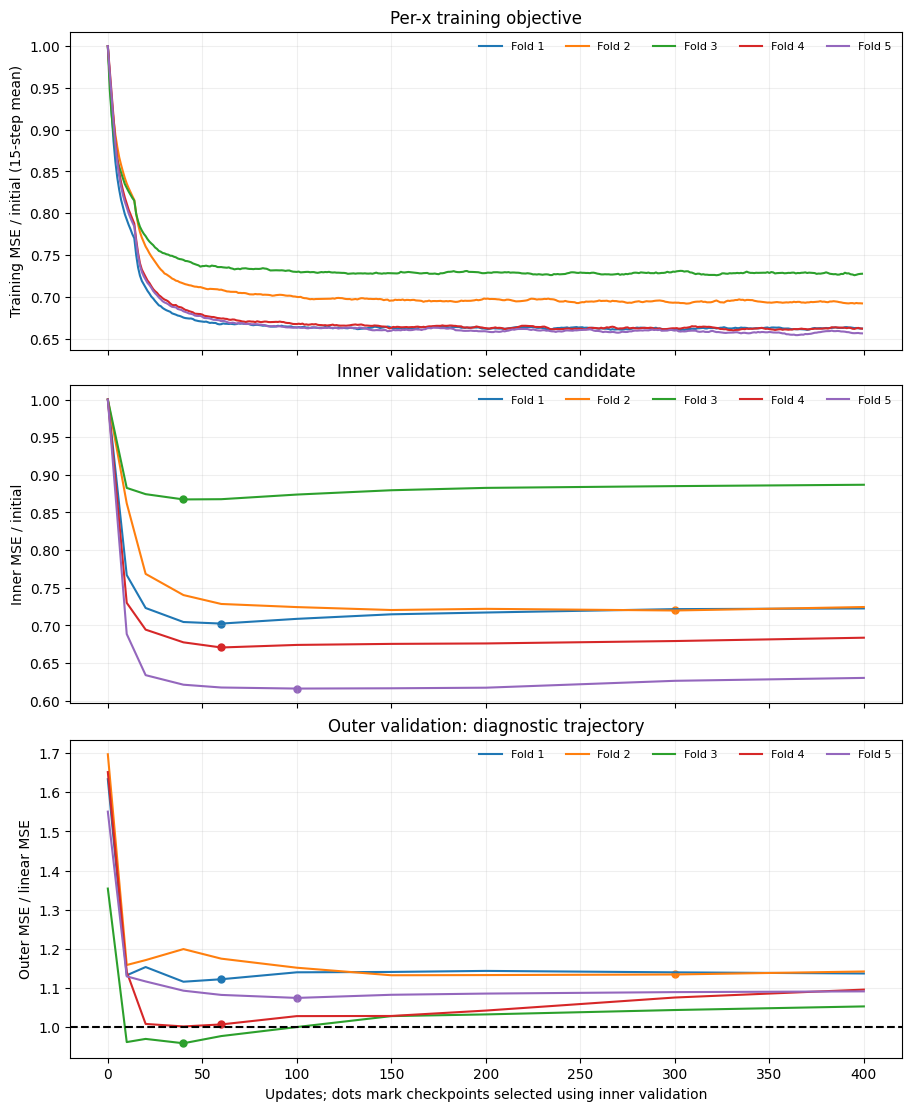

PERX_AUDIT  fold            batch  selected_step  selection_matches_inner_minimum   ridge  features  width      lr  weight_decay  ridge_at_boundary  features_at_upper_boundary  step_at_upper_boundary  training_drop_first20_last20_pct  selected_mse  step400_mse  step400_vs_selected_pct  selected_vs_linear_pct
    0 HUVEC-10|plate_1             60                             True 0.00010        64     64 0.00150           0.0              False                        True                   False                         11.819724      0.001171     0.001186                 1.311236               12.238634
    1 HUVEC-22|plate_4            300                             True 0.00001        16     32 0.00075           0.1              False                       False                   False                         13.116751      0.001416     0.001425                 0.675496               13.457549
    2 HUVEC-02|plate_2             40                             True 0.00001        64    

PERX_HP_CHOICES  fold            batch variant   ridge  features  width      lr  weight_decay         candidate  selected_step  inner_mse  n_candidates                                  promoted
    0 HUVEC-10|plate_1   per_x 0.00010        64     64 0.00150           0.0      perx_fast_lr             60   0.001541            13      ['perx_capacity_64', 'perx_fast_lr']
    1 HUVEC-22|plate_4   per_x 0.00001        16     32 0.00075           0.1 perx_weight_decay            300   0.001462            13    ['perx_ridge_03', 'perx_weight_decay']
    2 HUVEC-02|plate_2   per_x 0.00001        64     64 0.00075           0.1 perx_weight_decay             40   0.001469            13 ['perx_capacity_64', 'perx_weight_decay']
    3 HUVEC-04|plate_2   per_x 0.00010        32     32 0.00150           0.0      perx_fast_lr             60   0.001636            13     ['perx_fast_lr', 'perx_weight_decay']
    4 HUVEC-14|plate_1   per_x 0.00010        32     32 0.00150           0.0      perx_fast_l

PERX_VERIFIED_COMPLETE /nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_perx_positive_plate_hp_20261118T140833109911Z


In [10]:
perx_all = pd.read_csv(perx_dir / "combined_scores.csv")
perx_chosen = pd.read_csv(perx_dir / "selected_hyperparameters.csv")
perx_curves = pd.read_csv(perx_dir / "outer_learning_curves.csv")
assert len(perx_chosen)==5
assert set(perx_all.model)==set(PERX_MODEL_ORDER)
assert perx_all.groupby("model").batch.nunique().eq(5).all()
assert np.isfinite(perx_all.value).all()
assert not perx_all.duplicated(["batch","perturbation","model","metric"]).any()
keys=["batch","perturbation","metric"]
ref=perx_all.loc[perx_all.model.eq("linear")].sort_values(keys).reset_index(drop=True)
for name in PERX_MODEL_ORDER[1:]:
    other=perx_all.loc[perx_all.model.eq(name)].sort_values(keys).reset_index(drop=True)
    for col in keys+["n_training_batches","n_treatment_crops"]:assert ref[col].equals(other[col]),(name,col)
perx_by_fold=perx_all.groupby(["fold","batch","model"]).value.mean().unstack("model")[PERX_MODEL_ORDER].sort_index()
perx_mean=perx_by_fold.mean().rename("mse")
perx_by_fold.to_csv(perx_dir / "per_fold_mse.csv")
perx_mean.to_csv(perx_dir / "average_mse.csv")
display(perx_by_fold.style.highlight_min(axis=1,props="font-weight: bold;").format("{:.9f}"))
display(perx_mean.to_frame().T.style.highlight_min(axis=1,props="font-weight: bold;").format("{:.9f}"))
print("PERX_FINAL_TABLE",perx_by_fold.to_string(float_format=lambda x:f"{x:.9f}"),flush=True)
print("PERX_MEANS",perx_mean.to_dict(),flush=True)

perx_audit_rows,perx_trial_rows=[],[]
fig,axes=plt.subplots(3,1,figsize=(9,11),sharex=True,layout="constrained")
for fold in range(5):
    d=perx_dir / f"fold_{fold+1}"
    split=json.loads((d / "split.json").read_text())
    locked=json.loads((d / "locked_selection.json").read_text())
    expected=json.loads((PERX_REFERENCE / "positive_plate" / f"fold_{fold+1}" / "split.json").read_text())
    assert split==expected
    assert set(split["inner_training_batches"]).isdisjoint(split["inner_validation_batches"])
    assert split["outer_batch"] not in split["outer_training_batches"]
    observed=[]
    for path in sorted((d / "trials").glob("*_status.json")):
        status=json.loads(path.read_text())
        table=pd.read_csv(path.with_name(path.name.replace("_status.json","_curves.csv")))
        assert set(table.batch)==set(split["inner_validation_batches"])
        assert not table.duplicated(["step","batch"]).any()
        assert table.groupby("step").batch.nunique().eq(4).all()
        if status["failed"] is None:
            assert np.isfinite(table[["training_mse","validation_mse"]]).all().all()
            mean=table.groupby("step").validation_mse.mean()
            np.testing.assert_allclose(status["inner_mse"],mean.min(),rtol=1e-12)
            observed.append(float(mean.min()))
        perx_trial_rows.append({"fold":fold,**status})
        if status["candidate"]==locked["candidate"]:
            inner=table.groupby("step").validation_mse.mean()
            np.testing.assert_allclose(inner.loc[locked["selected_step"]],locked["inner_mse"],rtol=1e-12)
    np.testing.assert_allclose(locked["inner_mse"],min(observed),rtol=1e-12)
    saved=torch.load(d / "perx_selected.pt",map_location="cpu",weights_only=False,mmap=True)
    assert saved["selection"]==locked
    assert saved["A"].shape==(len(saved["perturbations"]),locked["features"],384)
    assert torch.isfinite(saved["A"]).all().item()
    assert all(torch.isfinite(v).all().item() for v in saved["psi_state_dict"].values())
    train=pd.read_csv(d / "training.csv")
    assert train.step.tolist()==list(range(400)) and np.isfinite(train.training_mse).all()
    outer=perx_curves.loc[perx_curves.fold.eq(fold)].sort_values("step")
    assert outer.step.tolist()==list(HP_CHECKPOINTS)
    stop=int(locked["selected_step"])
    selected=outer.loc[outer.step.eq(stop)].iloc[0];last=outer.iloc[-1]
    np.testing.assert_allclose(selected.validation_mse,perx_by_fold.loc[(fold,split["outer_batch"]),PERX_NAME],rtol=1e-6)
    early,late=train.training_mse.iloc[:20].mean(),train.training_mse.iloc[-20:].mean()
    perx_audit_rows.append({"fold":fold,"batch":split["outer_batch"],"selected_step":stop,
        "selection_matches_inner_minimum":True,"ridge":locked["ridge"],"features":locked["features"],
        "width":locked["width"],"lr":locked["lr"],"weight_decay":locked["weight_decay"],
        "ridge_at_boundary":locked["ridge"] in [1e-8,1e-3],"features_at_upper_boundary":locked["features"]==64,
        "step_at_upper_boundary":stop==400,"training_drop_first20_last20_pct":100*(1-late/early),
        "selected_mse":selected.validation_mse,"step400_mse":last.validation_mse,
        "step400_vs_selected_pct":100*(last.validation_mse/selected.validation_mse-1),
        "selected_vs_linear_pct":100*(selected.validation_mse/selected.linear_mse-1)})
    color=f"C{fold}"
    axes[0].plot(train.step,train.training_mse.rolling(15,min_periods=1).mean()/train.training_mse.iloc[0],color=color,label=f"Fold {fold+1}")
    axes[1].plot(inner.index,inner/inner.iloc[0],color=color,label=f"Fold {fold+1}")
    axes[1].scatter([stop],[inner.loc[stop]/inner.iloc[0]],color=color,s=25)
    axes[2].plot(outer.step,outer.validation_mse/outer.linear_mse,color=color,label=f"Fold {fold+1}")
    axes[2].scatter([stop],[selected.validation_mse/selected.linear_mse],color=color,s=25)
    del saved
assert len(perx_trial_rows)==65
perx_audit=pd.DataFrame(perx_audit_rows)
perx_audit.to_csv(perx_dir / "learning_and_selection_audit.csv",index=False)
pd.DataFrame(perx_trial_rows).to_csv(perx_dir / "all_trial_statuses.csv",index=False)
for ax,title,ylabel in zip(axes,["Per-x training objective","Inner validation: selected candidate","Outer validation: diagnostic trajectory"],
                           ["Training MSE / initial (15-step mean)","Inner MSE / initial","Outer MSE / linear MSE"]):
    ax.set_title(title);ax.set_ylabel(ylabel);ax.grid(alpha=.2);ax.legend(frameon=False,ncol=5,fontsize=8)
axes[2].axhline(1,color="black",linestyle="--")
axes[2].set_xlabel("Updates; dots mark checkpoints selected using inner validation")
fig.savefig(perx_dir / "perx_learning_curves.png",dpi=180,bbox_inches="tight")
plt.show();plt.close(fig)
perx_all.groupby(["batch","n_training_batches","model"]).value.agg(siRNAs="size",mse="mean").to_csv(perx_dir / "coverage_summary.csv")
assert all(hashlib.sha256(Path(p).read_bytes()).hexdigest()==v for p,v in perx_manifest["source_hashes"].items())
print("PERX_AUDIT",perx_audit.to_string(index=False),flush=True)
print("PERX_HP_CHOICES",perx_chosen.to_string(index=False),flush=True)
print("PERX_VERIFIED_COMPLETE",perx_dir,flush=True)


**Completed per-x result: RxRx1 HUVEC, positive-control-only proxies, plate batches**

The existing `NeuralPerXEmbeddingBridge` implements a separate ridge-fitted $A_{xg}$ for every perturbation and output coordinate, with one shared proxy NN: $\hat Y_g=\bar Y_g+A_{xg}^{\top}z_e$. The 384 outputs here are RxRx1 embedding coordinates.

Run directory: `/nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_perx_positive_plate_hp_20261118T140833109911Z`. All five outer test plates and their inner splits exactly match the previous tuned comparison. The numbers below are equal-perturbation MSE within each fold; the final row weights folds equally. **MSE × 1,000; lower is better.**

| Fold / test plate | Linear | Additive NN | Shared + deviation 2NN | Per-x NN |
|---|---:|---:|---:|---:|
| 1: HUVEC-10 / plate_1 | 1.043009 | 1.040027 | **0.997473** | 1.170660 |
| 2: HUVEC-22 / plate_4 | **1.247679** | 1.255837 | 1.250467 | 1.415586 |
| 3: HUVEC-02 / plate_2 | 1.393898 | 1.405553 | **1.265587** | 1.336509 |
| 4: HUVEC-04 / plate_2 | 1.189483 | 1.220399 | **1.056429** | 1.197740 |
| 5: HUVEC-14 / plate_1 | 1.601455 | 1.711028 | **1.571348** | 1.721080 |
| Mean | 1.295105 | 1.326569 | **1.228261** | 1.368315 |

Per-x MSE is 5.65% higher than linear, 3.15% higher than additive, and 11.40% higher than 2NN. Per-x wins 1/5 folds against linear, 2/5 against additive, and 0/5 against 2NN. The shared-plus-deviation 2NN remains best on average in this comparison.

**Selection and final fitting**

Each outer fold used four inner validation plates and 91 inner-training plates. Thirteen configurations were screened to 100 updates; the two leading configurations continued to 400. Hyperparameters and the stopping checkpoint were selected by equal-inner-plate mean MSE. The selection was written to disk before outer scoring. A fresh network was then trained on all 95 outer-training plates. Its preselected checkpoint was captured, restored after the diagnostic trajectory, and its ridge coefficients recomputed using all outer-training data. Outer test losses did not select a checkpoint. This is checkpoint selection, with no patience rule.

| Fold | Ridge | Features | Width | Learning rate | Weight decay | Selected updates |
|---|---:|---:|---:|---:|---:|---:|
| 1 | 1e-04 | 64 | 64 | 0.0015 | 0 | 60 |
| 2 | 1e-05 | 16 | 32 | 0.00075 | 0.1 | 300 |
| 3 | 1e-05 | 64 | 64 | 0.00075 | 0.1 | 40 |
| 4 | 1e-04 | 32 | 32 | 0.0015 | 0 | 60 |
| 5 | 1e-04 | 32 | 32 | 0.0015 | 0 | 100 |

**Learning-curve and hyperparameter checks**

All 65 trials were finite, all saved networks changed their weights, and all five selections match the best observed inner-validation score. Training objectives decreased on every fold: the last 20 updates averaged 9.2–14.0% below the first 20. Visual inspection shows a sharp initial training improvement followed by a plateau, while inner-validation curves flatten or rise after their minima. No selected checkpoint is at the 400-update limit. Using step 400 instead would worsen outer MSE by 0.68–9.82% across the five folds.

The chosen ridge values are interior to the tested 1e-8–1e-3 range. Folds 1 and 3 selected the largest tested embedding size (64); folds 1, 4, and 5 selected the largest tested learning rate (0.0015). These are the best observed configurations in the stated search, not a claim of a global hyperparameter optimum. The original model modules and all prior notebook outputs remain unchanged; the only existing helper edit allows its finite-coefficient check to recognize per-x `A_`.

**Conditioned on training-batch availability**

This supplementary table pools held-out perturbation/plate pairs within each availability group. Its averaging differs from the equal-fold main table. Most pairs have 23 training batches; the small 20–22 groups should not be interpreted as a controlled effect of batch count. MSE × 1,000.

| Training batches | Held-out pairs | Linear | Additive NN | Shared + deviation 2NN | Per-x NN |
|---:|---:|---:|---:|---:|---:|
| 20 | 4 | **0.521795** | 0.525380 | 0.631296 | 0.816468 |
| 21 | 13 | 1.281985 | **1.203007** | 1.305323 | 1.497130 |
| 22 | 38 | 1.824030 | 1.788112 | **1.639855** | 1.761707 |
| 23 | 1326 | 1.281484 | 1.315810 | **1.216476** | 1.356379 |

The training objective, selected-candidate inner curves, and diagnostic outer curves are displayed immediately above and saved as `perx_learning_curves.png` in the run directory. The restored models are in each `fold_N/perx_selected.pt`.

**Ridge-regularised linear transfer: matched positive-proxy / plate comparison**

Keep the existing linear model's coordinate-wise transfer surface:
\[
\hat Y_g(x,e)=a_{xg}+b_g\widetilde W_{eg}.
\]
Here \(\widetilde W\) is the plate's positive-proxy mean, standardised using pooled training proxy crops. Fit
\[
\frac1N\sum_i\sum_g(Y_{ig}-a_{x_i g}-b_g\widetilde W_{e_i g})^2+\lambda\sum_g b_g^2.
\]
The perturbation intercepts are unpenalised. Eliminating them gives the existing within-perturbation least-squares numerator divided by its denominator plus \(N\lambda\). Thus \(\lambda=0\) recovers the existing linear transfer model, and \(\lambda=\infty\) gives pooled perturbation means. There is one slope per output coordinate, with no cross-coordinate mixing.

Use only HUVEC with positive proxies and plate batches. Reuse exactly the five outer test plates and four inner validation plates per fold from the NN comparison. Search zero, infinity, and a log grid from 1e-10 to 1e2; extend a finite boundary if selected, then refine the best finite interval in log space. Select by equal-inner-plate mean MSE, lock the penalty before outer scoring, and refit on all 95 outer-training plates. All computation below is analytic CPU fitting; no NN retraining or early stopping is required. All implementation changes are confined to this notebook.


In [4]:
import copy
import hashlib
import json
from types import SimpleNamespace
from scipy.optimize import minimize_scalar
from genetic_perturbation_playground.model.batch_transfer import (
    summary_stats, matched_control_mean, _mean_and_std,
)

RIDGE_REFERENCE = ROOT / "outputs/rxrx1_huvec_perx_positive_plate_hp_20261118T140833109911Z"
RIDGE_SPLITS = ROOT / "outputs/rxrx1_huvec_nested_hp_20261118T111217794502Z/positive_plate"
RIDGE_NAME = "ridge linear"
RIDGE_ORDER = ["linear", RIDGE_NAME, "additive", "shared + deviation (2 NNs)", "per-x NN"]
ridge_cfg = OmegaConf.merge(OmegaConf.load(RIDGE_REFERENCE / "base_config.yaml"), {
    "name":"rxrx1_ridge_linear_positive_plate", "proxy_mode":"positive_only", "batch_unit":"plate",
})
ridge_resume = globals().get("RIDGE_RESUME_DIR")
ridge_dir = Path(ridge_resume) if ridge_resume else ROOT / "outputs" / ("rxrx1_huvec_ridge_linear_positive_plate_hp_"+datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ"))
ridge_dir.mkdir(exist_ok=bool(ridge_resume))
ridge_reference_scores = pd.read_csv(RIDGE_REFERENCE / "combined_scores.csv")
ridge_reference_scores.to_csv(ridge_dir / "reference_scores.csv",index=False)
ridge_manifest = {
    "model":"coordinate-wise linear transfer with ridge slopes and unpenalised perturbation intercepts",
    "penalty":"lambda * N * sum_g b_g**2 on standardised W coefficients",
    "cell_type":"HUVEC", "proxy_mode":"positive_only", "batch_unit":"plate",
    "outer_folds":5, "inner_plates":4, "initial_grid":[0.,*[float(10.**e) for e in range(-10,3)],"inf"],
    "refinement":"quarter-decade grid and bounded scalar refinement of the best finite log interval",
    "selection_metric":"equal-inner-plate mean treatment MSE", "outer_scores_used_for_selection":False,
    "reference":str(RIDGE_REFERENCE), "split_reference":str(RIDGE_SPLITS),
    "source_hashes":{str(p):hashlib.sha256(p.read_bytes()).hexdigest() for p in [
        ROOT / "src/genetic_perturbation_playground/model/batch_transfer.py",
        ROOT / "src/genetic_perturbation_playground/model/proxy_unconfounded_neural.py",
        ROOT / "scripts/train_batch_transfer_rxrx1.py"]},
}
(ridge_dir / "manifest.json").write_text(json.dumps(ridge_manifest,indent=2))
OmegaConf.save(ridge_cfg,ridge_dir / "base_config.yaml")
print("RIDGE_RUN_DIR",ridge_dir,flush=True)
if "raw_adata" not in globals():
    raw_adata = select_cell_type(load_rxrx1(**ridge_cfg.embeddings),"HUVEC").copy()
assert raw_adata.obs.cell_type.astype(str).eq("HUVEC").all()


RIDGE_RUN_DIR /nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_ridge_linear_positive_plate_hp_20261118T152406164238Z


Loaded /nfs/ghome/live/adhir/genetic_playground/data/rxrx1_phenom_4x4.h5ad
  2,008,160 crops  ×  384 features  |  1,139 perturbations


In [5]:
class RidgeLinearTransfer(BatchTransferModel):
    """Same coordinate-wise transfer as BatchTransferModel; ridge only its slopes."""
    def __init__(self, ridge=0.0, standardise_w=True):
        super().__init__(slope=None,standardise_w=standardise_w)
        self.ridge=float(ridge)
        if np.isnan(self.ridge) or self.ridge<0:raise ValueError("ridge must be nonnegative")

    def _coefficient(self,s):
        y,w,n=s["y_mean"],s["w_mean"],s["n"][:,None]
        self.numerator_=(s["W"]*s["batch_y_sum"]).sum(axis=0)-(n*y*w).sum(axis=0)
        first=(s["batch_n"][:,None]*s["W"]**2).sum(axis=0)
        second=(n*w**2).sum(axis=0)
        denominator=first-second
        tolerance=100*np.finfo(float).eps*np.maximum(first+second,1.)
        assert (denominator>=-tolerance).all(),"Negative within-perturbation variance"
        self.denominator_=np.maximum(denominator,0.)
        self.n_observations_=int(s["n"].sum())
        self.training_y_mean_=y.copy()
        self.training_w_mean_=w.copy()
        return self._ridge_coefficient(self.ridge)

    def _ridge_coefficient(self,ridge):
        if np.isinf(ridge):return np.zeros_like(self.numerator_)
        den=self.denominator_+self.n_observations_*ridge
        return np.divide(self.numerator_,den,out=np.zeros_like(self.numerator_),where=den>0)

    def with_ridge(self,ridge):
        ridge=float(ridge)
        if np.isnan(ridge) or ridge<0:raise ValueError("ridge must be nonnegative")
        fitted=copy.copy(self)
        fitted.ridge=ridge
        fitted.coef_=self._ridge_coefficient(ridge)
        fitted.intercept_=self.training_y_mean_-fitted.coef_*self.training_w_mean_
        fitted.slope_=fitted.coef_/self.w_std_
        fitted.gamma_=fitted.intercept_-fitted.slope_*self.w_mean_
        assert np.isfinite(fitted.coef_).all() and np.isfinite(fitted.intercept_).all()
        return fitted


def ridge_queries(data,labels,fitted):
    queries=[]
    batches=batch_labels(data)
    for label in labels:
        test=data[batches==label]
        names,truth,compact=checkpoint_inputs(test,fitted.perturbations_)
        idx=np.searchsorted(fitted.perturbations_,names)
        w=(matched_control_mean(compact,names)-fitted.w_mean_)/fitted.w_std_
        queries.append({"batch":label,"names":names,"truth":truth,"idx":idx,"w":w})
    return queries


def ridge_cached_predict(fitted,query):
    return fitted.intercept_[query["idx"]]+fitted.coef_*query["w"]


def ridge_search(fitted,queries,directory):
    directory.mkdir(exist_ok=True)
    cache={};records=[]
    def evaluate(value):
        value=float(value)
        if value in cache:return cache[value]
        candidate=fitted.with_ridge(value)
        scores=[]
        for query in queries:
            error=float(mse(ridge_cached_predict(candidate,query),query["truth"]).mean())
            assert np.isfinite(error)
            records.append({"ridge":value,"batch":query["batch"],"validation_mse":error})
            scores.append(error)
        cache[value]=float(np.mean(scores))
        return cache[value]
    def best():return min(cache,key=lambda r:(cache[r],r))
    evaluate(0.);evaluate(float("inf"))
    for e in range(-10,3):evaluate(10.**e)
    extensions=0
    while np.isfinite(best()) and best()>0:
        finite=sorted(r for r in cache if np.isfinite(r) and r>0)
        if best()==finite[0] and finite[0]>1e-16:evaluate(finite[0]/100)
        elif best()==finite[-1] and finite[-1]<1e8:evaluate(finite[-1]*100)
        else:break
        extensions+=1
        assert extensions<=8
    anchor=best()
    optimizer_result=None
    if 0<anchor<float("inf"):
        log_anchor=np.log10(anchor)
        for exponent in np.linspace(log_anchor-1,log_anchor+1,9):evaluate(10.**exponent)
        centre=np.log10(best())
        optimizer_result=minimize_scalar(lambda t:evaluate(10.**float(t)),
            bounds=(centre-.25,centre+.25),method="bounded",options={"xatol":1e-5,"maxiter":80})
        assert optimizer_result.success,optimizer_result.message
    chosen=best()
    selection={"ridge":chosen if np.isfinite(chosen) else "inf", "inner_mse":cache[chosen],
        "zero_inner_mse":cache[0.],"pooled_inner_mse":cache[float("inf")],
        "n_candidates":len(cache),"boundary_extensions":extensions,
        "scalar_refinement_success":None if optimizer_result is None else bool(optimizer_result.success)}
    trials=pd.DataFrame(records).sort_values(["ridge","batch"])
    trials.to_csv(directory / "inner_validation.csv",index=False)
    trials.groupby("ridge",dropna=False).validation_mse.mean().to_csv(directory / "inner_mean.csv")
    (directory / "selection.json").write_text(json.dumps(selection,indent=2))
    print("RIDGE_SELECTED",json.dumps(selection),flush=True)
    return selection


def ridge_save(fitted,path):
    np.savez_compressed(path,ridge=fitted.ridge,standardise_w=fitted.standardise_w,
        perturbations=fitted.perturbations_.astype(str),coef=fitted.coef_,intercept=fitted.intercept_,
        slope=fitted.slope_,gamma=fitted.gamma_,w_mean=fitted.w_mean_,w_std=fitted.w_std_,
        numerator=fitted.numerator_,denominator=fitted.denominator_,n_observations=fitted.n_observations_)


In [6]:
# Validate the profiled solution against full weighted ridge normal equations.
from anndata import AnnData
rng=np.random.default_rng(727)
blocks=[];observations=[]
true_intercepts=rng.normal(size=(3,4));true_slopes=np.array([.2,-1.,.8,1.4])
for e in range(7):
    centre=rng.normal(size=4)
    control=centre+.1*rng.normal(size=(6,4))
    blocks.append(control)
    observations.extend([{"batch":str(e),"perturbation":"control"} for _ in control])
    for x in range(3):
        if e==2 and x==1:continue
        count=2+(e+x)%4
        target=true_intercepts[x]+true_slopes*centre+.2*rng.normal(size=(count,4))
        blocks.append(target)
        observations.extend([{"batch":str(e),"perturbation":f"p{x}"} for _ in target])
small=AnnData(np.vstack(blocks),obs=pd.DataFrame(observations,index=[str(i) for i in range(len(observations))]))
zero=RidgeLinearTransfer(0.).fit(small)
original=BatchTransferModel().fit(small)
np.testing.assert_allclose(zero.coef_,original.coef_,rtol=1e-12,atol=1e-12)
np.testing.assert_allclose(zero.predict(zero.perturbations_,small),original.predict(original.perturbations_,small),rtol=1e-12,atol=1e-12)
s=summary_stats(small);ctrl=is_control(small)
pidx=np.searchsorted(zero.perturbations_,perturbation_labels(small)[~ctrl])
bidx=np.searchsorted(s["batches"],batch_labels(small)[~ctrl])
W=(s["W"][bidx]-zero.w_mean_)/zero.w_std_;Y=small.X[~ctrl]
for penalty in [0.,1e-4,.1,10.]:
    fitted=zero.with_ridge(penalty)
    for g in range(Y.shape[1]):
        design=np.column_stack([np.eye(3)[pidx],W[:,g]])
        regularizer=np.diag([0.,0.,0.,len(Y)*penalty])
        coef=np.linalg.solve(design.T@design+regularizer,design.T@Y[:,g])
        np.testing.assert_allclose(np.r_[fitted.intercept_[:,g],fitted.coef_[g]],coef,rtol=1e-10,atol=1e-11)
    assert (np.abs(fitted.coef_)<=np.abs(zero.coef_)+1e-12).all()
pooled=zero.with_ridge(float("inf"))
np.testing.assert_array_equal(pooled.coef_,np.zeros(4))
np.testing.assert_allclose(pooled.intercept_,s["y_mean"],rtol=1e-12,atol=1e-12)
pd.DataFrame([{"zero_matches_existing":True,"matches_joint_ridge":True,"pooled_limit_correct":True,"slopes_shrink":True}]).to_csv(ridge_dir / "implementation_checks.csv",index=False)
del small,zero,original,fitted,pooled,s,blocks,Y,W,design
print("RIDGE_IMPLEMENTATION_CHECKS_PASSED",flush=True)


RIDGE_IMPLEMENTATION_CHECKS_PASSED


In [7]:
ridge_adata=prepare_ablation(raw_adata,ridge_cfg)
ridge_batches=batch_labels(ridge_adata)
ridge_adata.obs.groupby(["batch","experiment_batch","plate","well_type"],observed=True).size().rename("crops").to_csv(ridge_dir / "data_audit.csv")
ridge_score_rows=[pd.read_csv(ridge_dir / "ridge_scores.csv")] if (ridge_dir / "ridge_scores.csv").exists() else []
ridge_choices=pd.read_csv(ridge_dir / "selected_hyperparameters.csv").to_dict("records") if (ridge_dir / "selected_hyperparameters.csv").exists() else []
ridge_checks=[]
for fold in range(5):
    d=ridge_dir / f"fold_{fold+1}";d.mkdir(exist_ok=True)
    if (d / "completed.json").exists():
        print("RIDGE_REUSE_FOLD",fold+1,flush=True);continue
    split=json.loads((RIDGE_SPLITS / f"fold_{fold+1}" / "split.json").read_text())
    batch=split["outer_batch"];inner=split["inner_validation_batches"]
    outer_train=ridge_adata[ridge_batches!=batch]
    inner_train=outer_train[~np.isin(batch_labels(outer_train),inner)]
    assert sorted(np.unique(batch_labels(outer_train)))==split["outer_training_batches"]
    assert sorted(np.unique(batch_labels(inner_train)))==split["inner_training_batches"]
    assert batch not in inner and set(inner).isdisjoint(batch_labels(inner_train))
    (d / "split.json").write_text(json.dumps(split,indent=2))
    print("RIDGE_FOLD_START",fold+1,batch,flush=True)
    inner_model=RidgeLinearTransfer(0.,standardise_w=ridge_cfg.standardise_w).fit(inner_train)
    queries=ridge_queries(outer_train,inner,inner_model)
    selection=ridge_search(inner_model,queries,d / "trials")
    # Persist the selected lambda before touching the outer test responses.
    (d / "locked_selection.json").write_text(json.dumps(selection,indent=2))
    del inner_model,queries,inner_train
    gc.collect()
    test=ridge_adata[ridge_batches==batch]
    outer_zero=RidgeLinearTransfer(0.,standardise_w=ridge_cfg.standardise_w).fit(outer_train)
    chosen=outer_zero.with_ridge(float(selection["ridge"]))
    scores=score_batch({"linear":outer_zero,RIDGE_NAME:chosen},test)
    reference=ridge_reference_scores.loc[ridge_reference_scores.batch.eq(batch)&ridge_reference_scores.model.eq("linear")]
    check=scores.loc[scores.model.eq("linear")].merge(reference,on=["perturbation","metric"],suffixes=("_new","_old"),validate="one_to_one")
    assert len(check)==len(reference)
    np.testing.assert_allclose(check.value_new,check.value_old,rtol=1e-9,atol=1e-11)
    scored=scores.loc[scores.model.eq(RIDGE_NAME)].copy().assign(batch=batch,fold=fold,ablation="positive_plate",selected_ridge=selection["ridge"])
    scored["n_training_batches"]=scored.perturbation.map(training_batch_counts(outer_train))
    scored["n_treatment_crops"]=scored.perturbation.map(test.obs.loc[test.obs.well_type.eq("treatment"),"perturbation"].value_counts())
    q=ridge_queries(test,[batch],chosen)[0]
    np.testing.assert_allclose(ridge_cached_predict(chosen,q),chosen.predict(q["names"],test),rtol=1e-10,atol=1e-11)
    np.testing.assert_allclose(float(mse(ridge_cached_predict(chosen,q),q["truth"]).mean()),scored.value.mean(),rtol=1e-10,atol=1e-11)
    assert (np.abs(chosen.coef_)<=np.abs(outer_zero.coef_)+1e-12).all()
    if np.isfinite(chosen.ridge):
        np.testing.assert_allclose((chosen.denominator_+chosen.n_observations_*chosen.ridge)*chosen.coef_,chosen.numerator_,rtol=1e-10,atol=1e-10)
    ridge_save(chosen,d / "ridge_linear_selected.npz")
    saved=np.load(d / "ridge_linear_selected.npz",allow_pickle=False)
    np.testing.assert_array_equal(saved["coef"],chosen.coef_)
    np.testing.assert_array_equal(saved["intercept"],chosen.intercept_)
    saved.close()
    shrink=np.linalg.norm(chosen.coef_)/np.linalg.norm(outer_zero.coef_)
    ridge_choices.append({"fold":fold,"batch":batch,**selection,"slope_norm_ratio":float(shrink)})
    ridge_score_rows.append(scored)
    pd.DataFrame(ridge_choices).drop_duplicates("fold",keep="last").to_csv(ridge_dir / "selected_hyperparameters.csv",index=False)
    result=pd.concat(ridge_score_rows,ignore_index=True).drop_duplicates(["batch","perturbation","metric"],keep="last")
    result.to_csv(ridge_dir / "ridge_scores.csv",index=False)
    pd.concat([ridge_reference_scores,result],ignore_index=True).to_csv(ridge_dir / "combined_scores.csv",index=False)
    (d / "completed.json").write_text(json.dumps({"completed_utc":datetime.now(timezone.utc).isoformat(),"zero_matches_reference":True,"cached_matches_native":True,"normal_equations_checked":True,"saved_model_checked":True}))
    print("RIDGE_OUTER_RESULT",fold+1,batch,"lambda",selection["ridge"],"MSE",float(scored.value.mean()),"linear",float(reference.value.mean()),flush=True)
    del outer_train,test,outer_zero,chosen,q
    gc.collect()
print("RIDGE_ALL_FITS_COMPLETE",ridge_dir,flush=True)


RIDGE_FOLD_START 1 HUVEC-10|plate_1


RIDGE_SELECTED {"ridge": 0.0058523174527024616, "inner_mse": 0.0013642161027215666, "zero_inner_mse": 0.0013716788510759928, "pooled_inner_mse": 0.002235201707532581, "n_candidates": 31, "boundary_extensions": 0, "scalar_refinement_success": true}


RIDGE_OUTER_RESULT 1 HUVEC-10|plate_1 lambda 0.0058523174527024616 MSE 0.0010293033512409795 linear 0.001043009485284836


RIDGE_FOLD_START 2 HUVEC-22|plate_4


RIDGE_SELECTED {"ridge": 0.0015828843707978882, "inner_mse": 0.0014465842907094592, "zero_inner_mse": 0.0014470807113061753, "pooled_inner_mse": 0.0020954431283948744, "n_candidates": 32, "boundary_extensions": 0, "scalar_refinement_success": true}


RIDGE_OUTER_RESULT 2 HUVEC-22|plate_4 lambda 0.0015828843707978882 MSE 0.001254620639304187 linear 0.0012476786803226549


... (6 outputs left out)

RIDGE_FOLD_START 5 HUVEC-14|plate_1


RIDGE_SELECTED {"ridge": 0.0, "inner_mse": 0.0017037726645923405, "zero_inner_mse": 0.0017037726645923405, "pooled_inner_mse": 0.0032851046924204444, "n_candidates": 15, "boundary_extensions": 0, "scalar_refinement_success": null}


RIDGE_OUTER_RESULT 5 HUVEC-14|plate_1 lambda 0.0 MSE 0.0016014545161797977 linear 0.001601454516179747


RIDGE_ALL_FITS_COMPLETE /nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_ridge_linear_positive_plate_hp_20261118T152406164238Z


,model,linear,ridge linear,additive,shared + deviation (2 NNs),per-x NN
fold,batch,,,,,
0,HUVEC-10|plate_1,1.043009,1.029303,1.040027,0.997473,1.170660
1,HUVEC-22|plate_4,1.247679,1.254621,1.255837,1.250467,1.415586
2,HUVEC-02|plate_2,1.393898,1.393929,1.405553,1.265587,1.336509
3,HUVEC-04|plate_2,1.189483,1.191870,1.220399,1.056429,1.197740
4,HUVEC-14|plate_1,1.601455,1.601455,1.711028,1.571348,1.721080


model,linear,ridge linear,additive,shared + deviation (2 NNs),per-x NN
mse,1.295105,1.294235,1.326569,1.228261,1.368315


RIDGE_FINAL_TABLE_X1000 model                    linear  ridge linear  additive  shared + deviation (2 NNs)  per-x NN
fold batch                                                                                   
0    HUVEC-10|plate_1  1.043009      1.029303  1.040027                    0.997473  1.170660
1    HUVEC-22|plate_4  1.247679      1.254621  1.255837                    1.250467  1.415586
2    HUVEC-02|plate_2  1.393898      1.393929  1.405553                    1.265587  1.336509
3    HUVEC-04|plate_2  1.189483      1.191870  1.220399                    1.056429  1.197740
4    HUVEC-14|plate_1  1.601455      1.601455  1.711028                    1.571348  1.721080


RIDGE_MEANS {'linear': 0.0012951047664675514, 'ridge linear': 0.0012942354824767252, 'additive': 0.0013265686992025773, 'shared + deviation (2 NNs)': 0.0012282609073485408, 'per-x NN': 0.001368314787223787}


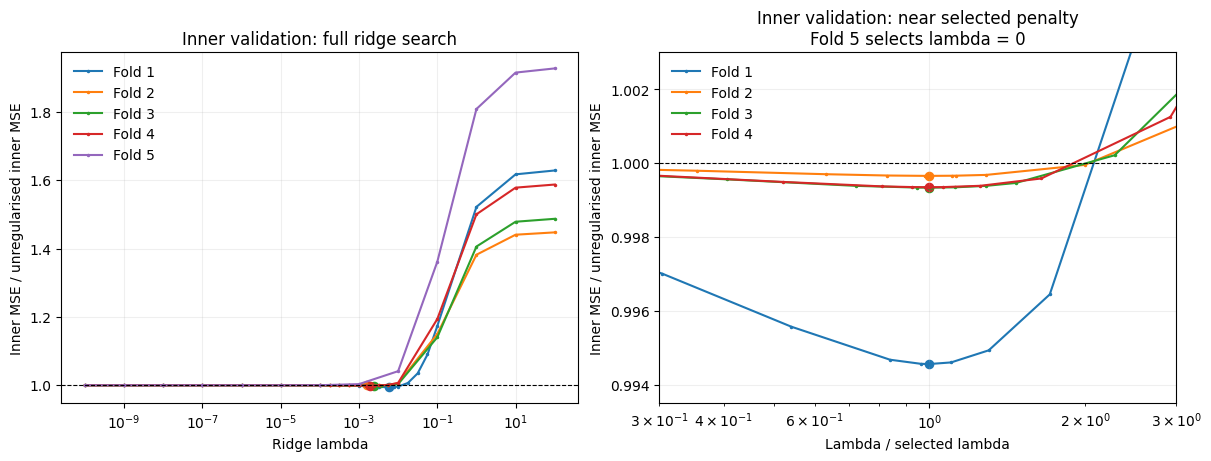

RIDGE_HP_CHOICES  fold            batch    ridge  inner_mse  zero_inner_mse  pooled_inner_mse  n_candidates  boundary_extensions scalar_refinement_success  slope_norm_ratio
    0 HUVEC-10|plate_1 0.005852   0.001364        0.001372          0.002235            31                    0                      True          0.906675
    1 HUVEC-22|plate_4 0.001583   0.001447        0.001447          0.002095            32                    0                      True          0.972490
    2 HUVEC-02|plate_2 0.002464   0.001237        0.001238          0.001842            30                    0                      True          0.958073
    3 HUVEC-04|plate_2 0.001922   0.001455        0.001456          0.002312            31                    0                      True          0.966822
    4 HUVEC-14|plate_1 0.000000   0.001704        0.001704          0.003285            15                    0                       NaN          1.000000


RIDGE_SELECTION_AUDIT  fold            batch    ridge  n_candidates  selection_matches_inner_minimum  inner_improvement_vs_zero_pct  outer_improvement_vs_zero_pct  finite_penalty_bracketed
    0 HUVEC-10|plate_1 0.005852            31                             True                       0.544059                       1.314095                      True
    1 HUVEC-22|plate_4 0.001583            32                             True                       0.034305                      -0.556390                      True
    2 HUVEC-02|plate_2 0.002464            30                             True                       0.066206                      -0.002220                      True
    3 HUVEC-04|plate_2 0.001922            31                             True                       0.064995                      -0.200660                      True
    4 HUVEC-14|plate_1 0.000000            15                             True                       0.000000                       0.000000   

RIDGE_VERIFIED_COMPLETE /nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_ridge_linear_positive_plate_hp_20261118T152406164238Z


In [2]:
ridge_all=pd.read_csv(ridge_dir / "combined_scores.csv")
ridge_selected=pd.read_csv(ridge_dir / "selected_hyperparameters.csv")
assert set(ridge_all.model)==set(RIDGE_ORDER)
assert ridge_all.groupby("model").batch.nunique().eq(5).all()
assert len(ridge_selected)==5 and np.isfinite(ridge_all.value).all()
assert not ridge_all.duplicated(["batch","perturbation","metric","model"]).any()
keys=["batch","perturbation","metric"]
reference=ridge_all.loc[ridge_all.model.eq("linear")].sort_values(keys).reset_index(drop=True)
for model in RIDGE_ORDER[1:]:
    other=ridge_all.loc[ridge_all.model.eq(model)].sort_values(keys).reset_index(drop=True)
    for col in keys+["n_training_batches","n_treatment_crops"]:assert reference[col].equals(other[col]),(model,col)
ridge_by_fold=ridge_all.groupby(["fold","batch","model"]).value.mean().unstack("model")[RIDGE_ORDER].sort_index()
ridge_means=ridge_by_fold.mean().rename("mse")
ridge_by_fold.to_csv(ridge_dir / "per_fold_mse.csv")
ridge_means.to_csv(ridge_dir / "average_mse.csv")
display((ridge_by_fold*1000).style.highlight_min(axis=1,props="font-weight:bold;").format("{:.6f}"))
display((ridge_means.to_frame().T*1000).style.highlight_min(axis=1,props="font-weight:bold;").format("{:.6f}"))
print("RIDGE_FINAL_TABLE_X1000",(ridge_by_fold*1000).to_string(),flush=True)
print("RIDGE_MEANS",ridge_means.to_dict(),flush=True)
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout="constrained")
ridge_audit=[]
for fold in range(5):
    d=ridge_dir / f"fold_{fold+1}"
    split=json.loads((d / "split.json").read_text())
    assert split==json.loads((RIDGE_SPLITS / f"fold_{fold+1}" / "split.json").read_text())
    locked=json.loads((d / "locked_selection.json").read_text())
    records=pd.read_csv(d / "trials/inner_validation.csv",float_precision="round_trip")
    assert set(records.batch)==set(split["inner_validation_batches"])
    assert not records.duplicated(["ridge","batch"]).any()
    assert records.groupby("ridge").batch.nunique().eq(4).all()
    mean=records.groupby("ridge").validation_mse.mean().sort_index()
    penalty=float(locked["ridge"])
    np.testing.assert_allclose(locked["inner_mse"],mean.min(),rtol=1e-12)
    np.testing.assert_allclose(mean.loc[penalty],mean.min(),rtol=1e-12)
    assert locked["inner_mse"]<=locked["zero_inner_mse"]+1e-15
    assert len(mean)==locked["n_candidates"]
    finite=mean.loc[(mean.index>0)&np.isfinite(mean.index)]
    axes[0].plot(finite.index,finite/mean.loc[0.],marker=".",ms=3,label=f"Fold {fold+1}")
    if 0<penalty<float("inf"):axes[0].scatter([penalty],[mean.loc[penalty]/mean.loc[0.]],s=35)
    if 0<penalty<float("inf"):
        nearby=finite.loc[(finite.index>=penalty/10)&(finite.index<=penalty*10)]
        axes[1].plot(nearby.index/penalty,nearby/mean.loc[0.],marker=".",ms=3,label=f"Fold {fold+1}")
        axes[1].scatter([1.],[mean.loc[penalty]/mean.loc[0.]],s=35)
    ridge_audit.append({"fold":fold,"batch":split["outer_batch"],"ridge":penalty,
        "n_candidates":len(mean),"selection_matches_inner_minimum":True,
        "inner_improvement_vs_zero_pct":100*(1-locked["inner_mse"]/locked["zero_inner_mse"]),
        "outer_improvement_vs_zero_pct":100*(1-ridge_by_fold.loc[(fold,split["outer_batch"]),RIDGE_NAME]/ridge_by_fold.loc[(fold,split["outer_batch"]),"linear"]),
        "finite_penalty_bracketed":bool(penalty==0 or np.isinf(penalty) or finite.index.min()<penalty<finite.index.max())})
for ax in axes:
    ax.set_xscale("log");ax.axhline(1.,color="black",linestyle="--",linewidth=.8);ax.grid(alpha=.2);ax.legend(frameon=False)
axes[0].set_title("Inner validation: full ridge search");axes[0].set_xlabel("Ridge lambda");axes[0].set_ylabel("Inner MSE / unregularised inner MSE")
axes[1].set_title("Inner validation: near selected penalty\nFold 5 selects lambda = 0");axes[1].set_xlabel("Lambda / selected lambda");axes[1].set_ylabel("Inner MSE / unregularised inner MSE")
axes[1].set_xlim(.3,3.);axes[1].set_ylim(.9935,1.003)
fig.savefig(ridge_dir / "ridge_validation_curves.png",dpi=180,bbox_inches="tight")
plt.show();plt.close(fig)
pd.DataFrame(ridge_audit).to_csv(ridge_dir / "selection_audit.csv",index=False)
ridge_all.groupby(["n_training_batches","model"]).value.agg(pairs="size",mse="mean").to_csv(ridge_dir / "conditional_mse.csv")
assert all(r["finite_penalty_bracketed"] for r in ridge_audit)
assert all(hashlib.sha256(Path(p).read_bytes()).hexdigest()==v for p,v in ridge_manifest["source_hashes"].items())
print("RIDGE_HP_CHOICES",ridge_selected.to_string(index=False),flush=True)
print("RIDGE_SELECTION_AUDIT",pd.DataFrame(ridge_audit).to_string(index=False),flush=True)
print("RIDGE_VERIFIED_COMPLETE",ridge_dir,flush=True)


**Ridge-linear result and positive-proxy / plate collection**

The new model regularises the existing coordinate-wise shared transfer slopes; perturbation intercepts remain unpenalised. All five test plates, four-plate inner splits, crop weighting, and proxy standardisation match the earlier comparison. This is an analytic ridge fit, with no NN or stopping-step parameter.

**MSE × 1,000; lower is better. The mean weights the five folds equally.**

| Fold / held-out plate | Linear | Ridge linear | Additive NN | Shared + deviation 2NN | Per-x NN |
|---|---:|---:|---:|---:|---:|
| 1: HUVEC-10 / plate_1 | 1.043009 | 1.029303 | 1.040027 | **0.997473** | 1.170660 |
| 2: HUVEC-22 / plate_4 | **1.247679** | 1.254621 | 1.255837 | 1.250467 | 1.415586 |
| 3: HUVEC-02 / plate_2 | 1.393898 | 1.393929 | 1.405553 | **1.265587** | 1.336509 |
| 4: HUVEC-04 / plate_2 | 1.189483 | 1.191870 | 1.220399 | **1.056429** | 1.197740 |
| 5: HUVEC-14 / plate_1 | 1.601455 | 1.601455 | 1.711028 | **1.571348** | 1.721080 |
| Mean | 1.295105 | 1.294235 | 1.326569 | **1.228261** | 1.368315 |

Ridge improves mean MSE over unregularised linear by only 0.0671%. It improves fold 1, worsens folds 2–4, and equals the original model on fold 5. The shared-plus-deviation 2NN still has 5.10% lower MSE than ridge linear.

**Penalty selection and checks**

| Fold | Selected lambda | Candidate penalties evaluated | Inner improvement vs zero (%) | Slope norm / unregularised norm |
|---|---:|---:|---:|---:|
| 1 | 0.00585231745 | 31 | 0.5441 | 0.9067 |
| 2 | 0.00158288437 | 32 | 0.0343 | 0.9725 |
| 3 | 0.00246374633 | 30 | 0.0662 | 0.9581 |
| 4 | 0.00192179232 | 31 | 0.0650 | 0.9668 |
| 5 | 0 | 15 | 0.0000 | 1.0000 |

The search evaluated 139 fold-specific penalties: zero, the pooled-mean limit, a broad log grid, and local refinement. All four positive selections are bracketed inside the search range; fold 5 selects zero. Every selected penalty is the observed inner-validation minimum and was locked before outer scoring. Checks reproduce the existing linear predictions at zero, match a direct joint ridge solve on synthetic data with unequal counts, verify the ridge normal equations on real fits, and round-trip the saved coefficients.

The validation curves show very shallow gains from weak shrinkage and clearly worse scores with strong penalties. The fold-5 inner score is best without shrinkage. The tiny average test improvement does not change the model ranking.

**Collected files on u434a**

`/nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_results/` contains only HUVEC, positive-control-only proxies, and plate-level batches. `scores.csv`, `per_fold_mse.csv`, and `average_mse.csv` are the latest five-model results. `learning_curves/` contains a joint three-NN training/inner-validation/outer-validation figure, raw curve tables, and the ridge validation plot. `tuned_nn/`, `per_x/`, and `ridge_linear/` preserve detailed trial scores, curves, splits, and audits. `untuned_positive_plate/` contains the earlier fixed-HP run for this same condition. The final notebook cell refreshes this collection.


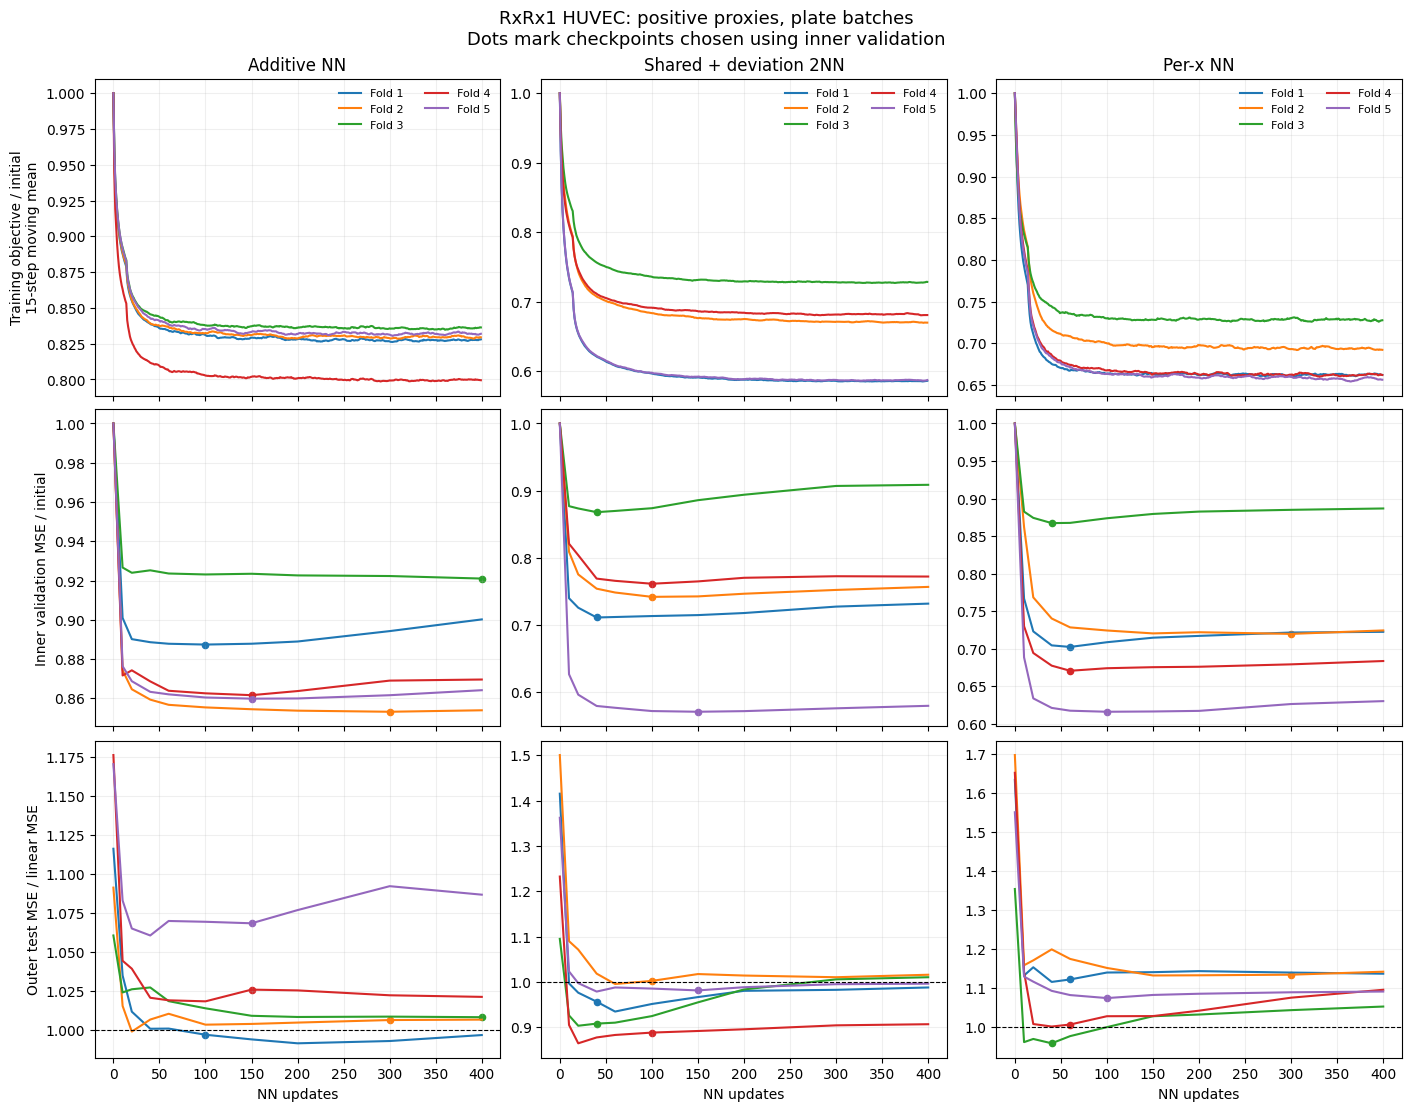

RXRX1_RESULTS_COLLECTED /nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_results {"updated_utc": "2026-11-18T15:31:51.166523+00:00", "scope": {"cell_type": "HUVEC", "proxy_mode": "positive_only", "batch_unit": "plate"}, "sources": {"tuned_nn": "/nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_nested_hp_20261118T111217794502Z/positive_plate", "per_x": "/nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_perx_positive_plate_hp_20261118T140833109911Z", "ridge_linear": "/nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_ridge_linear_positive_plate_hp_20261118T152406164238Z", "untuned_positive_plate": "/nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_proxy_plate_ablations_20261118T100925512931Z/positive_plate"}, "latest_scores_source": "/nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_ridge_linear_positive_plate_hp_20261118T152406164238Z/combined_scores.csv", "source_models_retained_at_original_paths": true, "copied_or_filtered_fi

In [3]:
# Consolidated artifacts for HUVEC + positive-only proxies + plate batches ONLY.
import shutil
import hashlib
import json
import nbformat

RXRX1_RESULTS = ROOT / "outputs/rxrx1_results"
RXRX1_RESULTS.mkdir(exist_ok=True)
collection_notebook=nbformat.read(ROOT / "notebooks/rxrx1_per_perturbation_bridge_training.ipynb",as_version=4)
collection_hp=Path(collection_notebook.metadata["rxrx1_hp_run"]["output_dir"])
collection_perx=Path(collection_notebook.metadata["rxrx1_perx_hp_run"]["output_dir"])
collection_ridge=Path(collection_notebook.metadata["rxrx1_ridge_linear_hp_run"]["output_dir"])
collection_untuned=ROOT / "outputs/rxrx1_huvec_proxy_plate_ablations_20261118T100925512931Z/positive_plate"
assert collection_notebook.metadata["rxrx1_ridge_linear_hp_run"]["status"]=="complete"
collection_sources={"tuned_nn":collection_hp / "positive_plate", "per_x":collection_perx,
                    "ridge_linear":collection_ridge, "untuned_positive_plate":collection_untuned}
collection_files=[]
def collection_copy(source,dest):
    dest.parent.mkdir(parents=True,exist_ok=True)
    shutil.copy2(source,dest)
    digest=hashlib.sha256(source.read_bytes()).hexdigest()
    assert hashlib.sha256(dest.read_bytes()).hexdigest()==digest
    collection_files.append({"path":str(dest.relative_to(RXRX1_RESULTS)),"source":str(source),
                             "operation":"copy","sha256":digest,"bytes":dest.stat().st_size})

def collection_table(source,dest,table):
    dest.parent.mkdir(parents=True,exist_ok=True);table.to_csv(dest,index=False)
    collection_files.append({"path":str(dest.relative_to(RXRX1_RESULTS)),"source":str(source),
                             "operation":"positive_plate_filter","sha256":hashlib.sha256(dest.read_bytes()).hexdigest(),"bytes":dest.stat().st_size})

for name,src in collection_sources.items():
    assert src.exists()
    for f in sorted(src.rglob("*")):
        if f.is_file() and f.suffix.lower() in {".csv",".png",".svg",".pdf",".json",".yaml",".yml"}:
            collection_copy(f,RXRX1_RESULTS / name / f.relative_to(src))

# The NN suite contains three conditions: explicitly subset every shared table.
for name in ["scores.csv","selected_hyperparameters.csv","outer_learning_curves.csv",
             "network_parameter_audit.csv","learning_curve_audit.csv","hyperparameter_selection_audit.csv",
             "all_trial_statuses.csv","coverage_summary.csv","per_fold_mse.csv","average_mse.csv"]:
    source=collection_hp / name
    t=pd.read_csv(source,float_precision="round_trip")
    assert "ablation" in t
    subset=t.loc[t.ablation.eq("positive_plate")].copy();assert len(subset)>0
    collection_table(source,RXRX1_RESULTS / "tuned_nn" / name,subset)

# Main files at the top level always represent the latest matched five-model comparison.
for source_name,dest_name in [("combined_scores.csv","scores.csv"),("per_fold_mse.csv","per_fold_mse.csv"),
                              ("average_mse.csv","average_mse.csv"),("conditional_mse.csv","by_training_batches.csv")]:
    collection_copy(collection_ridge / source_name,RXRX1_RESULTS / dest_name)
for name,src in [("nn",collection_hp),("per_x",collection_perx),("ridge_linear",collection_ridge)]:
    t=pd.read_csv(src / "selected_hyperparameters.csv",float_precision="round_trip")
    if "ablation" in t:t=t.loc[t.ablation.eq("positive_plate")].copy()
    collection_table(src / "selected_hyperparameters.csv",RXRX1_RESULTS / "hyperparameters" / f"{name}.csv",t)

collection_train=[]
collection_outer=[]
collection_inner=[]
collection_model_labels={"additive":"Additive NN","shared + deviation (2 NNs)":"Shared + deviation 2NN","per-x NN":"Per-x NN"}
for fold in range(5):
    d=collection_hp / "positive_plate" / f"fold_{fold+1}"
    split=json.loads((d / "split.json").read_text());batch=split["outer_batch"]
    selections=json.loads((d / "locked_selection.json").read_text())
    for variant,model in [("additive","additive"),("shared_2nn","shared + deviation (2 NNs)")]:
        chosen=selections[variant]
        t=pd.read_csv(d / f"{variant}_training.csv").assign(fold=fold,batch=batch,model=model)
        collection_train.append(t)
        curve=pd.read_csv(d / f"{variant}_outer_curves.csv");collection_outer.append(curve)
        inner=pd.read_csv(d / "trials" / f'{chosen["candidate"]}_curves.csv').assign(fold=fold,model=model,selected_step=chosen["selected_step"])
        collection_inner.append(inner)
    px=collection_perx / f"fold_{fold+1}"
    chosen=json.loads((px / "locked_selection.json").read_text())
    collection_train.append(pd.read_csv(px / "training.csv").assign(fold=fold,batch=batch,model="per-x NN"))
    collection_outer.append(pd.read_csv(px / "outer_curves.csv"))
    collection_inner.append(pd.read_csv(px / "trials" / f'{chosen["candidate"]}_curves.csv').assign(fold=fold,model="per-x NN",selected_step=chosen["selected_step"]))
collection_train=pd.concat(collection_train,ignore_index=True)
collection_outer=pd.concat(collection_outer,ignore_index=True)
collection_inner=pd.concat(collection_inner,ignore_index=True)
for column,value in [("cell_type","HUVEC"),("proxy_mode","positive_only"),("batch_unit","plate")]:
    for t in [collection_train,collection_outer,collection_inner]:t[column]=value
curve_dir=RXRX1_RESULTS / "learning_curves";curve_dir.mkdir(exist_ok=True)
collection_train.to_csv(curve_dir / "training.csv",index=False)
collection_outer.to_csv(curve_dir / "outer_validation.csv",index=False)
collection_inner.to_csv(curve_dir / "inner_validation_selected_candidates.csv",index=False)
assert collection_train.groupby(["model","fold"]).size().eq(400).all()
assert len(collection_train.groupby(["model","fold"]))==15

fig,axes=plt.subplots(3,3,figsize=(14,11),sharex=True,layout="constrained")
for j,model in enumerate(collection_model_labels):
    for fold in range(5):
        train=collection_train.loc[collection_train.model.eq(model)&collection_train.fold.eq(fold)].sort_values("step")
        outer=collection_outer.loc[collection_outer.model.eq(model)&collection_outer.fold.eq(fold)].sort_values("step")
        inner=collection_inner.loc[collection_inner.model.eq(model)&collection_inner.fold.eq(fold)].groupby("step").validation_mse.mean()
        stop=int(outer.selected_step.iloc[0]);color=f"C{fold}"
        axes[0,j].plot(train.step,train.training_mse.rolling(15,min_periods=1).mean()/train.training_mse.iloc[0],color=color,label=f"Fold {fold+1}")
        axes[1,j].plot(inner.index,inner/inner.iloc[0],color=color)
        axes[1,j].scatter([stop],[inner.loc[stop]/inner.iloc[0]],color=color,s=20)
        axes[2,j].plot(outer.step,outer.validation_mse/outer.linear_mse,color=color)
        point=outer.loc[outer.step.eq(stop)].iloc[0]
        axes[2,j].scatter([stop],[point.validation_mse/point.linear_mse],color=color,s=20)
    axes[0,j].set_title(collection_model_labels[model]);axes[0,j].legend(frameon=False,fontsize=8,ncol=2)
    axes[2,j].axhline(1,color="black",ls="--",lw=.8);axes[2,j].set_xlabel("NN updates")
for i,label in enumerate(["Training objective / initial\n15-step moving mean","Inner validation MSE / initial","Outer test MSE / linear MSE"]):
    axes[i,0].set_ylabel(label)
    for ax in axes[i]:ax.grid(alpha=.2)
fig.suptitle("RxRx1 HUVEC: positive proxies, plate batches\nDots mark checkpoints chosen using inner validation",fontsize=13)
fig.savefig(curve_dir / "nn_training_and_validation.png",dpi=180,bbox_inches="tight")
plt.show();plt.close(fig)
collection_copy(collection_ridge / "ridge_validation_curves.png",curve_dir / "ridge_validation.png")
collection_copy(collection_perx / "perx_learning_curves.png",curve_dir / "per_x_training_and_validation.png")

# Confirm that every exported CSV with condition labels belongs to this scope.
collection_csv_checks=[]
for f in sorted(RXRX1_RESULTS.rglob("*.csv")):
    if f.name in {"files.csv","csv_scope_audit.csv"}:continue
    t=pd.read_csv(f)
    if "ablation" in t:assert set(t.ablation.dropna())<={"positive_plate"},str(f)
    if "proxy_mode" in t:assert set(t.proxy_mode.dropna())<={"positive_only"},str(f)
    if "batch_unit" in t:assert set(t.batch_unit.dropna())<={"plate"},str(f)
    if "cell_type" in t:assert set(t.cell_type.dropna())<={"HUVEC"},str(f)
    if "well_type" in t:assert set(t.well_type.dropna())<={"positive_control","treatment"},str(f)
    if "batch" in t:
        assert t.batch.dropna().astype(str).str.startswith("HUVEC-").all(),str(f)
        assert t.batch.dropna().astype(str).str.contains("|plate_",regex=False).all(),str(f)
    collection_csv_checks.append({"path":str(f.relative_to(RXRX1_RESULTS)),"rows":len(t),"scope_verified":True})
pd.DataFrame(collection_csv_checks).to_csv(RXRX1_RESULTS / "csv_scope_audit.csv",index=False)
pd.DataFrame(collection_files).to_csv(RXRX1_RESULTS / "files.csv",index=False)
collection_manifest={"updated_utc":datetime.now(timezone.utc).isoformat(),"scope":{"cell_type":"HUVEC","proxy_mode":"positive_only","batch_unit":"plate"},
    "sources":{k:str(v) for k,v in collection_sources.items()},"latest_scores_source":str(collection_ridge / "combined_scores.csv"),
    "source_models_retained_at_original_paths":True,"copied_or_filtered_files":len(collection_files),"verified_csv_files":len(collection_csv_checks)}
(RXRX1_RESULTS / "manifest.json").write_text(json.dumps(collection_manifest,indent=2))
collection_readme=["# RxRx1: HUVEC, positive proxies, plate batches","",
"This collection contains only positive-control-only proxies with plate-level batches. The latest comparison uses the same five held-out HUVEC plates and inner validation splits for all five models. The top-level tables report tuned, selected checkpoints. Scores are raw MSE; folds are weighted equally in average_mse.csv.","",
"- [Written results and hyperparameter checks](RESULTS.md)","- [Per-fold comparison](per_fold_mse.csv)","- [Average comparison](average_mse.csv)","- [Per-perturbation scores](scores.csv)","- [Scores by training-batch count](by_training_batches.csv)",
"- [All three NN training and validation plots](learning_curves/nn_training_and_validation.png)","- [Raw NN training curves](learning_curves/training.csv)","- [Outer diagnostic curves](learning_curves/outer_validation.csv)","- [Inner curves for selected candidates](learning_curves/inner_validation_selected_candidates.csv)",
"- [Ridge validation plot](learning_curves/ridge_validation.png)","- [Selected hyperparameters](hyperparameters/)","",
"## Run-specific detail","",
"- `tuned_nn/`: additive and shared-plus-deviation 2NN, restricted to the positive_plate condition. Includes every inner-trial curve, outer training curve, split, selected HP, and score.",
"- `per_x/`: tuned per-x NN, including every inner-trial curve, final learning curves, scores, and audits.",
"- `ridge_linear/`: ridge-linear penalty search, scores, and audits. Ridge penalises coordinate-wise slopes while leaving perturbation intercepts unpenalised. Its fit is analytic, so it has a penalty-validation curve rather than an iterative training curve.",
"- `untuned_positive_plate/`: the earlier 400-update, fixed-HP run for this same condition, explicitly separated from the tuned comparison. Its results are not mixed into the top-level comparison.","",
"NNs were refit on 95 outer-training plates using hyperparameters and stopping steps selected on four inner validation plates. Their full 400-update outer trajectories are diagnostic; the displayed dots and reported scores use the inner-selected checkpoints.","",
"`manifest.json` records original source paths; `files.csv` records copies and filtered exports with hashes; `csv_scope_audit.csv` verifies exported table scope. All source models and original run artifacts remain at their recorded paths. The collection can be refreshed by rerunning the final export cell of the RxRx1 notebook.",""]
(RXRX1_RESULTS / "README.md").write_text("\n".join(collection_readme))
(RXRX1_RESULTS / "RESULTS.md").write_text(next(c.source for c in collection_notebook.cells if c.id=="huvec-ridge-conclusions"))
print("RXRX1_RESULTS_COLLECTED",str(RXRX1_RESULTS),json.dumps(collection_manifest),flush=True)


**Conditioning on training batches available per perturbation**

The following analysis uses the selected models above, with equal perturbation weights within each fold and equal weights for contributing folds. It also saves pooled-pair summaries and group sizes.

model,linear,ridge linear,additive,shared + deviation (2 NNs),per-x NN
n_training_batches,,,,,
20,0.521795,0.506926,0.525380,0.631296,0.816468
21,1.325527,1.320069,1.219741,1.391044,1.624400
22,1.878681,1.874331,1.813436,1.685417,1.812958
23,1.281506,1.280834,1.315851,1.216447,1.356333


,test_pairs,distinct_perturbations,contributing_folds,test_pair_pct
n_training_batches,,,,
20,4,2,4,0.289645
21,13,7,5,0.941347
22,38,22,5,2.751629
23,1326,796,5,96.017379


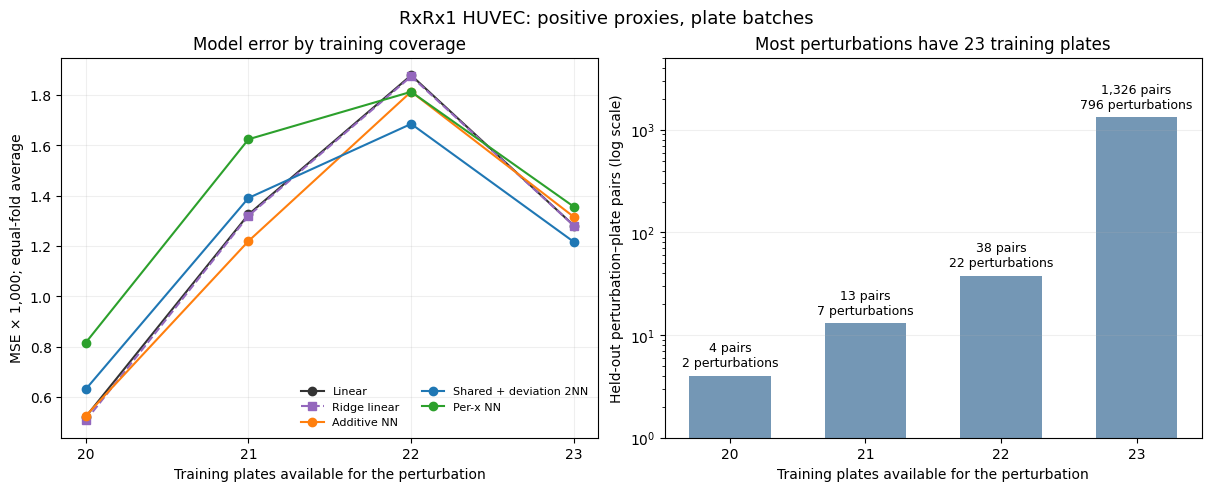

COVERAGE_EQUAL_FOLD_X1000 model                 linear  ridge linear  additive  shared + deviation (2 NNs)  per-x NN
n_training_batches                                                                        
20                  0.521795      0.506926  0.525380                    0.631296  0.816468
21                  1.325527      1.320069  1.219741                    1.391044  1.624400
22                  1.878681      1.874331  1.813436                    1.685417  1.812958
23                  1.281506      1.280834  1.315851                    1.216447  1.356333


COVERAGE_COUNTS                     test_pairs  distinct_perturbations  contributing_folds  test_pair_pct
n_training_batches                                                                       
20                           4                       2                   4       0.289645
21                          13                       7                   5       0.941347
22                          38                      22                   5       2.751629
23                        1326                     796                   5      96.017379


COVERAGE_2NN_IMPROVEMENT_PCT {20: -20.985472031854503, 21: -4.9427387079911345, 22: 10.287203193761885, 23: 5.07672450323946}


COVERAGE_ANALYSIS_COMPLETE /nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_results/coverage_analysis


In [2]:
# Condition evaluation on the number of training plates available per perturbation.
# Keep the main comparison's equal-fold weighting; also retain pooled-pair summaries.
import json
import hashlib

coverage_root=ROOT / "outputs/rxrx1_results"
coverage_dir=coverage_root / "coverage_analysis";coverage_dir.mkdir(exist_ok=True)
coverage_scores=pd.read_csv(coverage_root / "scores.csv",float_precision="round_trip")
coverage_models=["linear","ridge linear","additive","shared + deviation (2 NNs)","per-x NN"]
coverage_labels={"linear":"Linear","ridge linear":"Ridge linear","additive":"Additive NN",
                 "shared + deviation (2 NNs)":"Shared + deviation 2NN","per-x NN":"Per-x NN"}
coverage_keys=["batch","perturbation","metric"]
assert set(coverage_scores.ablation)=={"positive_plate"}
assert set(coverage_scores.metric)=={"mse"}
assert set(coverage_scores.model)==set(coverage_models)
assert not coverage_scores.duplicated(coverage_keys+["model"]).any()
assert coverage_scores.groupby(coverage_keys).model.nunique().eq(5).all()
assert coverage_scores.groupby(coverage_keys).n_training_batches.nunique().eq(1).all()
assert np.isfinite(coverage_scores.value).all()
coverage_base=coverage_scores.loc[coverage_scores.model.eq("linear")].copy()
coverage_counts=coverage_base.groupby("n_training_batches").agg(
    test_pairs=("value","size"),distinct_perturbations=("perturbation","nunique"),
    contributing_folds=("fold","nunique"))
coverage_counts["test_pair_pct"]=100*coverage_counts.test_pairs/coverage_counts.test_pairs.sum()
coverage_counts.to_csv(coverage_dir / "group_counts.csv")
coverage_base.groupby(["n_training_batches","fold"]).size().unstack("fold",fill_value=0).to_csv(coverage_dir / "fold_counts.csv")
coverage_per_fold=coverage_scores.groupby(["n_training_batches","fold","model"]).value.mean().unstack("model")[coverage_models]
coverage_equal=coverage_per_fold.groupby("n_training_batches").mean()
coverage_pooled=coverage_scores.groupby(["n_training_batches","model"]).value.mean().unstack("model")[coverage_models]
coverage_per_fold.to_csv(coverage_dir / "per_fold_mse.csv")
coverage_equal.to_csv(coverage_dir / "equal_fold_mse.csv")
coverage_pooled.to_csv(coverage_dir / "pooled_mse.csv")
coverage_improvements=100*(1-coverage_equal.div(coverage_equal["linear"],axis=0))
coverage_improvements.to_csv(coverage_dir / "improvement_vs_linear_pct.csv")
coverage_fold_improvements=100*(1-coverage_per_fold.div(coverage_per_fold["linear"],axis=0))
coverage_fold_improvements.to_csv(coverage_dir / "per_fold_improvement_vs_linear_pct.csv")
coverage_wins=(coverage_per_fold["shared + deviation (2 NNs)"]<coverage_per_fold["linear"]).groupby("n_training_batches").agg(["sum","count"])
coverage_wins.columns=["two_nn_beats_linear_folds","contributing_folds"]
coverage_wins.to_csv(coverage_dir / "two_nn_fold_consistency.csv")
coverage_identity=coverage_base.groupby("perturbation").n_training_batches.nunique()
coverage_checks={
    "definition":"number of outer-training plates with observed treatment crops for each held-out perturbation",
    "primary_averaging":"equal perturbations within each coverage-by-fold group, then equal weight to contributing folds",
    "secondary_averaging":"equal held-out perturbation-plate pairs pooled across folds",
    "unique_perturbations":int(len(coverage_identity)),
    "perturbations_observed_at_multiple_coverage_levels":int((coverage_identity>1).sum()),
    "monotonically_decreasing_mse_with_coverage":{m:bool(coverage_equal[m].is_monotonic_decreasing) for m in coverage_models},
    "winning_model_equal_fold":coverage_equal.idxmin(axis=1).to_dict(),
    "winning_model_pooled":coverage_pooled.idxmin(axis=1).to_dict(),
    "source_scores_sha256":hashlib.sha256((coverage_root / "scores.csv").read_bytes()).hexdigest(),
    "scope":{"cell_type":"HUVEC","proxy_mode":"positive_only","batch_unit":"plate"},
    "computed_utc":datetime.now(timezone.utc).isoformat(),
}
assert coverage_checks["winning_model_equal_fold"]==coverage_checks["winning_model_pooled"]
(coverage_dir / "analysis_checks.json").write_text(json.dumps(coverage_checks,indent=2))
display((coverage_equal*1000).style.highlight_min(axis=1,props="font-weight:bold;").format("{:.6f}"))
display(coverage_counts)

fig,axes=plt.subplots(1,2,figsize=(12,4.8),layout="constrained")
colors={"linear":"#333333","ridge linear":"#9467bd","additive":"#ff7f0e","shared + deviation (2 NNs)":"#1f77b4","per-x NN":"#2ca02c"}
for model in coverage_models:
    axes[0].plot(coverage_equal.index,coverage_equal[model]*1000,
        marker="s" if model=="ridge linear" else "o",linestyle="--" if model=="ridge linear" else "-",
        linewidth=1.5,color=colors[model],label=coverage_labels[model])
axes[0].set_ylabel("MSE × 1,000; equal-fold average")
axes[0].set_title("Model error by training coverage")
axes[0].legend(frameon=False,fontsize=8,ncol=2)
axes[0].grid(alpha=.2)
axes[1].bar(coverage_counts.index,coverage_counts.test_pairs,width=.6,color="#7497b5")
axes[1].set_yscale("log");axes[1].set_ylim(1,5000)
for count,row in coverage_counts.iterrows():
    axes[1].text(count,row.test_pairs*1.15,f"{int(row.test_pairs):,} pairs\n{int(row.distinct_perturbations):,} perturbations",ha="center",va="bottom",fontsize=9)
axes[1].set_ylabel("Held-out perturbation–plate pairs (log scale)")
axes[1].set_title("Most perturbations have 23 training plates")
axes[1].grid(axis="y",alpha=.2)
for ax in axes:
    ax.set_xticks(coverage_counts.index);ax.set_xlabel("Training plates available for the perturbation")
fig.suptitle("RxRx1 HUVEC: positive proxies, plate batches",fontsize=13)
fig.savefig(coverage_dir / "coverage_trends.png",dpi=180,bbox_inches="tight")
plt.show();plt.close(fig)

coverage_report=["# Performance conditioned on available training batches","",
"Scope: RxRx1 HUVEC, positive-control-only proxies, plate-level batches; the latest five-model comparison. Coverage counts the training plates containing each target perturbation. No models were retrained for this analysis.","",
"The primary table retains the original equal-fold averaging: average perturbation MSE within each coverage-by-fold group, then average contributing folds equally. The 20-batch group appears in four folds; all other groups appear in five. MSE × 1,000; lower is better; bold marks the best model.","",
"| Training plates | Test pairs | Distinct perturbations | "+" | ".join(coverage_labels.values())+" |",
"|---:|---:|---:|"+"---:|"*5]
for count,row in coverage_equal.iterrows():
    best=row.min();size=coverage_counts.loc[count]
    values=[("**"+f"{v*1000:.6f}"+"**") if v==best else f"{v*1000:.6f}" for v in row]
    coverage_report.append(f"| {count} | {int(size.test_pairs)} | {int(size.distinct_perturbations)} | "+" | ".join(values)+" |")
coverage_report += ["",
"Absolute MSE does not decrease monotonically with coverage for any model. These groups contain different perturbations: every perturbation in this evaluation has only one coverage level. Consequently the analysis cannot isolate the effect of providing more batches for the same perturbation.","",
f"The 2NN has {coverage_improvements.loc[22,'shared + deviation (2 NNs)']:.2f}% lower MSE than linear at 22 training plates and {coverage_improvements.loc[23,'shared + deviation (2 NNs)']:.2f}% lower at 23. It beats linear in 4/5 folds in both groups. It is worse on average at 20 and 21 plates, where ridge and additive respectively perform best.","",
f"The lower-coverage groups are small: 20 plates comprises 4 test pairs from only 2 distinct perturbations; 21 comprises 13 pairs from 7 perturbations. By contrast, 23 plates comprises {coverage_counts.loc[23,'test_pair_pct']:.2f}% of test pairs. Pooled-pair averaging changes some numerical values but preserves the winning model in every group.","",
"`per_fold_mse.csv` contains the conditional results within each fold; `equal_fold_mse.csv` is the primary table; `pooled_mse.csv` is the alternative pooling; `group_counts.csv` and `fold_counts.csv` show group sizes. `two_nn_fold_consistency.csv` and the improvement CSVs retain the paired model comparisons. `analysis_checks.json` records the scope and score-file hash.",""]
(coverage_dir / "README.md").write_text("\n".join(coverage_report))
index=coverage_root / "README.md"
text=index.read_text()
link="- [Results conditioned on available training batches](coverage_analysis/README.md)"
if link not in text:
    text=text.replace("## Run-specific detail",link+"\n\n## Run-specific detail")
    index.write_text(text)
print("COVERAGE_EQUAL_FOLD_X1000",(coverage_equal*1000).to_string(),flush=True)
print("COVERAGE_COUNTS",coverage_counts.to_string(),flush=True)
print("COVERAGE_2NN_IMPROVEMENT_PCT",coverage_improvements["shared + deviation (2 NNs)"].to_dict(),flush=True)
print("COVERAGE_ANALYSIS_COMPLETE",coverage_dir,flush=True)


# Performance conditioned on available training batches

Scope: RxRx1 HUVEC, positive-control-only proxies, plate-level batches; the latest five-model comparison. Coverage counts the training plates containing each target perturbation. No models were retrained for this analysis.

The primary table retains the original equal-fold averaging: average perturbation MSE within each coverage-by-fold group, then average contributing folds equally. The 20-batch group appears in four folds; all other groups appear in five. MSE × 1,000; lower is better; bold marks the best model.

| Training plates | Test pairs | Distinct perturbations | Linear | Ridge linear | Additive NN | Shared + deviation 2NN | Per-x NN |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 20 | 4 | 2 | 0.521795 | **0.506926** | 0.525380 | 0.631296 | 0.816468 |
| 21 | 13 | 7 | 1.325527 | 1.320069 | **1.219741** | 1.391044 | 1.624400 |
| 22 | 38 | 22 | 1.878681 | 1.874331 | 1.813436 | **1.685417** | 1.812958 |
| 23 | 1326 | 796 | 1.281506 | 1.280834 | 1.315851 | **1.216447** | 1.356333 |

Absolute MSE does not decrease monotonically with coverage for any model. These groups contain different perturbations: every perturbation in this evaluation has only one coverage level. Consequently the analysis cannot isolate the effect of providing more batches for the same perturbation.

The 2NN has 10.29% lower MSE than linear at 22 training plates and 5.08% lower at 23. It beats linear in 4/5 folds in both groups. It is worse on average at 20 and 21 plates, where ridge and additive respectively perform best.

The lower-coverage groups are small: 20 plates comprises 4 test pairs from only 2 distinct perturbations; 21 comprises 13 pairs from 7 perturbations. By contrast, 23 plates comprises 96.02% of test pairs. Pooled-pair averaging changes some numerical values but preserves the winning model in every group.

`per_fold_mse.csv` contains the conditional results within each fold; `equal_fold_mse.csv` is the primary table; `pooled_mse.csv` is the alternative pooling; `group_counts.csv` and `fold_counts.csv` show group sizes. `two_nn_fold_consistency.csv` and the improvement CSVs retain the paired model comparisons. `analysis_checks.json` records the scope and score-file hash.


**Hybrid linear + shared/deviation 2NN bridge**

For output coordinate \(g\), fit
\[
\widehat Y_g(x,e)=\bar Y_g+a_{xg}+\beta_g\widetilde\mu_{eg}
 +c_g^\top z_e^{(1)}+d_{xg}^\top z_e^{(2)},\qquad
 z_e^{(k)}=\mathbb E[\phi_k(W)\mid e].
\]
The user requested two separate NN embeddings. The raw proxy term is coordinate-wise, matching the existing linear transfer model. All readouts are solved jointly by count-weighted ridge inside the NN loss. The target mean and proxy standardisation are fitted on training data only. The shared/intercept penalty and deviation penalty match the existing 2NN convention; a separate ridge controls the raw-linear slopes. Infinite raw-linear penalty exactly recovers the existing shared/deviation 2NN.

Eliminate perturbation-specific blocks, solve the shared NN system, then eliminate its coupling to the coordinate-wise raw slope. The loss uses sufficient-statistic contractions and never materialises category × environment × output predictions. Observed environments are compacted per perturbation; an optional fold checkpoint flag is available to bound memory. Use only HUVEC, positive-control-only proxies, plate batches, and the same five outer/four inner validation splits. Lock HPs and checkpoint selection before outer scoring.


In [5]:
import copy
import json
import hashlib
from dataclasses import dataclass,field
from genetic_perturbation_playground.model.batch_transfer import _mean_and_std

HYBRID_NN_REFERENCE=ROOT / "outputs/rxrx1_huvec_nested_hp_20261118T111217794502Z"
HYBRID_LINEAR_REFERENCE=ROOT / "outputs/rxrx1_huvec_ridge_linear_positive_plate_hp_20261118T152406164238Z"
HYBRID_SETTINGS={"id":"positive_plate","proxy_mode":"positive_only","batch_unit":"plate"}
HYBRID_NAME="linear + shared/deviation 2NN"
HP_CHECKPOINTS=(0,10,20,40,60,100,150,200,300,400)
HP_SCREEN_STEPS,HP_MAX_STEPS=100,400
hp_base_cfg=OmegaConf.load(HYBRID_NN_REFERENCE / "base_config.yaml")
hp_base_cfg.neural.device="cuda" if torch.cuda.is_available() else "cpu"
hybrid_resume=globals().get("HYBRID_RESUME_DIR")
hybrid_dir=Path(hybrid_resume) if hybrid_resume else ROOT / "outputs" / ("rxrx1_huvec_hybrid_2nn_positive_plate_hp_"+datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ"))
hybrid_dir.mkdir(exist_ok=bool(hybrid_resume))
hybrid_reference_scores=pd.read_csv(HYBRID_LINEAR_REFERENCE / "combined_scores.csv")
hybrid_reference_scores.to_csv(hybrid_dir / "reference_scores.csv",index=False)
hybrid_manifest={"cell_type":"HUVEC","proxy_mode":"positive_only","batch_unit":"plate",
    "model":"a_x + beta * mean(W) + c^T z_shared + d_x^T z_deviation",
    "networks":2,"linear_term":"coordinate-wise; training-standardised W",
    "penalties":"reg on intercept/shared NN, deviation_reg on per-x NN, linear_reg on raw slope; all multiplied by N",
    "outer_folds":5,"inner_plates":4,"selection_metric":"equal-inner-plate mean treatment MSE",
    "outer_scores_used_for_selection":False,"max_steps":HP_MAX_STEPS,"screen_steps":HP_SCREEN_STEPS,
    "checkpoints":list(HP_CHECKPOINTS),"nn_reference":str(HYBRID_NN_REFERENCE),"linear_reference":str(HYBRID_LINEAR_REFERENCE),
    "source_hashes":{str(p):hashlib.sha256(p.read_bytes()).hexdigest() for p in [
        ROOT / "src/genetic_perturbation_playground/model/batch_transfer.py",
        ROOT / "src/genetic_perturbation_playground/model/proxy_unconfounded_neural.py",
        ROOT / "scripts/train_batch_transfer_rxrx1.py"]}}
(hybrid_dir / "manifest.json").write_text(json.dumps(hybrid_manifest,indent=2))
OmegaConf.save(hp_base_cfg,hybrid_dir / "base_config.yaml")
print("HYBRID_RUN_DIR",hybrid_dir,flush=True)


HYBRID_RUN_DIR /nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_hybrid_2nn_positive_plate_hp_20261118T154549800734Z


In [7]:
@dataclass
class LinearTwoNetworkSharedDeviationBridge(TwoNetworkSharedDeviationNeuralBridge):
    linear_reg: float = 1e-3
    checkpoint_folds: bool = False

    def __post_init__(self):
        super().__post_init__()
        if np.isnan(self.linear_reg) or self.linear_reg<0:
            raise ValueError("linear_reg must be nonnegative")

    @staticmethod
    def hybrid_data(grouped):
        m=torch.stack([w.mean(dim=0) for w in grouped.w_envs])
        if m.shape[1]!=grouped.cy.shape[-1]:
            raise ValueError("Coordinate-wise linear transfer requires matching proxy/target dimensions")
        # Each RxRx1 perturbation occurs on at most 24 of the 96 plates.
        # Compact observed environments per perturbation; zero padding has zero count.
        G,E=grouped.c.shape;J=grouped.cy.shape[-1]
        length=int((grouped.c>0).sum(dim=1).max().item())
        env=torch.arange(E,device=grouped.c.device).expand(G,-1)
        ordered=torch.where(grouped.c>0,env,E).sort(dim=1).values[:,:length]
        valid=ordered<E;index=ordered.clamp_max(E-1)
        c=grouped.c.gather(1,index)*valid
        cy=grouped.cy.gather(1,index[:,:,None].expand(-1,-1,J))*valid[:,:,None]
        return SimpleNamespace(c=grouped.c,cy=grouped.cy,cyy=grouped.cyy,
            target_gram=grouped.target_gram,w_envs=grouped.w_envs,
            cy_env=grouped.cy.sum(dim=0),raw_mean=m,observed_index=index,observed_valid=valid,
            observed_c=c,observed_cy=cy,observed_raw=m[index])

    def _to_tensors(self,xs,ys,ws,counts):
        return self.hybrid_data(super()._to_tensors(xs,ys,ws,counts))

    def _hybrid_coefficients(self,data,z,fit):
        zs,zd=self._split_embeddings(z)
        h_all=torch.cat([torch.ones_like(zd[:,:1]),zd],dim=1)
        index=data.observed_index;h=h_all[index];shared_design=zs[index]
        fit_observed=fit[index]&data.observed_valid
        counts=data.observed_c*fit_observed;total=counts.sum()
        penalties=z.new_full((h.shape[-1],),self.deviation_reg);penalties[0]=self.reg
        local_gram=h.transpose(1,2)@(counts[:,:,None]*h)+total*torch.diag(penalties)
        U=h.transpose(1,2)@(counts[:,:,None]*shared_design)
        h_fit=(h*fit_observed[:,:,None]).transpose(1,2)
        maps=torch.linalg.solve(local_gram,torch.cat([h_fit,U],dim=2))
        L=h.shape[1];R,T=maps[:,:,:L],maps[:,:,L:]
        global_counts=data.c*fit
        K=zs.T@(global_counts.sum(dim=0)[:,None]*zs)-(U.transpose(1,2)@T).sum(dim=0)
        K=K+self.reg*total*torch.eye(zs.shape[1],dtype=z.dtype,device=z.device)
        local_zero=R@data.observed_cy
        raw_local=(R*data.observed_c[:,None,:])@data.observed_raw
        raw_cross=(h.transpose(1,2)*counts[:,None,:])@data.observed_raw
        z_fit=zs*fit[:,None];m=data.raw_mean
        shared_rhs=z_fit.T@data.cy_env-(U.transpose(1,2)@local_zero).sum(dim=0)
        shared_raw=z_fit.T@(global_counts.sum(dim=0)[:,None]*m)-(U.transpose(1,2)@raw_local).sum(dim=0)
        raw_rhs=(m*data.cy_env*fit[:,None]).sum(dim=0)-(raw_cross*local_zero).sum(dim=(0,1))
        raw_gram=(global_counts.sum(dim=0)[:,None]*m.square()).sum(dim=0)-(raw_cross*raw_local).sum(dim=(0,1))
        J=data.cy.shape[-1]
        solved=torch.linalg.solve(K,torch.cat([shared_rhs,shared_raw],dim=1))
        shared_zero,shared_raw_map=solved[:,:J],solved[:,J:]
        denominator=raw_gram+self.linear_reg*total-(shared_raw*shared_raw_map).sum(dim=0)
        numerator=raw_rhs-(shared_raw*shared_zero).sum(dim=0)
        tolerance=100*torch.finfo(z.dtype).eps*(raw_gram.abs()+self.linear_reg*total).clamp_min(1.)
        if (denominator < -tolerance).any().item():
            raise FloatingPointError("Negative raw-linear Schur complement")
        supported=denominator>tolerance
        safe_denominator=torch.where(supported,denominator,torch.ones_like(denominator))
        raw=torch.where(supported,numerator/safe_denominator,torch.zeros_like(numerator))
        shared=shared_zero-shared_raw_map*raw
        local=local_zero-T@shared-raw_local*raw
        return h,local,shared,raw

    def _fit_and_score_sse(self,data,z,fit,scored):
        if np.isinf(self.linear_reg):
            return super()._fit_and_score_sse(data,z,fit,scored)
        h,local,shared,raw=self._hybrid_coefficients(data,z,fit)
        zs,_=self._split_embeddings(z)
        effect=zs@shared+data.raw_mean*raw
        score_observed=scored[data.observed_index]&data.observed_valid
        counts=data.observed_c*score_observed
        target_sum=(h.transpose(1,2)*score_observed[:,None,:])@data.observed_cy
        cross=(local*target_sum).sum()+(effect*data.cy_env*scored[:,None]).sum()
        local_gram=h.transpose(1,2)@(counts[:,:,None]*h)
        quadratic=(local*(local_gram@local)).sum()
        mixed=(h.transpose(1,2)*counts[:,None,:])@effect[data.observed_index]
        quadratic=quadratic+2*(local*mixed).sum()+((data.c*scored).sum(dim=0)[:,None]*effect.square()).sum()
        return data.cyy[scored].sum()+(quadratic-2*cross)/data.cy.shape[-1]

    def _training_loss(self,data):
        if np.isinf(self.linear_reg):return super()._training_loss(data)
        z=self._embed(data.w_envs)
        if self.cross_fit_folds:
            fold=self._env_folds(len(z))
            if self.checkpoint_folds:
                sse=sum(checkpoint(self._fit_and_score_sse,data,z,fold!=k,fold==k,use_reentrant=False)
                        for k in range(int(fold.max())+1))
            else:
                sse=sum(self._fit_and_score_sse(data,z,fold!=k,fold==k)
                        for k in range(int(fold.max())+1))
        else:
            fit=torch.ones(len(z),dtype=torch.bool,device=z.device)
            sse=self._fit_and_score_sse(data,z,fit,fit)
        return sse/data.c.sum()

    @torch.no_grad()
    def _solve_A(self,data):
        if np.isinf(self.linear_reg):
            super()._solve_A(data)
            self.linear_coef_=data.cy.new_zeros(data.cy.shape[-1]);return
        z=self._embed(data.w_envs)
        fit=torch.ones(len(z),dtype=torch.bool,device=z.device)
        _,local,self.b_,self.linear_coef_=self._hybrid_coefficients(data,z,fit)
        self.a_,self.c_=local[:,0],local[:,1:]

    def predict(self,x,w_target):
        with torch.no_grad():
            w=_tensor(w_target,self.device)
            zs=self.psi_b_(w).mean(dim=0);zd=self.psi_c_(w).mean(dim=0)
            pred=self.a_+w.mean(dim=0)*self.linear_coef_+zs@self.b_+zd@self.c_
            category=_tensor(x,self.device).argmax(dim=1)
            return pred[category].cpu().numpy()


In [9]:
# Independent full-design ridge solves verify coefficients, held-out SSE, and gradients.
rng=np.random.default_rng(819)
G,E,J,q=3,7,4,2
xs=[];ys=[];ws=[];counts=[]
for e in range(E):
    keep=np.arange(G)!=1 if e==2 else np.ones(G,dtype=bool)
    xs.append(np.eye(G)[keep]);ys.append(rng.normal(size=(int(keep.sum()),J)))
    ws.append(rng.normal(size=(8,J)));counts.append(rng.integers(1,7,size=int(keep.sum())))
model=LinearTwoNetworkSharedDeviationBridge(reg=.003,deviation_reg=.007,linear_reg=.002,
    n_features_w=q,width_w=8,depth=1,cross_fit_folds=3,device="cpu",seed=1)
data=model._to_tensors(xs,ys,ws,counts)
fit=torch.tensor([True,True,False,True,False,True,True]);scored=~fit
z=torch.tensor(rng.normal(size=(E,2*q)),dtype=torch.float64,requires_grad=True)

def full_design_solution(z,linear_reg):
    zs,zd=z.split(q,dim=1);h=torch.cat([torch.ones_like(zd[:,:1]),zd],dim=1)
    blocks=torch.eye(G,dtype=z.dtype)[:,None,:,None]*h[None,:,None,:]
    local_design=blocks.reshape(G*E,G*(q+1))
    shared_design=zs.unsqueeze(0).expand(G,-1,-1).reshape(G*E,q)
    row_weight=(data.c*fit).reshape(-1)
    y=data.cy/data.c.clamp_min(1)[:,:,None]
    coef=[];loss=z.new_zeros(())
    local_penalty=torch.tensor([model.reg]+[model.deviation_reg]*q,dtype=z.dtype).repeat(G)
    penalties=torch.cat([local_penalty,z.new_full((q,),model.reg),z.new_tensor([linear_reg])])*row_weight.sum()
    for j in range(J):
        raw=data.raw_mean[:,j].unsqueeze(0).expand(G,-1).reshape(-1,1)
        design=torch.cat([local_design,shared_design,raw],dim=1)
        gram=design.T@(row_weight[:,None]*design)+torch.diag(penalties)
        rhs=design.T@(data.cy[:,:,j]*fit).reshape(-1)
        beta=torch.linalg.solve(gram,rhs);coef.append(beta)
        pred=(design@beta).reshape(G,E)
        loss=loss+((pred-y[:,:,j]).square()*data.c*scored).sum()/J
    return torch.stack(coef,dim=1),loss

check_rows=[]
for raw_reg in [0.,.002,.1]:
    model.linear_reg=raw_reg
    _,local,shared,raw=model._hybrid_coefficients(data,z,fit)
    full,expected=full_design_solution(z,raw_reg)
    actual_coeff=torch.cat([local.reshape(G*(q+1),J),shared,raw[None]],dim=0)
    torch.testing.assert_close(actual_coeff,full,rtol=1e-7,atol=1e-9)
    actual=model._fit_and_score_sse(data,z,fit,scored)
    torch.testing.assert_close(actual,expected,rtol=1e-8,atol=1e-9)
    grad_actual=torch.autograd.grad(actual,z,retain_graph=True)[0]
    grad_expected=torch.autograd.grad(expected,z,retain_graph=True)[0]
    torch.testing.assert_close(grad_actual,grad_expected,rtol=1e-6,atol=1e-8)
    check_rows.append({"linear_reg":raw_reg,"joint_coefficients":True,"heldout_sse":True,"embedding_gradient":True})
model.linear_reg=float("inf")
old=TwoNetworkSharedDeviationNeuralBridge(reg=model.reg,deviation_reg=model.deviation_reg,n_features_w=q,width_w=8,depth=1,device="cpu")
actual=model._fit_and_score_sse(data,z,fit,scored);expected=old._fit_and_score_sse(data,z,fit,scored)
torch.testing.assert_close(actual,expected,rtol=1e-12,atol=1e-12)
model.linear_reg=.002;model.n_steps=3
model.fit(xs,ys,ws,counts)
assert np.isfinite(model.predict(xs[0],ws[0])).all()
assert torch.isfinite(model.linear_coef_).all()
pd.DataFrame(check_rows).to_csv(hybrid_dir / "implementation_checks.csv",index=False)
del model,old,data,z,xs,ys,ws,counts,actual,expected,full,actual_coeff,local,shared,raw,grad_actual,grad_expected
print("HYBRID_DENSE_COEFFICIENT_LOSS_GRADIENT_CHECKS_PASSED",flush=True)


HYBRID_DENSE_COEFFICIENT_LOSS_GRADIENT_CHECKS_PASSED


In [8]:
def hybrid_spec(ridge=1e-4,deviation_ridge=1e-4,linear_reg=1e-3,features=16,width=32,lr=.00075,weight_decay=.0001):
    return {"ridge":float(ridge),"deviation_ridge":float(deviation_ridge),
        "linear_reg":"inf" if np.isinf(float(linear_reg)) else float(linear_reg),
        "features":int(features),"width":int(width),"lr":float(lr),"weight_decay":float(weight_decay)}


def hybrid_config(spec):
    config=hp_config(HYBRID_SETTINGS,spec)
    config.name="rxrx1_hybrid_2nn_positive_plate_nested_hp"
    config.neural.linear_reg=float(spec["linear_reg"])
    config.neural.lr=spec["lr"];config.neural.weight_decay=spec["weight_decay"]
    return config


def hybrid_prepare(train,config):
    prepared=hp_prepare(train,config)
    prepared.data["hybrid_2nn"]=LinearTwoNetworkSharedDeviationBridge.hybrid_data(prepared.data["shared_2nn"])
    return prepared


def hybrid_candidate(spec,data,candidate_id):
    config=hybrid_config(spec);config.neural.device=str(data.c.device)
    options=OmegaConf.to_container(config.neural,resolve=True);options.pop("per_perturbation",None)
    model=LinearTwoNetworkSharedDeviationBridge(reg=config.bridge_reg,seed=config.neural_seed,**options)
    torch.manual_seed(model.seed);model._build_networks(data)
    initial={k:v.detach().cpu().clone() for k,v in model.psi_.state_dict().items()}
    optimizer=torch.optim.AdamW(model.psi_.parameters(),lr=model.lr,weight_decay=model.weight_decay)
    return HPCandidate("hybrid_2nn",copy.deepcopy(spec),config,model,optimizer,torch.get_rng_state().clone(),initial,candidate_id)


def hybrid_advance(candidate,data,queries,y_mean,target_step,capture_steps=()):
    hp_advance(candidate,data,queries,y_mean,target_step,capture_steps=capture_steps)
    for key in ["a_","b_","c_","linear_coef_"]:
        if not torch.isfinite(getattr(candidate.model,key)).all().item():
            raise FloatingPointError(f"Non-finite fitted {key}")


def hybrid_trial(candidate,prepared,queries,target_step,directory):
    start=time.perf_counter()
    try:
        hybrid_advance(candidate,prepared.data["hybrid_2nn"],queries,prepared.y_mean,target_step)
    except (FloatingPointError,torch.linalg.LinAlgError) as exc:
        candidate.failed=repr(exc);candidate.best_mse=float("inf")
    pd.DataFrame(candidate.records).to_csv(directory/f"{candidate.candidate_id}_curves.csv",index=False)
    pd.DataFrame(candidate.train_records).to_csv(directory/f"{candidate.candidate_id}_training.csv",index=False)
    status={"candidate":candidate.candidate_id,"variant":"hybrid_2nn",**candidate.spec,
        "completed_step":candidate.step,"best_step":candidate.best_step,"inner_mse":candidate.best_mse,
        "failed":candidate.failed,"last_stage_seconds":time.perf_counter()-start}
    (directory/f"{candidate.candidate_id}_status.json").write_text(json.dumps(status,indent=2))
    print("HYBRID_TRIAL",json.dumps(status),flush=True)
    return candidate


def hybrid_adapter(candidate,prepared):
    options=OmegaConf.to_container(candidate.config.neural,resolve=True)
    adapter=with_standardisation(NeuralBridgeTransfer(weight_by_cells=candidate.config.weight_by_cells,
        reg=candidate.config.bridge_reg,seed=candidate.config.neural_seed,**options),candidate.config)
    adapter.w_mean_,adapter.w_std_,adapter.y_mean_=prepared.w_mean,prepared.w_std,prepared.y_mean
    adapter.model.perturbations_=prepared.perturbations;adapter.model.bridge_=candidate.model
    return adapter


def hybrid_save(candidate,prepared,selection,batch,fold,path):
    config=OmegaConf.to_container(candidate.config,resolve=False)
    config["neural"]["n_steps"]=int(selection["selected_step"])
    model=candidate.model
    torch.save({"variant":"hybrid_2nn","config":config,"selection":selection,"held_out_batch":batch,"fold":fold,
        "selected_step":int(selection["selected_step"]),"diagnostic_max_steps":candidate.step,
        "perturbations":prepared.perturbations.tolist(),"a":model.a_.detach().cpu(),
        "b_shared_nn":model.b_.detach().cpu(),"c_deviation_nn":model.c_.detach().cpu(),
        "raw_linear_coef":model.linear_coef_.detach().cpu(),
        "psi_state_dict":{k:v.detach().cpu() for k,v in model.psi_.state_dict().items()},
        "w_mean":torch.as_tensor(prepared.w_mean),"w_std":torch.as_tensor(prepared.w_std),"y_mean":torch.as_tensor(prepared.y_mean)},path)


In [10]:
# Real-data memory/time check; this is not used for HP selection.
if "raw_adata" not in globals():
    raw_adata=select_cell_type(load_rxrx1(**hp_base_cfg.embeddings),"HUVEC").copy()
assert raw_adata.obs.cell_type.astype(str).eq("HUVEC").all()
hybrid_adata=prepare_ablation(raw_adata,hybrid_config(hybrid_spec()))
hybrid_batches=batch_labels(hybrid_adata)
split=json.loads((HYBRID_NN_REFERENCE/"positive_plate/fold_1/split.json").read_text())
fit=hybrid_adata[~np.isin(hybrid_batches,[split["outer_batch"],*split["inner_validation_batches"]])]
prepared=hybrid_prepare(fit,hybrid_config(hybrid_spec()))
data=prepared.data["hybrid_2nn"]
profile_rows=[]
for features,width in [(16,32),(32,64),(64,64)]:
    candidate=hybrid_candidate(hybrid_spec(features=features,width=width),data,"profile")
    for step in range(5):
        if torch.cuda.is_available():
            torch.cuda.synchronize();torch.cuda.reset_peak_memory_stats()
        start=time.perf_counter();candidate.optimizer.zero_grad()
        loss=candidate.model._training_loss(data)
        assert torch.isfinite(loss)
        loss.backward()
        branch_norms={key:float(sum(p.grad.square().sum().item() for p in net.parameters() if p.grad is not None))
                      for key,net in candidate.model.psi_.items()}
        assert all(v>0 for v in branch_norms.values())
        candidate.optimizer.step()
        if torch.cuda.is_available():torch.cuda.synchronize()
        elapsed=time.perf_counter()-start
        profile_rows.append({"features":features,"width":width,"step":step,"seconds":elapsed,"loss":float(loss.item()),
            "shared_gradient_squared_norm":branch_norms["b"],"deviation_gradient_squared_norm":branch_norms["c"],
            "peak_allocated_GiB":torch.cuda.max_memory_allocated()/1024**3 if torch.cuda.is_available() else None})
    del candidate
    gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
pd.DataFrame(profile_rows).to_csv(hybrid_dir / "real_data_compact_profile.csv",index=False)
print("HYBRID_REAL_DATA_PROFILE",pd.DataFrame(profile_rows).to_string(index=False),flush=True)
del prepared,data,fit,loss
if torch.cuda.is_available():torch.cuda.empty_cache()


Loaded /nfs/ghome/live/adhir/genetic_playground/data/rxrx1_phenom_4x4.h5ad
  2,008,160 crops  ×  384 features  |  1,139 perturbations


HYBRID_REAL_DATA_PROFILE  features  width  step  seconds     loss  shared_gradient_squared_norm  deviation_gradient_squared_norm  peak_allocated_GiB
       16     32     0 0.636670 0.001484                  2.206045e-07                     1.465045e-08            3.768974
       16     32     1 0.607847 0.001457                  1.948249e-08                     3.432480e-08            3.769388
       16     32     2 0.362885 0.001442                  1.277059e-08                     5.556113e-08            3.769388
       16     32     3 0.358906 0.001421                  8.096511e-09                     5.777643e-08            3.769388
       16     32     4 0.365561 0.001397                  7.154149e-09                     3.549456e-08            3.769388
       32     64     0 0.668088 0.001484                  1.320998e-07                     2.292603e-08            6.078699
       32     64     1 0.619874 0.001445                  2.324809e-08                     5.293150e-08    

In [10]:
def hybrid_search(fold,prepared,queries,directory):
    directory.mkdir(parents=True,exist_ok=True)
    cached=directory / "selection.json"
    if cached.exists():
        print("HYBRID_REUSE_SELECTION",str(cached),flush=True);return json.loads(cached.read_text())
    prior=pd.read_csv(HYBRID_NN_REFERENCE / "selected_hyperparameters.csv",float_precision="round_trip")
    prior=prior.loc[prior.ablation.eq("positive_plate")&prior.fold.eq(fold)&prior.variant.eq("shared_2nn")].iloc[0]
    linear_prior=pd.read_csv(HYBRID_LINEAR_REFERENCE / "selected_hyperparameters.csv",float_precision="round_trip")
    linear_prior=linear_prior.loc[linear_prior.fold.eq(fold)].iloc[0]
    anchor=hybrid_spec(prior.ridge,prior.deviation_ridge,1e-3,prior.features,prior.width)
    candidates=[]
    def trial(spec,label):
        for c in candidates:
            if c.spec==spec:return c
        candidate=hybrid_candidate(spec,prepared.data["hybrid_2nn"],label)
        candidates.append(hybrid_trial(candidate,prepared,queries,HP_SCREEN_STEPS,directory))
        return candidate
    def best_finite():
        return hp_rank([c for c in candidates if np.isfinite(float(c.spec["linear_reg"]))])[0]
    for i,value in enumerate([0.,1e-4,1e-3,1e-2,.1,"inf",float(linear_prior.ridge)]):
        trial({**anchor,"linear_reg":value},f"hybrid_raw_{i:02d}")
    baseline=next(c for c in candidates if np.isinf(float(c.spec["linear_reg"])))
    anchor=copy.deepcopy(best_finite().spec)
    for i,ridge in enumerate([1e-6,1e-5,1e-4,1e-3]):
        trial({**anchor,"ridge":ridge},f"hybrid_shared_{i:02d}")
    anchor=copy.deepcopy(best_finite().spec)
    for i,ridge in enumerate([1e-6,1e-4,1e-2]):
        trial({**anchor,"deviation_ridge":ridge},f"hybrid_deviation_{i:02d}")
    anchor=copy.deepcopy(best_finite().spec)
    for features,width in [(8,16),(16,32),(32,64),(64,64)]:
        trial({**anchor,"features":features,"width":width},f"hybrid_capacity_{features}")
    anchor=copy.deepcopy(best_finite().spec)
    trial({**anchor,"lr":.00025},"hybrid_slow_lr")
    trial({**anchor,"lr":.0015},"hybrid_fast_lr")
    trial({**anchor,"weight_decay":.1},"hybrid_weight_decay")
    promoted=hp_rank(candidates)[:2]
    # Always recover the earlier 2NN validation result as a zero-linear reference.
    if all(c is not baseline for c in promoted):promoted.append(baseline)
    promoted_ids={c.candidate_id for c in promoted}
    pd.DataFrame([{**c.spec,"candidate":c.candidate_id,"inner_mse":c.best_mse,
        "best_step":c.best_step,"failed":c.failed,"promoted":c.candidate_id in promoted_ids}
        for c in candidates]).to_csv(directory / "screening.csv",index=False)
    for candidate in promoted:
        if candidate.failed is None:hybrid_trial(candidate,prepared,queries,HP_MAX_STEPS,directory)
    assert baseline.failed is None
    np.testing.assert_allclose(baseline.best_mse,float(prior.inner_mse),rtol=1e-6,atol=1e-10)
    assert baseline.best_step==int(prior.selected_step)
    chosen=hp_rank(candidates)[0]
    selection={"variant":"hybrid_2nn",**chosen.spec,"candidate":chosen.candidate_id,
        "selected_step":chosen.best_step,"inner_mse":chosen.best_mse,"n_candidates":len(candidates),
        "promoted":sorted(promoted_ids),"baseline_2nn_inner_mse":baseline.best_mse,
        "baseline_2nn_selected_step":baseline.best_step,"baseline_2nn_reproduced":True,
        "inner_improvement_vs_2nn_pct":100*(1-chosen.best_mse/baseline.best_mse)}
    cached.write_text(json.dumps(selection,indent=2))
    print("HYBRID_SELECTED",json.dumps(selection),flush=True)
    return selection


In [11]:
hybrid_manifest.update({"compact_observed_design":True,"checkpoint_folds":False,
    "raw_ridge_grid":[0.,1e-4,1e-3,1e-2,.1,"inf","previous inner-selected linear ridge"],
    "shared_ridge_grid":[1e-6,1e-5,1e-4,1e-3],"deviation_ridge_grid":[1e-6,1e-4,1e-2],
    "capacity_grid":[[8,16],[16,32],[32,64],[64,64]],"learning_rates":[.00025,.00075,.0015],
    "weight_decays":[.0001,.1],"promotion":"two best candidates plus original 2NN reference if not already included",
    "anchor":"previous 2NN HPs chosen on the same inner split, then stagewise best finite-linear candidate"})
(hybrid_dir / "manifest.json").write_text(json.dumps(hybrid_manifest,indent=2))
if "raw_adata" not in globals():raw_adata=select_cell_type(load_rxrx1(**hp_base_cfg.embeddings),"HUVEC").copy()
if "hybrid_adata" not in globals():hybrid_adata=prepare_ablation(raw_adata,hybrid_config(hybrid_spec()))
hybrid_batches=batch_labels(hybrid_adata)
assert hybrid_adata.obs.cell_type.astype(str).eq("HUVEC").all()
hybrid_adata.obs.groupby(["batch","experiment_batch","plate","well_type"],observed=True).size().rename("crops").to_csv(hybrid_dir / "data_audit.csv")
hybrid_score_rows=[pd.read_csv(hybrid_dir / "hybrid_scores.csv")] if (hybrid_dir / "hybrid_scores.csv").exists() else []
hybrid_choices=pd.read_csv(hybrid_dir / "selected_hyperparameters.csv").to_dict("records") if (hybrid_dir / "selected_hyperparameters.csv").exists() else []
hybrid_curve_rows=[pd.read_csv(hybrid_dir / "outer_learning_curves.csv")] if (hybrid_dir / "outer_learning_curves.csv").exists() else []
hybrid_weight_rows=pd.read_csv(hybrid_dir / "network_parameter_audit.csv").to_dict("records") if (hybrid_dir / "network_parameter_audit.csv").exists() else []
for fold in range(5):
    d=hybrid_dir / f"fold_{fold+1}";d.mkdir(exist_ok=True)
    if (d / "completed.json").exists():print("HYBRID_REUSE_FOLD",fold+1,flush=True);continue
    split=json.loads((HYBRID_NN_REFERENCE / "positive_plate" / f"fold_{fold+1}" / "split.json").read_text())
    batch=split["outer_batch"];inner=split["inner_validation_batches"]
    outer_train=hybrid_adata[hybrid_batches!=batch]
    inner_train=outer_train[~np.isin(batch_labels(outer_train),inner)]
    assert sorted(np.unique(batch_labels(outer_train)))==split["outer_training_batches"]
    assert sorted(np.unique(batch_labels(inner_train)))==split["inner_training_batches"]
    assert batch not in inner and set(inner).isdisjoint(batch_labels(inner_train))
    (d / "split.json").write_text(json.dumps(split,indent=2))
    print("HYBRID_FOLD_START",fold+1,batch,"inner validation",inner,flush=True)
    prepared=hybrid_prepare(inner_train,hybrid_config(hybrid_spec()))
    queries=hp_queries(outer_train,inner,prepared)
    selection=hybrid_search(fold,prepared,queries,d / "trials")
    (d / "locked_selection.json").write_text(json.dumps(selection,indent=2))
    hybrid_choices.append({"fold":fold,"batch":batch,**selection})
    pd.DataFrame(hybrid_choices).drop_duplicates("fold",keep="last").to_csv(hybrid_dir / "selected_hyperparameters.csv",index=False)
    del prepared,queries,inner_train
    gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
    test=hybrid_adata[hybrid_batches==batch]
    reference=hybrid_reference_scores.loc[hybrid_reference_scores.batch.eq(batch)]
    ref_linear=reference.loc[reference.model.eq("linear")]
    ref_nn=reference.loc[reference.model.eq("shared + deviation (2 NNs)")]
    linear=BatchTransferModel(standardise_w=hp_base_cfg.standardise_w).fit(outer_train)
    check=score_batch({"linear":linear},test).merge(ref_linear,on=["perturbation","metric"],suffixes=("_new","_old"),validate="one_to_one")
    assert len(check)==len(ref_linear)
    np.testing.assert_allclose(check.value_new,check.value_old,rtol=1e-9,atol=1e-11)
    del linear
    spec={k:selection[k] for k in ["ridge","deviation_ridge","linear_reg","features","width","lr","weight_decay"]}
    config=hybrid_config(spec)
    prepared=hybrid_prepare(outer_train,config);queries=hp_queries(test,[batch],prepared)
    candidate=hybrid_candidate(spec,prepared.data["hybrid_2nn"],"outer_refit")
    stop=int(selection["selected_step"])
    hybrid_advance(candidate,prepared.data["hybrid_2nn"],queries,prepared.y_mean,HP_MAX_STEPS,capture_steps=[stop])
    curves=pd.DataFrame(candidate.records).assign(fold=fold,model=HYBRID_NAME,selected_step=stop,
        linear_mse=float(ref_linear.value.mean()),two_nn_mse=float(ref_nn.value.mean()),ablation="positive_plate")
    curves.to_csv(d / "outer_curves.csv",index=False)
    pd.DataFrame(candidate.train_records).to_csv(d / "training.csv",index=False)
    hybrid_curve_rows.append(curves)
    candidate.model.psi_.load_state_dict(candidate.captured[stop]);candidate.model._solve_A(prepared.data["hybrid_2nn"])
    adapter=hybrid_adapter(candidate,prepared)
    scored=score_batch({HYBRID_NAME:adapter},test).assign(batch=batch,fold=fold,ablation="positive_plate",selected_step=stop)
    scored["n_training_batches"]=scored.perturbation.map(training_batch_counts(outer_train))
    scored["n_treatment_crops"]=scored.perturbation.map(test.obs.loc[test.obs.well_type.eq("treatment"),"perturbation"].value_counts())
    assert set(scored.perturbation)==set(ref_linear.perturbation)
    np.testing.assert_allclose(scored.value.mean(),curves.loc[curves.step.eq(stop),"validation_mse"].item(),rtol=1e-6,atol=1e-10)
    if np.isinf(float(selection["linear_reg"])):
        np.testing.assert_allclose(scored.value.mean(),ref_nn.value.mean(),rtol=1e-6,atol=1e-10)
    hybrid_score_rows.append(scored)
    hybrid_save(candidate,prepared,selection,batch,fold,d / "hybrid_selected.pt")
    state=candidate.model.psi_.state_dict()
    for branch,label in [("b.","shared"),("c.","deviation")]:
        names=[k for k in state if k.startswith(branch)]
        delta=sum((state[k].detach().cpu().double()-candidate.initial[k].double()).square().sum().item() for k in names)
        norm=sum(candidate.initial[k].double().square().sum().item() for k in names)
        assert all(torch.isfinite(state[k]).all().item() for k in names)
        assert (delta>0) if stop>0 else (delta==0)
        hybrid_weight_rows.append({"fold":fold,"batch":batch,"branch":label,"selected_step":stop,
            "finite_weights":True,"relative_parameter_change":float(np.sqrt(delta/norm)),
            "raw_linear_coefficient_norm":float(candidate.model.linear_coef_.norm().item())})
    scores=pd.concat(hybrid_score_rows,ignore_index=True).drop_duplicates(["batch","perturbation","metric"],keep="last")
    scores.to_csv(hybrid_dir / "hybrid_scores.csv",index=False)
    pd.concat([hybrid_reference_scores,scores],ignore_index=True).to_csv(hybrid_dir / "combined_scores.csv",index=False)
    pd.concat(hybrid_curve_rows,ignore_index=True).drop_duplicates(["batch","step"],keep="last").to_csv(hybrid_dir / "outer_learning_curves.csv",index=False)
    pd.DataFrame(hybrid_weight_rows).drop_duplicates(["fold","branch"],keep="last").to_csv(hybrid_dir / "network_parameter_audit.csv",index=False)
    (d / "completed.json").write_text(json.dumps({"completed_utc":datetime.now(timezone.utc).isoformat()}))
    print("HYBRID_OUTER_RESULT",fold+1,batch,"step",stop,"raw_ridge",selection["linear_reg"],"MSE",float(scored.value.mean()),"2NN",float(ref_nn.value.mean()),flush=True)
    del candidate,adapter,prepared,queries,outer_train,test
    gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
print("HYBRID_ALL_FITS_COMPLETE",hybrid_dir,flush=True)


Loaded /nfs/ghome/live/adhir/genetic_playground/data/rxrx1_phenom_4x4.h5ad
  2,008,160 crops  ×  384 features  |  1,139 perturbations


HYBRID_FOLD_START 1 HUVEC-10|plate_1 inner validation ['HUVEC-02|plate_1', 'HUVEC-10|plate_2', 'HUVEC-16|plate_3', 'HUVEC-14|plate_4']


HYBRID_TRIAL {"candidate": "hybrid_raw_00", "variant": "hybrid_2nn", "ridge": 0.001, "deviation_ridge": 0.0001, "linear_reg": 0.0, "features": 32, "width": 64, "lr": 0.00075, "weight_decay": 0.0001, "completed_step": 100, "best_step": 40, "inner_mse": 0.0012633854579565855, "failed": null, "last_stage_seconds": 62.87798707699403}


HYBRID_TRIAL {"candidate": "hybrid_raw_01", "variant": "hybrid_2nn", "ridge": 0.001, "deviation_ridge": 0.0001, "linear_reg": 0.0001, "features": 32, "width": 64, "lr": 0.00075, "weight_decay": 0.0001, "completed_step": 100, "best_step": 40, "inner_mse": 0.0012623938037727813, "failed": null, "last_stage_seconds": 62.83117384603247}


HYBRID_TRIAL {"candidate": "hybrid_raw_02", "variant": "hybrid_2nn", "ridge": 0.001, "deviation_ridge": 0.0001, "linear_reg": 0.001, "features": 32, "width": 64, "lr": 0.00075, "weight_decay": 0.0001, "completed_step": 100, "best_step": 40, "inner_mse": 0.0012597611472492248, "failed": null, "last_stage_seconds": 62.955791495740414}


HYBRID_TRIAL {"candidate": "hybrid_raw_03", "variant": "hybrid_2nn", "ridge": 0.001, "deviation_ridge": 0.0001, "linear_reg": 0.01, "features": 32, "width": 64, "lr": 0.00075, "weight_decay": 0.0001, "completed_step": 100, "best_step": 40, "inner_mse": 0.0012732744414979391, "failed": null, "last_stage_seconds": 62.897957070264965}


... (70 outputs left out)

HYBRID_TRIAL {"candidate": "hybrid_raw_02", "variant": "hybrid_2nn", "ridge": 0.0001, "deviation_ridge": 1e-06, "linear_reg": 0.001, "features": 16, "width": 32, "lr": 0.00075, "weight_decay": 0.0001, "completed_step": 100, "best_step": 60, "inner_mse": 0.001365137092132263, "failed": null, "last_stage_seconds": 33.60833455482498}


HYBRID_TRIAL {"candidate": "hybrid_raw_03", "variant": "hybrid_2nn", "ridge": 0.0001, "deviation_ridge": 1e-06, "linear_reg": 0.01, "features": 16, "width": 32, "lr": 0.00075, "weight_decay": 0.0001, "completed_step": 100, "best_step": 60, "inner_mse": 0.0014044147042546178, "failed": null, "last_stage_seconds": 2238.0323145077564}


HYBRID_TRIAL {"candidate": "hybrid_raw_04", "variant": "hybrid_2nn", "ridge": 0.0001, "deviation_ridge": 1e-06, "linear_reg": 0.1, "features": 16, "width": 32, "lr": 0.00075, "weight_decay": 0.0001, "completed_step": 100, "best_step": 60, "inner_mse": 0.0014237505526439264, "failed": null, "last_stage_seconds": 28016.938592649065}



Saved-results recovery note: all five hybrid folds completed and were saved by 2026-11-19 02:54:42 UTC. The original SSH progress stream was interrupted. On 2026-11-19, the saved scores, model coefficients, inner selections, and learning curves were verified without retraining. The completed analysis and six-model report are in the following cells and outputs/rxrx1_results/RESULTS.md.


,model,linear,ridge linear,additive,shared + deviation (2 NNs),per-x NN,linear + shared/deviation 2NN
fold,batch,,,,,,
0,HUVEC-10|plate_1,1.043009,1.029303,1.040027,0.997473,1.170660,0.955263
1,HUVEC-22|plate_4,1.247679,1.254621,1.255837,1.250467,1.415586,1.181035
2,HUVEC-02|plate_2,1.393898,1.393929,1.405553,1.265587,1.336509,1.266212
3,HUVEC-04|plate_2,1.189483,1.191870,1.220399,1.056429,1.197740,1.010993
4,HUVEC-14|plate_1,1.601455,1.601455,1.711028,1.571348,1.721080,1.528389


model,linear,ridge linear,additive,shared + deviation (2 NNs),per-x NN,linear + shared/deviation 2NN
mse,1.295105,1.294235,1.326569,1.228261,1.368315,1.188378


HYBRID_FINAL_TABLE_X1000 model                    linear  ridge linear  additive  shared + deviation (2 NNs)  per-x NN  linear + shared/deviation 2NN
fold batch                                                                                                                  
0    HUVEC-10|plate_1  1.043009      1.029303  1.040027                    0.997473  1.170660                       0.955263
1    HUVEC-22|plate_4  1.247679      1.254621  1.255837                    1.250467  1.415586                       1.181035
2    HUVEC-02|plate_2  1.393898      1.393929  1.405553                    1.265587  1.336509                       1.266212
3    HUVEC-04|plate_2  1.189483      1.191870  1.220399                    1.056429  1.197740                       1.010993
4    HUVEC-14|plate_1  1.601455      1.601455  1.711028                    1.571348  1.721080                       1.528389


HYBRID_MEANS {'linear': 0.0012951047664675514, 'ridge linear': 0.0012942354824767252, 'additive': 0.0013265686992025773, 'shared + deviation (2 NNs)': 0.0012282609073485408, 'per-x NN': 0.001368314787223787, 'linear + shared/deviation 2NN': 0.0011883783412808021}


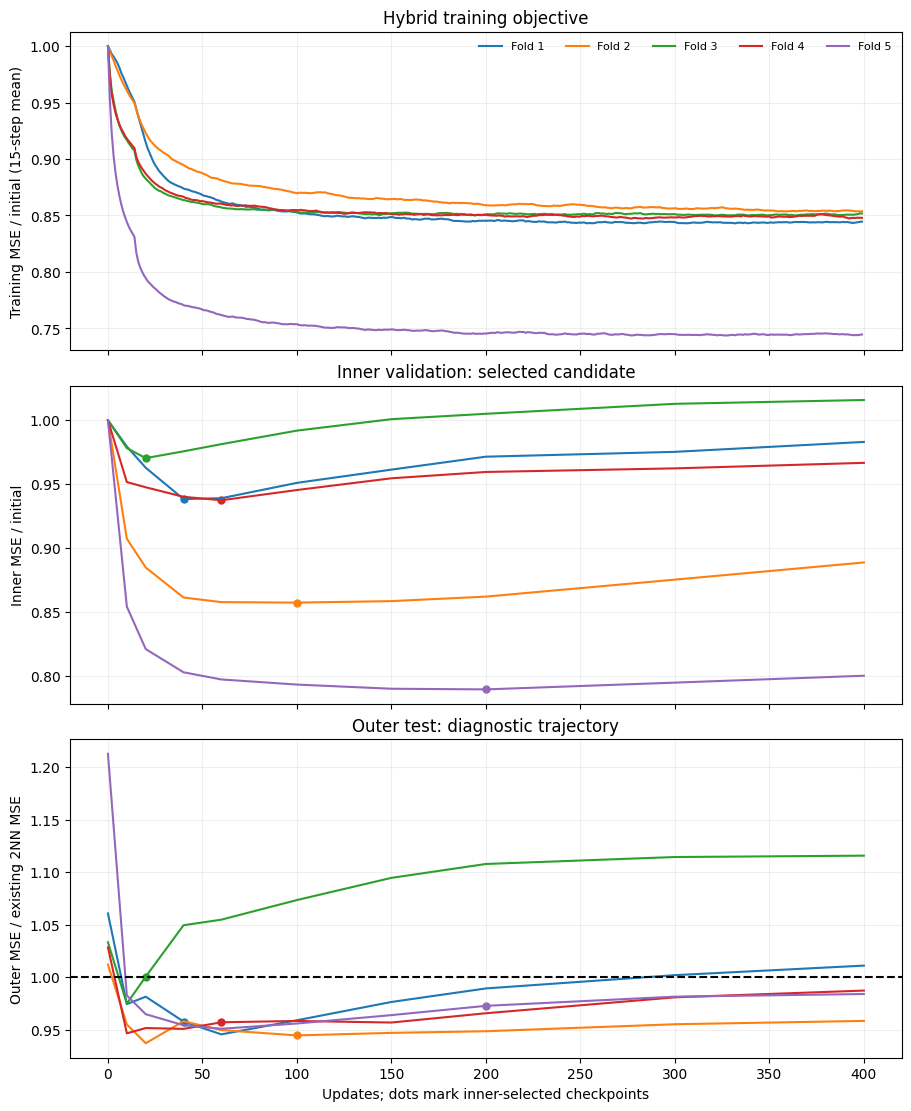

HYBRID_HP_CHOICES  fold            batch    variant  ridge  deviation_ridge  linear_reg  features  width      lr  weight_decay           candidate  selected_step  inner_mse  n_candidates                                                        promoted  baseline_2nn_inner_mse  baseline_2nn_selected_step  baseline_2nn_reproduced  inner_improvement_vs_2nn_pct
    0 HUVEC-10|plate_1 hybrid_2nn 0.0001         0.010000       0.001        32     64 0.00150        0.0001      hybrid_fast_lr             40   0.001249            18      ['hybrid_deviation_02', 'hybrid_fast_lr', 'hybrid_raw_05']                0.001295                          40                     True                      3.564257
    1 HUVEC-22|plate_4 hybrid_2nn 0.0001         0.000100       0.000        64     64 0.00025        0.0001      hybrid_slow_lr            100   0.001238            18      ['hybrid_raw_05', 'hybrid_slow_lr', 'hybrid_weight_decay']                0.001285                         100                  

HYBRID_LEARNING_AUDIT  fold            batch  selected_step  selection_matches_inner_minimum  linear_reg  ridge  deviation_ridge  features  width      lr  weight_decay  features_at_upper_boundary  step_at_upper_boundary  training_drop_first20_last20_pct  selected_mse  step400_mse  step400_vs_selected_pct  selected_vs_2nn_pct  raw_linear_coefficient_norm
    0 HUVEC-10|plate_1             40                             True       0.001 0.0001         0.010000        32     64 0.00150        0.0001                       False                   False                          9.892397      0.000955     0.001008                 5.564907            -4.231661                     1.724066
    1 HUVEC-22|plate_4            100                             True       0.000 0.0001         0.000100        64     64 0.00025        0.0001                        True                   False                          9.217102      0.001181     0.001198                 1.464697            -5.552483      

HYBRID_VERIFIED_COMPLETE /nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_hybrid_2nn_positive_plate_hp_20261118T154549800734Z


In [2]:
HYBRID_ORDER=["linear","ridge linear","additive","shared + deviation (2 NNs)","per-x NN",HYBRID_NAME]
hybrid_all=pd.read_csv(hybrid_dir / "combined_scores.csv",float_precision="round_trip")
hybrid_selected=pd.read_csv(hybrid_dir / "selected_hyperparameters.csv",float_precision="round_trip")
hybrid_curves=pd.read_csv(hybrid_dir / "outer_learning_curves.csv",float_precision="round_trip")
assert set(hybrid_all.model)==set(HYBRID_ORDER)
assert hybrid_all.groupby("model").batch.nunique().eq(5).all()
assert len(hybrid_selected)==5 and np.isfinite(hybrid_all.value).all()
keys=["batch","perturbation","metric"]
assert not hybrid_all.duplicated(keys+["model"]).any()
reference=hybrid_all.loc[hybrid_all.model.eq("linear")].sort_values(keys).reset_index(drop=True)
for name in HYBRID_ORDER[1:]:
    other=hybrid_all.loc[hybrid_all.model.eq(name)].sort_values(keys).reset_index(drop=True)
    for col in keys+["n_training_batches","n_treatment_crops"]:assert reference[col].equals(other[col]),(name,col)
hybrid_by_fold=hybrid_all.groupby(["fold","batch","model"]).value.mean().unstack("model")[HYBRID_ORDER].sort_index()
hybrid_means=hybrid_by_fold.mean().rename("mse")
hybrid_by_fold.to_csv(hybrid_dir / "per_fold_mse.csv");hybrid_means.to_csv(hybrid_dir / "average_mse.csv")
def hybrid_bold_best(row):return ["font-weight:bold;" if np.isclose(v,row.min(),rtol=1e-9,atol=1e-12) else "" for v in row]
display((hybrid_by_fold*1000).style.apply(hybrid_bold_best,axis=1).format("{:.6f}"))
display((hybrid_means.to_frame().T*1000).style.apply(hybrid_bold_best,axis=1).format("{:.6f}"))
print("HYBRID_FINAL_TABLE_X1000",(hybrid_by_fold*1000).to_string(),flush=True)
print("HYBRID_MEANS",hybrid_means.to_dict(),flush=True)
fig,axes=plt.subplots(3,1,figsize=(9,11),sharex=True,layout="constrained")
hybrid_audit=[];hybrid_trial_rows=[]
for fold in range(5):
    d=hybrid_dir / f"fold_{fold+1}";locked=json.loads((d / "locked_selection.json").read_text())
    split=json.loads((d / "split.json").read_text())
    assert split==json.loads((HYBRID_NN_REFERENCE / "positive_plate" / f"fold_{fold+1}" / "split.json").read_text())
    assert set(split["inner_training_batches"]).isdisjoint(split["inner_validation_batches"])
    assert split["outer_batch"] not in split["outer_training_batches"]
    observed=[];fold_trials=0
    for f in sorted((d / "trials").glob("*_status.json")):
        status=json.loads(f.read_text());fold_trials+=1
        t=pd.read_csv(f.with_name(f.name.replace("_status.json","_curves.csv")),float_precision="round_trip")
        assert set(t.batch)==set(split["inner_validation_batches"])
        assert not t.duplicated(["batch","step"]).any() and t.groupby("step").batch.nunique().eq(4).all()
        if status["failed"] is None:
            assert np.isfinite(t[["training_mse","validation_mse"]]).all().all()
            mean=t.groupby("step").validation_mse.mean()
            np.testing.assert_allclose(status["inner_mse"],mean.min(),rtol=1e-12)
            observed.append(float(mean.min()))
        hybrid_trial_rows.append({"fold":fold,**status})
        if status["candidate"]==locked["candidate"]:
            inner=t.groupby("step").validation_mse.mean()
            np.testing.assert_allclose(inner.loc[locked["selected_step"]],locked["inner_mse"],rtol=1e-12)
    assert fold_trials==locked["n_candidates"]
    np.testing.assert_allclose(locked["inner_mse"],min(observed),rtol=1e-12)
    assert locked["baseline_2nn_reproduced"] and locked["inner_mse"]<=locked["baseline_2nn_inner_mse"]+1e-15
    saved=torch.load(d / "hybrid_selected.pt",map_location="cpu",weights_only=False,mmap=True)
    assert saved["selection"]==locked
    for key in ["a","b_shared_nn","c_deviation_nn","raw_linear_coef"]:assert torch.isfinite(saved[key]).all().item()
    assert saved["raw_linear_coef"].shape==(384,)
    assert all(torch.isfinite(v).all().item() for v in saved["psi_state_dict"].values())
    train=pd.read_csv(d / "training.csv")
    assert train.step.tolist()==list(range(400)) and np.isfinite(train.training_mse).all()
    outer=hybrid_curves.loc[hybrid_curves.fold.eq(fold)].sort_values("step")
    assert outer.step.tolist()==list(HP_CHECKPOINTS)
    stop=int(locked["selected_step"]);selected=outer.loc[outer.step.eq(stop)].iloc[0];last=outer.iloc[-1]
    np.testing.assert_allclose(selected.validation_mse,hybrid_by_fold.loc[(fold,split["outer_batch"]),HYBRID_NAME],rtol=1e-6)
    early,late=train.training_mse.iloc[:20].mean(),train.training_mse.iloc[-20:].mean()
    hybrid_audit.append({"fold":fold,"batch":split["outer_batch"],"selected_step":stop,
        "selection_matches_inner_minimum":True,"linear_reg":locked["linear_reg"],"ridge":locked["ridge"],
        "deviation_ridge":locked["deviation_ridge"],"features":locked["features"],"width":locked["width"],
        "lr":locked["lr"],"weight_decay":locked["weight_decay"],"features_at_upper_boundary":locked["features"]==64,
        "step_at_upper_boundary":stop==400,"training_drop_first20_last20_pct":100*(1-late/early),
        "selected_mse":selected.validation_mse,"step400_mse":last.validation_mse,
        "step400_vs_selected_pct":100*(last.validation_mse/selected.validation_mse-1),
        "selected_vs_2nn_pct":100*(selected.validation_mse/selected.two_nn_mse-1),
        "raw_linear_coefficient_norm":float(saved["raw_linear_coef"].norm().item())})
    color=f"C{fold}"
    axes[0].plot(train.step,train.training_mse.rolling(15,min_periods=1).mean()/train.training_mse.iloc[0],color=color,label=f"Fold {fold+1}")
    axes[1].plot(inner.index,inner/inner.iloc[0],color=color);axes[1].scatter([stop],[inner.loc[stop]/inner.iloc[0]],color=color,s=25)
    axes[2].plot(outer.step,outer.validation_mse/outer.two_nn_mse,color=color)
    axes[2].scatter([stop],[selected.validation_mse/selected.two_nn_mse],color=color,s=25)
    del saved
pd.DataFrame(hybrid_audit).to_csv(hybrid_dir / "learning_and_selection_audit.csv",index=False)
pd.DataFrame(hybrid_trial_rows).to_csv(hybrid_dir / "all_trial_statuses.csv",index=False)
for ax,title,ylabel in zip(axes,["Hybrid training objective","Inner validation: selected candidate","Outer test: diagnostic trajectory"],
    ["Training MSE / initial (15-step mean)","Inner MSE / initial","Outer MSE / existing 2NN MSE"]):
    ax.set_title(title);ax.set_ylabel(ylabel);ax.grid(alpha=.2)
axes[0].legend(frameon=False,ncol=5,fontsize=8)
axes[2].axhline(1,color="black",ls="--");axes[2].set_xlabel("Updates; dots mark inner-selected checkpoints")
fig.savefig(hybrid_dir / "hybrid_learning_curves.png",dpi=180,bbox_inches="tight")
plt.show();plt.close(fig)
assert all(hashlib.sha256(Path(p).read_bytes()).hexdigest()==v for p,v in hybrid_manifest["source_hashes"].items())
print("HYBRID_HP_CHOICES",hybrid_selected.to_string(index=False),flush=True)
print("HYBRID_LEARNING_AUDIT",pd.DataFrame(hybrid_audit).to_string(index=False),flush=True)
print("HYBRID_VERIFIED_COMPLETE",hybrid_dir,flush=True)


## Completed hybrid comparison and collected results

The following cells regenerate the six-model report and collect scores, hyperparameters and learning curves for HUVEC, positive-control-only proxies, and plate batches. Earlier five-model coverage analysis is retained separately.

In [2]:
# Regenerate the six-model report from the saved, audited results.
from pathlib import Path
from datetime import datetime, timezone
import json
import numpy as np
import pandas as pd
import nbformat
from IPython.display import display, Markdown

ROOT = Path("/nfs/ghome/live/adhir/genetic_playground")
report_notebook = nbformat.read(ROOT / "notebooks/rxrx1_per_perturbation_bridge_training.ipynb", as_version=4)
report_run = Path(report_notebook.metadata["rxrx1_hybrid_hp_run"]["output_dir"])
assert report_notebook.metadata["rxrx1_hybrid_hp_run"]["status"] == "complete"
names = ["linear", "ridge linear", "additive", "shared + deviation (2 NNs)", "per-x NN", "linear + shared/deviation 2NN"]
labels = ["Linear", "Ridge linear", "Additive NN", "Shared 2NN", "Per-x NN", "Hybrid 2NN"]
report_scores = pd.read_csv(report_run / "combined_scores.csv", float_precision="round_trip")
report_folds = report_scores.groupby(["fold", "batch", "model"]).value.mean().unstack("model")[names]
report_mean = report_folds.mean()
assert report_folds.shape == (5, 6) and np.isfinite(report_folds).all().all()
report_audit = pd.read_csv(report_run / "learning_and_selection_audit.csv")
report_hp = pd.read_csv(report_run / "selected_hyperparameters.csv", float_precision="round_trip")
report_trials = pd.read_csv(report_run / "all_trial_statuses.csv")
report_params = pd.read_csv(report_run / "network_parameter_audit.csv")
assert report_audit.selection_matches_inner_minimum.all() and report_hp.baseline_2nn_reproduced.all()
assert len(report_params) == 10 and report_params.finite_weights.all()
assert report_params.relative_parameter_change.gt(0).all()
hy = names[-1]
bt = chr(96)
def report_values(row):
    best = min(row)
    return " | ".join(("**" + f"{v*1000:.6f}" + "**") if np.isclose(v, best, rtol=1e-9, atol=1e-12) else f"{v*1000:.6f}" for v in row)

report_lines = [
    "# RxRx1 HUVEC: positive proxies, plate batches — six-model comparison", "",
    "All models use the same five outer test plates and matching treatment targets. Scores average squared error over 384 embedding coordinates, then equally over perturbations within a fold. The mean weights folds equally. **MSE × 1,000; lower is better. Bold marks the best value in each row.**", "",
    "| Fold / held-out plate | " + " | ".join(labels) + " |",
    "|---|" + "---:|" * 6,
]
for (fold, batch), row in report_folds.iterrows():
    report_lines.append(f"| {int(fold)+1}: {batch.replace('|', ' / ')} | {report_values(row)} |")
report_lines += [
    "| Mean | " + report_values(report_mean) + " |", "",
    f"The hybrid has the lowest mean MSE: {report_mean[hy]*1000:.6f} × 10⁻³. It improves on shared 2NN by {100*(1-report_mean[hy]/report_mean[names[3]]):.2f}% and linear by {100*(1-report_mean[hy]/report_mean['linear']):.2f}%. Shared 2NN is slightly better on fold 3; the hybrid is best on the other four folds.", "",
    "## Hybrid comparison", "",
    "The hybrid adds a coordinate-wise raw-proxy mean term to two independent learned proxy embeddings. All readouts are fitted jointly by ridge regression inside the differentiable neural loss.", "",
    "| Compared with | Hybrid MSE reduction (%) | Folds with lower hybrid MSE |", "|---|---:|---:|",
]
for model, label in zip(names[:-1], labels[:-1]):
    report_lines.append(f"| {label} | {100*(1-report_mean[hy]/report_mean[model]):.2f} | {int((report_folds[hy]<report_folds[model]-1e-12).sum())}/5 |")
report_lines += [
    "", "Positive reductions mean the hybrid is better. This is a paired exploratory comparison on reused outer folds.", "",
    "## Models run in this positive-proxy/plate comparison", "",
    "Write $\\mu_e=\\mathbb E[\\widetilde W\\mid e]$ for training-standardised proxy means and $z_e^{(k)}=\\mathbb E[\\phi_{\\theta_k}(\\widetilde W)\\mid e]$ for learned embeddings. NN targets are centred using training data; the training mean $\\bar Y_g$ is restored.", "",
    "| Model | Prediction for output coordinate $g$ |", "|---|---|",
    "| Linear | $a_{xg}+\\beta_g\\mu_{eg}$, unregularised coordinate-wise slope |",
    "| Ridge linear | Same formula, inner-tuned slope ridge; unpenalised intercepts |",
    "| Additive NN | $\\bar Y_g+a_{xg}+b_g^\\top z_e$ |",
    "| Shared 2NN | $\\bar Y_g+a_{xg}+c_g^\\top z_e^{(1)}+d_{xg}^\\top z_e^{(2)}$ |",
    "| Per-x NN | $\\bar Y_g+A_{xg}^\\top z_e$, no explicit shared or intercept block |",
    "| Hybrid 2NN | $\\bar Y_g+a_{xg}+\\beta_g\\mu_{eg}+c_g^\\top z_e^{(1)}+d_{xg}^\\top z_e^{(2)}$ |", "",
    "The shared and deviation embeddings have independent parameters. The hybrid raw-linear coefficient is coordinate-wise, matching the existing linear baseline.", "",
    "## Hyperparameter and checkpoint selection", "",
    "For each outer fold, four inner validation plates are held out from the 95 outer-training plates. The staged search screens candidates to 100 updates, then continues the two leading candidates and original 2NN reference to 400. Candidate and checkpoint selection use equal-inner-plate MSE only. The selection is saved before outer evaluation. A fresh model is fitted on all 95 outer-training plates; its preselected checkpoint is restored and all readouts are recomputed. The remainder of the 400-update trajectory is diagnostic. There is no patience-based stopping rule.", "",
    "All three hybrid ridge penalties are tuned, using the same sample-count scaling as the notebook loss. The staged search also checks capacity, learning rate and weight decay; it is bounded rather than exhaustive.", "",
    "| Fold | Shared/intercept ridge | Deviation ridge | Raw-linear ridge | Features / width | LR | Weight decay | Selected updates |", "|---:|---:|---:|---:|---|---:|---:|---:|",
]
for _, row in report_hp.sort_values("fold").iterrows():
    report_lines.append(f"| {int(row.fold)+1} | {row.ridge:.3g} | {row.deviation_ridge:.3g} | {float(row.linear_reg):.6g} | {int(row.features)} / {int(row.width)} | {row.lr:.4g} | {row.weight_decay:.3g} | {int(row.selected_step)} |")
report_lines += [
    "", "## Implementation and learning-curve checks", "",
    f"- {len(report_trials)} candidate configurations were evaluated; {int(report_trials.failed.notna().sum())} recorded a failed trial.",
    "- Full-design reference checks verified the compact ridge solve, held-out errors and embedding gradients. Infinite raw ridge reproduced the original 2NN implementation.",
    "- The original 2NN's inner score and stopping step were reproduced in every fold. All selections match the best observed inner score. Saved coefficients and weights are finite; both networks changed their parameters.",
    f"- Training objectives decreased in every fold and then flattened. The final 20 updates averaged {report_audit.training_drop_first20_last20_pct.min():.1f}–{report_audit.training_drop_first20_last20_pct.max():.1f}% below the first 20 updates. Visual inspection of the saved curves shows validation losses rising after their early minima, consistent with overfitting rather than a failure to train.",
    f"- No fold selected the 400-update limit. Using update 400 would worsen outer MSE in all five folds, by {report_audit.step400_vs_selected_pct.min():.2f}–{report_audit.step400_vs_selected_pct.max():.2f}% compared with the preselected checkpoints. Outer curves did not select checkpoints.",
    "- The search selected boundary settings in some folds: 64 features in fold 2, the highest learning rate in fold 1, the largest shared/intercept ridge in fold 5, and extreme deviation-ridge values in folds 1, 3 and 4. These are the best observed settings in this bounded search, not globally optimal HPs.",
    f"- {int(np.isinf(report_hp.linear_reg.astype(float)).sum())}/5 selections disabled the raw-linear term with infinite raw ridge.", "",
    "See [all four NN curves](learning_curves/nn_training_and_validation.png), [hybrid diagnostics](learning_curves/hybrid_training_and_validation.png), and [selected HPs](hyperparameters/hybrid_2nn.csv). Full audits and every trial curve are in " + bt + "hybrid_2nn/" + bt + ".", "",
    "## Artifacts and scope", "",
    f"Hybrid source run: {bt}{report_run}{bt}. Selected models remain in {bt}fold_N/hybrid_selected.pt{bt} there. All five training folds finished by 02:54 UTC on 19 November 2026. The SSH interruption caused the reporting process to raise BrokenPipeError; the saved-results analysis was recovered and verified without retraining.", "",
    "Model modules and scripts were not edited; implementation and reporting code are in the RxRx1 notebook. All data and artifacts remain on u434a.", "",
    "The separate [linear/2NN proxy and batch ablations](../rxrx1_linear_2nn_ablations/README.md) include negative/positive proxies and experiment/plate batches, with fixed-HP and tuned results separated. This folder remains positive proxies and plate batches only. Earlier five-model coverage analysis is retained separately and does not include the hybrid.", "",
]
hybrid_report = "\n".join(report_lines)
notebook_report = hybrid_report.replace("](learning_curves/", "](../outputs/rxrx1_results/learning_curves/").replace("](hyperparameters/", "](../outputs/rxrx1_results/hyperparameters/").replace("](../rxrx1_linear_2nn_ablations/", "](../outputs/rxrx1_linear_2nn_ablations/")
display(Markdown(notebook_report))
print("HYBRID_REPORT_READY", len(report_trials), "trials; mean MSE", report_mean[hy], flush=True)


# RxRx1 HUVEC: positive proxies, plate batches — six-model comparison

All models use the same five outer test plates and matching treatment targets. Scores average squared error over 384 embedding coordinates, then equally over perturbations within a fold. The mean weights folds equally. **MSE × 1,000; lower is better. Bold marks the best value in each row.**

| Fold / held-out plate | Linear | Ridge linear | Additive NN | Shared 2NN | Per-x NN | Hybrid 2NN |
|---|---:|---:|---:|---:|---:|---:|
| 1: HUVEC-10 / plate_1 | 1.043009 | 1.029303 | 1.040027 | 0.997473 | 1.170660 | **0.955263** |
| 2: HUVEC-22 / plate_4 | 1.247679 | 1.254621 | 1.255837 | 1.250467 | 1.415586 | **1.181035** |
| 3: HUVEC-02 / plate_2 | 1.393898 | 1.393929 | 1.405553 | **1.265587** | 1.336509 | 1.266212 |
| 4: HUVEC-04 / plate_2 | 1.189483 | 1.191870 | 1.220399 | 1.056429 | 1.197740 | **1.010993** |
| 5: HUVEC-14 / plate_1 | 1.601455 | 1.601455 | 1.711028 | 1.571348 | 1.721080 | **1.528389** |
| Mean | 1.295105 | 1.294235 | 1.326569 | 1.228261 | 1.368315 | **1.188378** |

The hybrid has the lowest mean MSE: 1.188378 × 10⁻³. It improves on shared 2NN by 3.25% and linear by 8.24%. Shared 2NN is slightly better on fold 3; the hybrid is best on the other four folds.

## Hybrid comparison

The hybrid adds a coordinate-wise raw-proxy mean term to two independent learned proxy embeddings. All readouts are fitted jointly by ridge regression inside the differentiable neural loss.

| Compared with | Hybrid MSE reduction (%) | Folds with lower hybrid MSE |
|---|---:|---:|
| Linear | 8.24 | 5/5 |
| Ridge linear | 8.18 | 5/5 |
| Additive NN | 10.42 | 5/5 |
| Shared 2NN | 3.25 | 4/5 |
| Per-x NN | 13.15 | 5/5 |

Positive reductions mean the hybrid is better. This is a paired exploratory comparison on reused outer folds.

## Models run in this positive-proxy/plate comparison

Write $\mu_e=\mathbb E[\widetilde W\mid e]$ for training-standardised proxy means and $z_e^{(k)}=\mathbb E[\phi_{\theta_k}(\widetilde W)\mid e]$ for learned embeddings. NN targets are centred using training data; the training mean $\bar Y_g$ is restored.

| Model | Prediction for output coordinate $g$ |
|---|---|
| Linear | $a_{xg}+\beta_g\mu_{eg}$, unregularised coordinate-wise slope |
| Ridge linear | Same formula, inner-tuned slope ridge; unpenalised intercepts |
| Additive NN | $\bar Y_g+a_{xg}+b_g^\top z_e$ |
| Shared 2NN | $\bar Y_g+a_{xg}+c_g^\top z_e^{(1)}+d_{xg}^\top z_e^{(2)}$ |
| Per-x NN | $\bar Y_g+A_{xg}^\top z_e$, no explicit shared or intercept block |
| Hybrid 2NN | $\bar Y_g+a_{xg}+\beta_g\mu_{eg}+c_g^\top z_e^{(1)}+d_{xg}^\top z_e^{(2)}$ |

The shared and deviation embeddings have independent parameters. The hybrid raw-linear coefficient is coordinate-wise, matching the existing linear baseline.

## Hyperparameter and checkpoint selection

For each outer fold, four inner validation plates are held out from the 95 outer-training plates. The staged search screens candidates to 100 updates, then continues the two leading candidates and original 2NN reference to 400. Candidate and checkpoint selection use equal-inner-plate MSE only. The selection is saved before outer evaluation. A fresh model is fitted on all 95 outer-training plates; its preselected checkpoint is restored and all readouts are recomputed. The remainder of the 400-update trajectory is diagnostic. There is no patience-based stopping rule.

All three hybrid ridge penalties are tuned, using the same sample-count scaling as the notebook loss. The staged search also checks capacity, learning rate and weight decay; it is bounded rather than exhaustive.

| Fold | Shared/intercept ridge | Deviation ridge | Raw-linear ridge | Features / width | LR | Weight decay | Selected updates |
|---:|---:|---:|---:|---|---:|---:|---:|
| 1 | 0.0001 | 0.01 | 0.001 | 32 / 64 | 0.0015 | 0.0001 | 40 |
| 2 | 0.0001 | 0.0001 | 0 | 64 / 64 | 0.00025 | 0.0001 | 100 |
| 3 | 0.0001 | 1e-06 | 0 | 32 / 64 | 0.00075 | 0.1 | 20 |
| 4 | 0.0001 | 1e-06 | 0.001 | 16 / 32 | 0.00075 | 0.1 | 60 |
| 5 | 0.001 | 0.0001 | 0 | 32 / 64 | 0.00075 | 0.1 | 200 |

## Implementation and learning-curve checks

- 89 candidate configurations were evaluated; 0 recorded a failed trial.
- Full-design reference checks verified the compact ridge solve, held-out errors and embedding gradients. Infinite raw ridge reproduced the original 2NN implementation.
- The original 2NN's inner score and stopping step were reproduced in every fold. All selections match the best observed inner score. Saved coefficients and weights are finite; both networks changed their parameters.
- Training objectives decreased in every fold and then flattened. The final 20 updates averaged 5.3–9.9% below the first 20 updates. Visual inspection of the saved curves shows validation losses rising after their early minima, consistent with overfitting rather than a failure to train.
- No fold selected the 400-update limit. Using update 400 would worsen outer MSE in all five folds, by 1.16–11.52% compared with the preselected checkpoints. Outer curves did not select checkpoints.
- The search selected boundary settings in some folds: 64 features in fold 2, the highest learning rate in fold 1, the largest shared/intercept ridge in fold 5, and extreme deviation-ridge values in folds 1, 3 and 4. These are the best observed settings in this bounded search, not globally optimal HPs.
- 0/5 selections disabled the raw-linear term with infinite raw ridge.

See [all four NN curves](../outputs/rxrx1_results/learning_curves/nn_training_and_validation.png), [hybrid diagnostics](../outputs/rxrx1_results/learning_curves/hybrid_training_and_validation.png), and [selected HPs](../outputs/rxrx1_results/hyperparameters/hybrid_2nn.csv). Full audits and every trial curve are in `hybrid_2nn/`.

## Artifacts and scope

Hybrid source run: `/nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_hybrid_2nn_positive_plate_hp_20261118T154549800734Z`. Selected models remain in `fold_N/hybrid_selected.pt` there. All five training folds finished by 02:54 UTC on 19 November 2026. The SSH interruption caused the reporting process to raise BrokenPipeError; the saved-results analysis was recovered and verified without retraining.

Model modules and scripts were not edited; implementation and reporting code are in the RxRx1 notebook. All data and artifacts remain on u434a.

The separate [linear/2NN proxy and batch ablations](../outputs/rxrx1_linear_2nn_ablations/README.md) include negative/positive proxies and experiment/plate batches, with fixed-HP and tuned results separated. This folder remains positive proxies and plate batches only. Earlier five-model coverage analysis is retained separately and does not include the hybrid.


HYBRID_REPORT_READY 89 trials; mean MSE 0.0011883783412808021


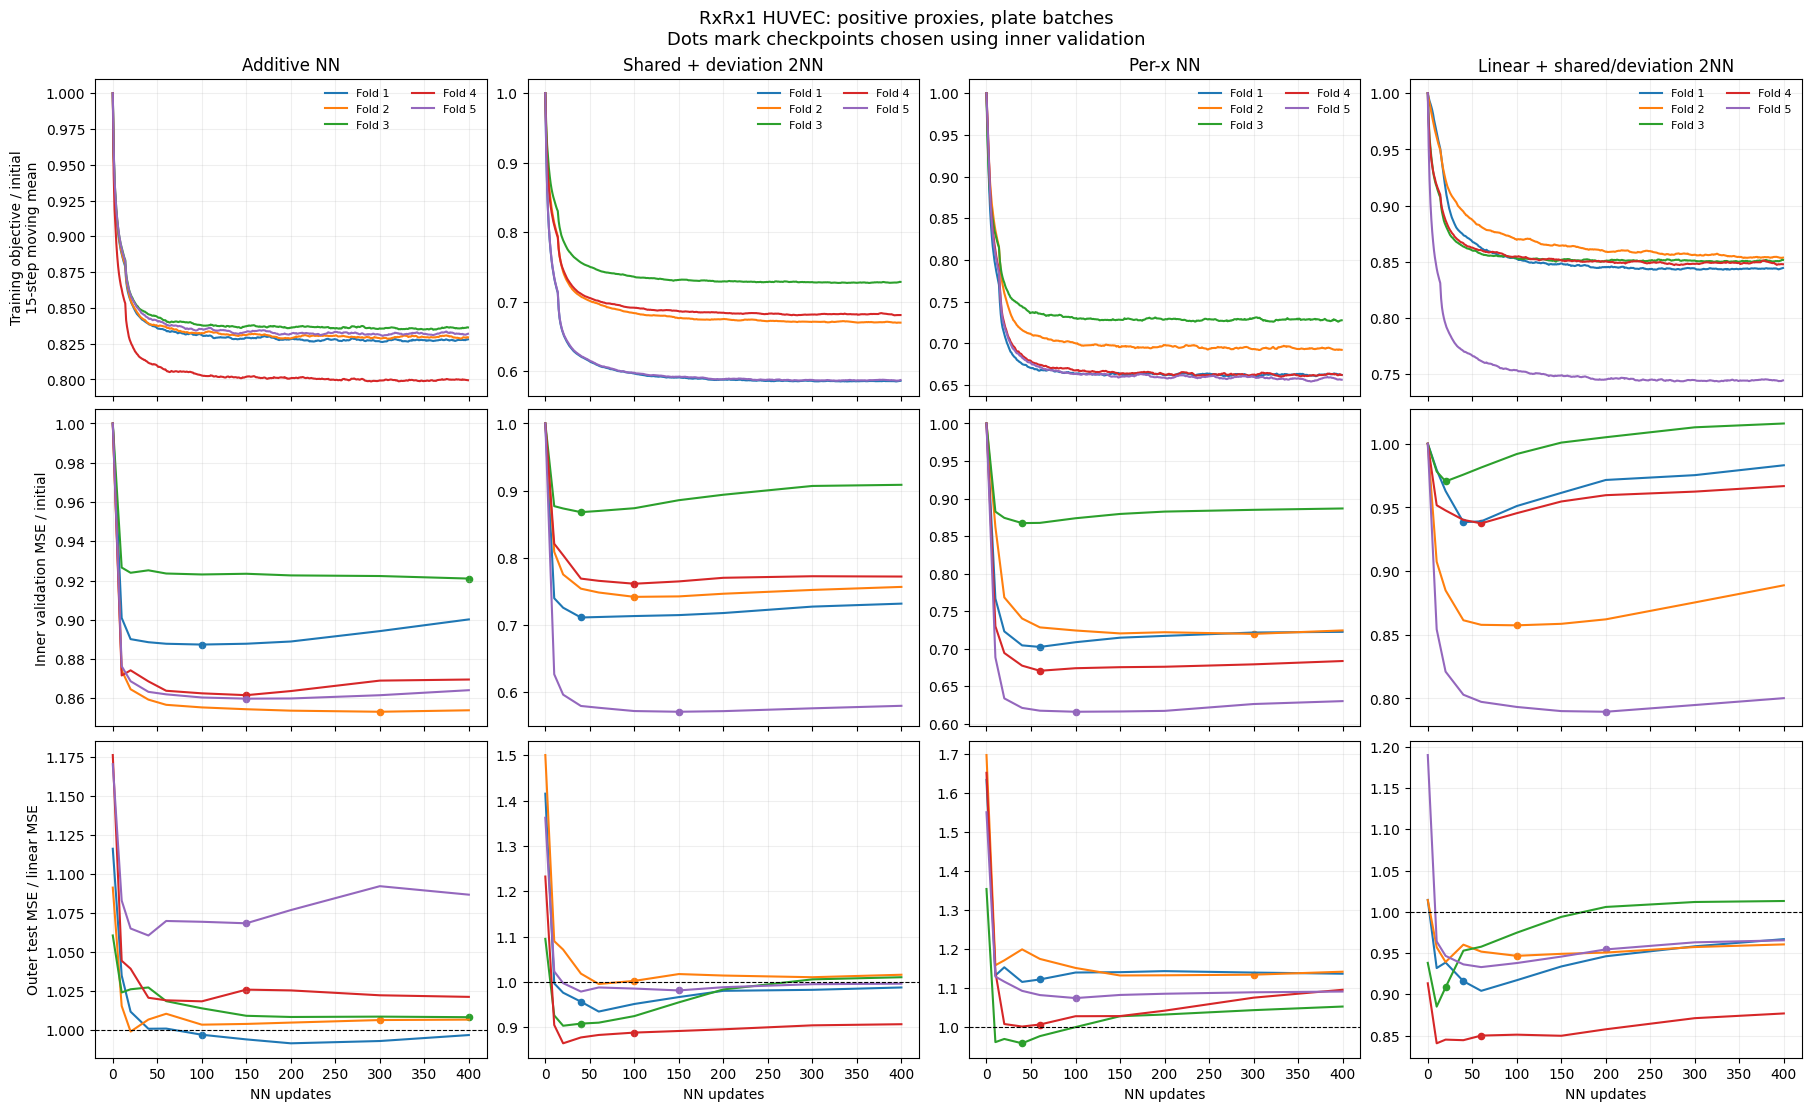

RXRX1_RESULTS_COLLECTED /nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_results {"updated_utc": "2026-11-19T11:31:52.050431+00:00", "scope": {"cell_type": "HUVEC", "proxy_mode": "positive_only", "batch_unit": "plate"}, "sources": {"tuned_nn": "/nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_nested_hp_20261118T111217794502Z/positive_plate", "per_x": "/nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_perx_positive_plate_hp_20261118T140833109911Z", "ridge_linear": "/nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_ridge_linear_positive_plate_hp_20261118T152406164238Z", "hybrid_2nn": "/nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_hybrid_2nn_positive_plate_hp_20261118T154549800734Z", "untuned_positive_plate": "/nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_proxy_plate_ablations_20261118T100925512931Z/positive_plate"}, "latest_scores_source": "/nfs/ghome/live/adhir/genetic_playground/outputs/rxrx1_huvec_hybrid_2nn_positiv

In [3]:
# Consolidated artifacts for HUVEC + positive-only proxies + plate batches ONLY.
import shutil
import hashlib
import json
import nbformat

RXRX1_RESULTS = ROOT / "outputs/rxrx1_results"
RXRX1_RESULTS.mkdir(exist_ok=True)
collection_notebook=nbformat.read(ROOT / "notebooks/rxrx1_per_perturbation_bridge_training.ipynb",as_version=4)
collection_hp=Path(collection_notebook.metadata["rxrx1_hp_run"]["output_dir"])
collection_perx=Path(collection_notebook.metadata["rxrx1_perx_hp_run"]["output_dir"])
collection_ridge=Path(collection_notebook.metadata["rxrx1_ridge_linear_hp_run"]["output_dir"])
collection_hybrid=Path(collection_notebook.metadata["rxrx1_hybrid_hp_run"]["output_dir"])
assert collection_notebook.metadata["rxrx1_hybrid_hp_run"]["status"]=="complete"
collection_untuned=ROOT / "outputs/rxrx1_huvec_proxy_plate_ablations_20261118T100925512931Z/positive_plate"
assert collection_notebook.metadata["rxrx1_ridge_linear_hp_run"]["status"]=="complete"
collection_sources={"tuned_nn":collection_hp / "positive_plate", "per_x":collection_perx,
                    "ridge_linear":collection_ridge, "hybrid_2nn":collection_hybrid, "untuned_positive_plate":collection_untuned}
collection_files=[]
def collection_copy(source,dest):
    dest.parent.mkdir(parents=True,exist_ok=True)
    shutil.copy2(source,dest)
    digest=hashlib.sha256(source.read_bytes()).hexdigest()
    assert hashlib.sha256(dest.read_bytes()).hexdigest()==digest
    collection_files.append({"path":str(dest.relative_to(RXRX1_RESULTS)),"source":str(source),
                             "operation":"copy","sha256":digest,"bytes":dest.stat().st_size})

def collection_table(source,dest,table):
    dest.parent.mkdir(parents=True,exist_ok=True);table.to_csv(dest,index=False)
    collection_files.append({"path":str(dest.relative_to(RXRX1_RESULTS)),"source":str(source),
                             "operation":"positive_plate_filter","sha256":hashlib.sha256(dest.read_bytes()).hexdigest(),"bytes":dest.stat().st_size})

for name,src in collection_sources.items():
    assert src.exists()
    for f in sorted(src.rglob("*")):
        if f.is_file() and f.suffix.lower() in {".csv",".png",".svg",".pdf",".json",".yaml",".yml"}:
            collection_copy(f,RXRX1_RESULTS / name / f.relative_to(src))

# The NN suite contains three conditions: explicitly subset every shared table.
for name in ["scores.csv","selected_hyperparameters.csv","outer_learning_curves.csv",
             "network_parameter_audit.csv","learning_curve_audit.csv","hyperparameter_selection_audit.csv",
             "all_trial_statuses.csv","coverage_summary.csv","per_fold_mse.csv","average_mse.csv"]:
    source=collection_hp / name
    t=pd.read_csv(source,float_precision="round_trip")
    assert "ablation" in t
    subset=t.loc[t.ablation.eq("positive_plate")].copy();assert len(subset)>0
    collection_table(source,RXRX1_RESULTS / "tuned_nn" / name,subset)

# Top-level scores represent the completed six-model comparison. Earlier coverage analysis remains labelled as five-model history.
for source_name,dest_name in [("combined_scores.csv","scores.csv"),("per_fold_mse.csv","per_fold_mse.csv"),
                              ("average_mse.csv","average_mse.csv")]:
    collection_copy(collection_hybrid / source_name,RXRX1_RESULTS / dest_name)
for name,src in [("nn",collection_hp),("per_x",collection_perx),("ridge_linear",collection_ridge),("hybrid_2nn",collection_hybrid)]:
    t=pd.read_csv(src / "selected_hyperparameters.csv",float_precision="round_trip")
    if "ablation" in t:t=t.loc[t.ablation.eq("positive_plate")].copy()
    collection_table(src / "selected_hyperparameters.csv",RXRX1_RESULTS / "hyperparameters" / f"{name}.csv",t)

collection_train=[]
collection_outer=[]
collection_inner=[]
collection_model_labels={"additive":"Additive NN","shared + deviation (2 NNs)":"Shared + deviation 2NN","per-x NN":"Per-x NN","linear + shared/deviation 2NN":"Linear + shared/deviation 2NN"}
for fold in range(5):
    d=collection_hp / "positive_plate" / f"fold_{fold+1}"
    split=json.loads((d / "split.json").read_text());batch=split["outer_batch"]
    selections=json.loads((d / "locked_selection.json").read_text())
    for variant,model in [("additive","additive"),("shared_2nn","shared + deviation (2 NNs)")]:
        chosen=selections[variant]
        t=pd.read_csv(d / f"{variant}_training.csv").assign(fold=fold,batch=batch,model=model)
        collection_train.append(t)
        curve=pd.read_csv(d / f"{variant}_outer_curves.csv");collection_outer.append(curve)
        inner=pd.read_csv(d / "trials" / f'{chosen["candidate"]}_curves.csv').assign(fold=fold,model=model,selected_step=chosen["selected_step"])
        collection_inner.append(inner)
    px=collection_perx / f"fold_{fold+1}"
    chosen=json.loads((px / "locked_selection.json").read_text())
    collection_train.append(pd.read_csv(px / "training.csv").assign(fold=fold,batch=batch,model="per-x NN"))
    collection_outer.append(pd.read_csv(px / "outer_curves.csv"))
    collection_inner.append(pd.read_csv(px / "trials" / f'{chosen["candidate"]}_curves.csv').assign(fold=fold,model="per-x NN",selected_step=chosen["selected_step"]))
    hy=collection_hybrid / f"fold_{fold+1}"
    chosen=json.loads((hy / "locked_selection.json").read_text())
    model="linear + shared/deviation 2NN"
    collection_train.append(pd.read_csv(hy / "training.csv").assign(fold=fold,batch=batch,model=model))
    collection_outer.append(pd.read_csv(hy / "outer_curves.csv"))
    collection_inner.append(pd.read_csv(hy / "trials" / f'{chosen["candidate"]}_curves.csv').assign(fold=fold,model=model,selected_step=chosen["selected_step"]))
collection_train=pd.concat(collection_train,ignore_index=True)
collection_outer=pd.concat(collection_outer,ignore_index=True)
collection_inner=pd.concat(collection_inner,ignore_index=True)
for column,value in [("cell_type","HUVEC"),("proxy_mode","positive_only"),("batch_unit","plate")]:
    for t in [collection_train,collection_outer,collection_inner]:t[column]=value
curve_dir=RXRX1_RESULTS / "learning_curves";curve_dir.mkdir(exist_ok=True)
collection_train.to_csv(curve_dir / "training.csv",index=False)
collection_outer.to_csv(curve_dir / "outer_validation.csv",index=False)
collection_inner.to_csv(curve_dir / "inner_validation_selected_candidates.csv",index=False)
assert collection_train.groupby(["model","fold"]).size().eq(400).all()
assert len(collection_train.groupby(["model","fold"]))==20

fig,axes=plt.subplots(3,4,figsize=(18,11),sharex=True,layout="constrained")
for j,model in enumerate(collection_model_labels):
    for fold in range(5):
        train=collection_train.loc[collection_train.model.eq(model)&collection_train.fold.eq(fold)].sort_values("step")
        outer=collection_outer.loc[collection_outer.model.eq(model)&collection_outer.fold.eq(fold)].sort_values("step")
        inner=collection_inner.loc[collection_inner.model.eq(model)&collection_inner.fold.eq(fold)].groupby("step").validation_mse.mean()
        stop=int(outer.selected_step.iloc[0]);color=f"C{fold}"
        axes[0,j].plot(train.step,train.training_mse.rolling(15,min_periods=1).mean()/train.training_mse.iloc[0],color=color,label=f"Fold {fold+1}")
        axes[1,j].plot(inner.index,inner/inner.iloc[0],color=color)
        axes[1,j].scatter([stop],[inner.loc[stop]/inner.iloc[0]],color=color,s=20)
        axes[2,j].plot(outer.step,outer.validation_mse/outer.linear_mse,color=color)
        point=outer.loc[outer.step.eq(stop)].iloc[0]
        axes[2,j].scatter([stop],[point.validation_mse/point.linear_mse],color=color,s=20)
    axes[0,j].set_title(collection_model_labels[model]);axes[0,j].legend(frameon=False,fontsize=8,ncol=2)
    axes[2,j].axhline(1,color="black",ls="--",lw=.8);axes[2,j].set_xlabel("NN updates")
for i,label in enumerate(["Training objective / initial\n15-step moving mean","Inner validation MSE / initial","Outer test MSE / linear MSE"]):
    axes[i,0].set_ylabel(label)
    for ax in axes[i]:ax.grid(alpha=.2)
fig.suptitle("RxRx1 HUVEC: positive proxies, plate batches\nDots mark checkpoints chosen using inner validation",fontsize=13)
fig.savefig(curve_dir / "nn_training_and_validation.png",dpi=180,bbox_inches="tight")
plt.show();plt.close(fig)
collection_copy(collection_ridge / "ridge_validation_curves.png",curve_dir / "ridge_validation.png")
collection_copy(collection_perx / "perx_learning_curves.png",curve_dir / "per_x_training_and_validation.png")
collection_copy(collection_hybrid / "hybrid_learning_curves.png",curve_dir / "hybrid_training_and_validation.png")

# Confirm that every exported CSV with condition labels belongs to this scope.
collection_csv_checks=[]
for f in sorted(RXRX1_RESULTS.rglob("*.csv")):
    if f.name in {"files.csv","csv_scope_audit.csv"}:continue
    t=pd.read_csv(f)
    if "ablation" in t:assert set(t.ablation.dropna())<={"positive_plate"},str(f)
    if "proxy_mode" in t:assert set(t.proxy_mode.dropna())<={"positive_only"},str(f)
    if "batch_unit" in t:assert set(t.batch_unit.dropna())<={"plate"},str(f)
    if "cell_type" in t:assert set(t.cell_type.dropna())<={"HUVEC"},str(f)
    if "well_type" in t:assert set(t.well_type.dropna())<={"positive_control","treatment"},str(f)
    if "batch" in t:
        assert t.batch.dropna().astype(str).str.startswith("HUVEC-").all(),str(f)
        assert t.batch.dropna().astype(str).str.contains("|plate_",regex=False).all(),str(f)
    collection_csv_checks.append({"path":str(f.relative_to(RXRX1_RESULTS)),"rows":len(t),"scope_verified":True})
pd.DataFrame(collection_csv_checks).to_csv(RXRX1_RESULTS / "csv_scope_audit.csv",index=False)
pd.DataFrame(collection_files).to_csv(RXRX1_RESULTS / "files.csv",index=False)
collection_manifest={"updated_utc":datetime.now(timezone.utc).isoformat(),"scope":{"cell_type":"HUVEC","proxy_mode":"positive_only","batch_unit":"plate"},
    "sources":{k:str(v) for k,v in collection_sources.items()},"latest_scores_source":str(collection_hybrid / "combined_scores.csv"),
    "source_models_retained_at_original_paths":True,"copied_or_filtered_files":len(collection_files),"verified_csv_files":len(collection_csv_checks)}
(RXRX1_RESULTS / "manifest.json").write_text(json.dumps(collection_manifest,indent=2))
collection_readme=["# RxRx1: HUVEC, positive proxies, plate batches","",
"This collection contains only positive-control-only proxies with plate-level batches. The latest comparison uses the same five held-out HUVEC plates and inner validation splits for all six models. The top-level tables report tuned, selected checkpoints. Scores are raw MSE; folds are weighted equally in average_mse.csv.","",
"- [Written results and hyperparameter checks](RESULTS.md)","- [Per-fold comparison](per_fold_mse.csv)","- [Average comparison](average_mse.csv)","- [Per-perturbation scores](scores.csv)","- [Earlier five-model coverage analysis](coverage_analysis/README.md)",
"- [All four NN training and validation plots](learning_curves/nn_training_and_validation.png)","- [Raw NN training curves](learning_curves/training.csv)","- [Outer diagnostic curves](learning_curves/outer_validation.csv)","- [Inner curves for selected candidates](learning_curves/inner_validation_selected_candidates.csv)",
"- [Hybrid training and validation plot](learning_curves/hybrid_training_and_validation.png)","- [Ridge validation plot](learning_curves/ridge_validation.png)","- [Selected hyperparameters](hyperparameters/)","",
"## Run-specific detail","",
"- `tuned_nn/`: additive and shared-plus-deviation 2NN, restricted to the positive_plate condition. Includes every inner-trial curve, outer training curve, split, selected HP, and score.",
"- `per_x/`: tuned per-x NN, including every inner-trial curve, final learning curves, scores, and audits.",
"- `ridge_linear/`: ridge-linear penalty search, scores, and audits. Ridge penalises coordinate-wise slopes while leaving perturbation intercepts unpenalised. Its fit is analytic, so it has a penalty-validation curve rather than an iterative training curve.",
"- `hybrid_2nn/`: raw-linear plus shared/deviation 2NN with independent embeddings. Contains all inner trials, selected HPs, outer curves and scores, and implementation/selection/learning audits.",
"- `untuned_positive_plate/`: the earlier 400-update, fixed-HP run for this same condition, explicitly separated from the tuned comparison. Its results are not mixed into the top-level comparison.","",
"NNs were refit on 95 outer-training plates using hyperparameters and stopping steps selected on four inner validation plates. Their full 400-update outer trajectories are diagnostic; the displayed dots and reported scores use the inner-selected checkpoints.","",
"`manifest.json` records original source paths; `files.csv` records copies and filtered exports with hashes; `csv_scope_audit.csv` verifies exported table scope. All source models and original run artifacts remain at their recorded paths. The collection can be refreshed by rerunning the six-model export cell of the RxRx1 notebook. The earlier five-model coverage analysis is retained separately; the hybrid is not included in that historical analysis or by_training_batches.csv.",""]
(RXRX1_RESULTS / "README.md").write_text("\n".join(collection_readme))
(RXRX1_RESULTS / "RESULTS.md").write_text(hybrid_report)
(RXRX1_RESULTS / "manifest.json").write_text(json.dumps({**collection_manifest,
    "models":list(pd.read_csv(RXRX1_RESULTS / "average_mse.csv").model),
    "historical_coverage_models":5,
    "artifact_hashes":{str(p.relative_to(RXRX1_RESULTS)):hashlib.sha256(p.read_bytes()).hexdigest()
        for p in sorted(RXRX1_RESULTS.rglob("*")) if p.is_file() and p.name!="manifest.json"}},indent=2))
print("RXRX1_RESULTS_COLLECTED",str(RXRX1_RESULTS),json.dumps(collection_manifest),flush=True)
